In [ ]:
# Nalopen monte carlo simulatie - proberen om visuele te maken
# Exporteren tabel


# Bakje - niet runnen

In [ ]:
lon=9.7083
lat=45.0583

distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
nearest_idx = distances.argmin().item()
nearest_lon = data.longitude[nearest_idx].item()
nearest_lat = data.latitude[nearest_idx].item()

runoff=river_runoff_time_location_maximum(data, nearest_lon, nearest_lat, second_begin, second_end, '1W')


Infinite values count: 0


In [ ]:
lon=-1.5917
lat=42.0583

distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
nearest_idx = distances.argmin().item()
nearest_lon = data.longitude[nearest_idx].item()
nearest_lat = data.latitude[nearest_idx].item()

runoff_ebro_second=river_runoff_time_location_maximum(data, nearest_lon, nearest_lat, second_begin, second_end, '1W')


Infinite values count: 0


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm
import xarray as xr # Added xarray import

# Step 1: Extract and process raster data

input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/glofas_smaller_dataset/glofas_discharge_eu.nc"

data1 = xr.open_dataset(input_file)
dis06 = data1['dis24'] # Using dis24 as specified by the user
spatial_averages = dis06.mean(dim='time') # Using 'time' dim as specified by the user

# Unstack the 'point' dimension back into 'latitude' and 'longitude'
# This assumes 'point' is a MultiIndex created from latitude and longitude in the original dataset
spatial_averages_unstacked = spatial_averages.unstack('point')

spatial_averages_filtered = spatial_averages_unstacked.where(spatial_averages_unstacked > 50)  # Lower threshold

lat = spatial_averages_unstacked.latitude.values
lon = spatial_averages_unstacked.longitude.values

# Prepare image data for plotting: Flipud for correct vertical alignment with origin='upper'
image_data_for_plot = np.flipud(spatial_averages_filtered.values)

# Step 2: Calculate color range
vmin = np.nanpercentile(image_data_for_plot, 5)
vmax = np.nanpercentile(image_data_for_plot, 99)

# Step 3: Create transparent blue colormap
blues = cm.get_cmap('Blues', 256)
blues_with_alpha = blues(np.linspace(0, 1, 256))
blues_with_alpha[0, -1] = 0  # Make lowest (NaN) fully transparent
blue_cmap = ListedColormap(blues_with_alpha)

# Step 4: Load coastline shapefile
shapefile_path = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/Shapfiles/ne_10m_coastline.zip (Unzipped Files)/ne_10m_coastline.shp"
coastline_gdf = gpd.read_file(shapefile_path)

# Step 5: Plot everything
fig, ax = plt.subplots(figsize=(12, 8))

# Define the extent for imshow: [lon_min, lon_max, lat_min, lat_max]
extent_coords = [lon.min(), lon.max(), lat.min(), lat.max()]

# Thickening effect: multiple shifted overlays
shifts = [
    (-0.15, 0), (0.15, 0),
    (0, -0.15), (0, 0.15),
    (-0.15, -0.15), (-0.15, 0.15),
    (0.15, -0.15), (0.15, 0.15)
]

for dx, dy in shifts:
    ax.imshow(image_data_for_plot,
              extent=[extent_coords[0] + dx, extent_coords[1] + dx,
                      extent_coords[2] + dy, extent_coords[3] + dy],
              origin='upper',
              cmap=blue_cmap,
              vmin=vmin,
              vmax=vmax,
              alpha=0.3,
              aspect='auto',
              zorder=1)

# Main raster layer
im = ax.imshow(image_data_for_plot,
               extent=extent_coords,
               origin='upper',
               cmap=blue_cmap,
               vmin=vmin,
               vmax=vmax,
               alpha=1.0,
               aspect='auto',
               zorder=2)

# Step 6: Coastline
coastline_gdf.plot(ax=ax, color='grey', edgecolor='black', linewidth=1)

# Step 7: River locations with numbers (assuming 'rivers' variable is defined elsewhere)
for river in rivers:
    for i, loc in enumerate(river['locations']):
        label = str(i + 1)
        ax.plot(loc['longitude'], loc['latitude'], 'o', color='red', markersize=6, zorder=5)
        ax.text(loc['longitude'], loc['latitude'], label, color='white', fontsize=7,
                ha='center', va='center', fontweight='bold', zorder=6)

# Set view and style
ax.set_xlim(-25, 50)
ax.set_ylim(30, 73)
plt.colorbar(im, ax=ax, label='Average dis24 value')
ax.set_title('Average dis24 Values (Blue Tints with Thickness & Transparency)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.grid(True)
plt.tight_layout()
plt.show()

ValueError: Dimensions ('point',) not found in data dimensions ('lon', 'lat')

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm

# Step 1: Open the dataset and process raster data
input_file = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/glofas_smaller_dataset/glofas_discharge_eu.nc"
data1 = xr.open_dataset(input_file)
dis06 = data1['dis24'] # Using dis24
spatial_averages = dis06.mean(dim='time') # Using 'time' dim

# The 'point' dimension is not present in this dataset; directly use spatial_averages
spatial_averages_unstacked = spatial_averages

# --- MODIFIED: Create a new array for single-color plotting ---
# Set values > 50 to 1, and others to NaN, for single color representation
image_data_for_coloring = np.where(spatial_averages_unstacked.values > 70, 1, np.nan)

lat = spatial_averages_unstacked.lat.values
lon = spatial_averages_unstacked.lon.values

# --- MODIFIED: No flipping needed for this approach if origin='upper' is used correctly with lat/lon extent ---
# image_data_for_plot = np.flipud(spatial_averages_filtered.values) # Removed

# Step 2: Calculate color range (not strictly needed with binary coloring, but keep for consistency)
vmin = 0 # The '1' values in image_data_for_coloring will map here
vmax = 1 # The '1' values in image_data_for_coloring will map here

# Step 3: Create transparent blue colormap
# --- MODIFIED: Custom colormap for single color (lightblue) ---
colors = [(0, 0, 0, 0), (0.678, 0.847, 0.902, 1)] # Transparent for 0/NaN, Lightblue for 1 (RGB for lightblue)
blue_cmap = ListedColormap(colors)

# Step 4: Load coastline shapefile
shapefile_path = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/Shapfiles/ne_10m_coastline.zip (Unzipped Files)/ne_10m_coastline.shp"
coastline_gdf = gpd.read_file(shapefile_path)

# --- Debugging CRS and extent --- #
print("Raster Lat Range:", lat.min(), lat.max())
print("Raster Lon Range:", lon.min(), lon.max())
print("Coastline CRS before check:", coastline_gdf.crs)

# Reproject coastline to WGS84 (EPSG:4326) if not already
# Assuming xarray data is in WGS84 (lat/lon)
if coastline_gdf.crs != "EPSG:4326":
    print("Reprojecting coastline to EPSG:4326")
    coastline_gdf = coastline_gdf.to_crs("EPSG:4326")

print("Coastline CRS after check:", coastline_gdf.crs)
print("Coastline Bounds (minx, miny, maxx, maxy):", coastline_gdf.total_bounds)
# --- End Debugging CRS and extent --- #

# Step 5: Plot everything
fig, ax = plt.subplots(figsize=(12, 8))

# Define the extent for imshow: [lon_min, lon_max, lat_min, lat_max]
extent_coords = [lon.min(), lon.max(), lat.min(), lat.max()]

# Main raster layer
im = ax.imshow(image_data_for_coloring, # Use the new data for coloring
               extent=extent_coords,
               origin='upper',
               cmap=blue_cmap,
               vmin=vmin,
               vmax=vmax,
               alpha=1.0,
               aspect='auto',
               zorder=2)

# Step 6: Coastline
coastline_gdf.plot(ax=ax, color='grey', edgecolor='black', linewidth=1)

# Step 7: River locations with numbers (assuming 'rivers' variable is defined elsewhere)
for river in rivers:
    for i, loc in enumerate(river['locations']):
        label = str(i + 1)
        ax.plot(loc['longitude'], loc['latitude'], 'o', color='red', markersize=6, zorder=5)
        ax.text(loc['longitude'], loc['latitude'], label, color='white', fontsize=7,
                ha='center', va='center', fontweight='bold', zorder=6)

# Set view and style
ax.set_xlim(-10, 45) # Set limits based on user request
ax.set_ylim(35, 63) # Set limits based on user request
plt.colorbar(im, ax=ax, label='Average dis24 value > 50')
ax.set_title('Average dis24 Values (Single Color for > 50) with Coastline')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

ebro_lon = None
ebro_lat = None

# Find Ebro river's 'Second location' coordinates
for river_data in rivers:
    if river_data['river'] == 'Ebro':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                ebro_lon = location_data['longitude']
                ebro_lat = location_data['latitude']
                break
    if ebro_lon is not None: # Break outer loop once found
        break

if ebro_lon is None or ebro_lat is None:
    raise ValueError("Ebro river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Ebro location
distances = (data.longitude - ebro_lon)**2 + (data.latitude - ebro_lat)**2
nearest_idx = distances.argmin().item()
nearest_ebro_lon = data.longitude[nearest_idx].item()
nearest_ebro_lat = data.latitude[nearest_idx].item()

print(f"Nearest Ebro location: Lat={nearest_ebro_lat:.4f}, Lon={nearest_ebro_lon:.4f}")

# Extract runoff data for the first half of the dataset
ebro_runoff_first_half = river_runoff_time_location_mean(
    data, nearest_ebro_lon, nearest_ebro_lat, first_begin, first_end, time_scale
)

# Extract runoff data for the second half of the dataset
ebro_runoff_second_half = river_runoff_time_location_mean(
    data, nearest_ebro_lon, nearest_ebro_lat, second_begin, second_end, time_scale
)

# Combine the two halves for plotting
combined_runoff = xr.concat([ebro_runoff_first_half, ebro_runoff_second_half], dim='valid_time')

# Get the time boundaries
begin_time = combined_runoff['valid_time'].min().item()
mid_time = ebro_runoff_first_half['valid_time'].max().item() # End of first half is start of second
end_time = combined_runoff['valid_time'].max().item()

# Create the plot
plt.figure(figsize=(15, 7))
plt.plot(ebro_runoff_first_half['valid_time'], ebro_runoff_first_half['dis06'], label='First Half', color='blue', alpha=0.7)
plt.plot(ebro_runoff_second_half['valid_time'], ebro_runoff_second_half['dis06'], label='Second Half', color='green', alpha=0.7)

# Add vertical lines for begin, mid, and end dates
plt.axvline(x=begin_time, color='black', linestyle='-', linewidth=1.5, label=f'Begin: {pd.to_datetime(begin_time).strftime("%Y-%m-%d")}')
plt.axvline(x=mid_time, color='red', linestyle='--', linewidth=1.5, label=f'Mid: {pd.to_datetime(mid_time).strftime("%Y-%m-%d")}')
plt.axvline(x=end_time, color='purple', linestyle='-', linewidth=1.5, label=f'End: {pd.to_datetime(end_time).strftime("%Y-%m-%d")}')

# Add title and labels
plt.title(f'Ebro River Runoff (Second Location: {pd.to_datetime(begin_time).strftime("%Y")}-{pd.to_datetime(end_time).strftime("%Y")})', fontsize=16)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Runoff (dis06)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Nearest Ebro location: Lat=42.0583, Lon=-1.5917
Infinite values count: 0
Infinite values count: 0


OverflowError: int too big to convert

Error in callback <function _draw_all_if_interactive at 0x7cb569f31e40> (for post_execute):


OverflowError: int too big to convert

OverflowError: int too big to convert

<Figure size 1500x700 with 1 Axes>

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm


input_file = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/unzipped/data_2004.nc"
data1 = xr.open_dataset(input_file)
dis06 = data1['dis06'] # Using dis24
dis06[0:10]

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm

# Step 1: Open the dataset and process raster data
input_file = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/unzipped/data_2004.nc"
data1 = xr.open_dataset(input_file)
dis06 = data1['dis06'] # Using dis24
spatial_averages = dis06.mean(dim='valid_time') # Using 'time' dim

# The 'point' dimension is not present in this dataset; directly use spatial_averages
spatial_averages_unstacked = spatial_averages

# --- MODIFIED: Create a new array for single-color plotting ---
# Set values > 50 to 1, and others to NaN, for single color representation
image_data_for_coloring = np.where(spatial_averages_unstacked.values > 70, 1, np.nan)

lat = spatial_averages_unstacked.Latitude.values
lon = spatial_averages_unstacked.Longitude.values

# --- MODIFIED: No flipping needed for this approach if origin='upper' is used correctly with lat/lon extent ---
# image_data_for_plot = np.flipud(spatial_averages_filtered.values) # Removed

# Step 2: Calculate color range (not strictly needed with binary coloring, but keep for consistency)
vmin = 0 # The '1' values in image_data_for_coloring will map here
vmax = 1 # The '1' values in image_data_for_coloring will map here

# Step 3: Create transparent blue colormap
# --- MODIFIED: Custom colormap for single color (lightblue) ---
colors = [(0, 0, 0, 0), (0.678, 0.847, 0.902, 1)] # Transparent for 0/NaN, Lightblue for 1 (RGB for lightblue)
blue_cmap = ListedColormap(colors)

# Step 4: Load coastline shapefile
shapefile_path = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/Shapfiles/ne_10m_coastline.zip (Unzipped Files)/ne_10m_coastline.shp"
coastline_gdf = gpd.read_file(shapefile_path)

# --- Debugging CRS and extent --- #
print("Raster Lat Range:", lat.min(), lat.max())
print("Raster Lon Range:", lon.min(), lon.max())
print("Coastline CRS before check:", coastline_gdf.crs)

# Reproject coastline to WGS84 (EPSG:4326) if not already
# Assuming xarray data is in WGS84 (lat/lon)
if coastline_gdf.crs != "EPSG:4326":
    print("Reprojecting coastline to EPSG:4326")
    coastline_gdf = coastline_gdf.to_crs("EPSG:4326")

print("Coastline CRS after check:", coastline_gdf.crs)
print("Coastline Bounds (minx, miny, maxx, maxy):", coastline_gdf.total_bounds)
# --- End Debugging CRS and extent --- #

# Step 5: Plot everything
fig, ax = plt.subplots(figsize=(12, 8))

# Define the extent for imshow: [lon_min, lon_max, lat_min, lat_max]
extent_coords = [lon.min(), lon.max(), lat.min(), lat.max()]

# Main raster layer
im = ax.imshow(image_data_for_coloring, # Use the new data for coloring
               extent=extent_coords,
               origin='upper',
               cmap=blue_cmap,
               vmin=vmin,
               vmax=vmax,
               alpha=1.0,
               aspect='auto',
               zorder=2)

# Step 6: Coastline
coastline_gdf.plot(ax=ax, color='grey', edgecolor='black', linewidth=1)

# Step 7: River locations with numbers (assuming 'rivers' variable is defined elsewhere)
for river in rivers:
    for i, loc in enumerate(river['locations']):
        label = str(i + 1)
        ax.plot(loc['longitude'], loc['latitude'], 'o', color='red', markersize=6, zorder=5)
        # ax.text(loc['longitude'], loc['latitude'], label, color='white', fontsize=7,
        #         ha='center', va='center', fontweight='bold', zorder=6)

# Set view and style
ax.set_xlim(-10, 45) # Set limits based on user request
ax.set_ylim(35, 63) # Set limits based on user request
plt.colorbar(im, ax=ax, label='Average dis24 value > 50')
ax.set_title('European river discharge & locations')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np

# --- Required definitions from other cells for self-containment ---
input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"
data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])

first_begin=0
first_end=5479
second_begin=5480
second_end=10958
time_scale="1W"

def river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the average runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled and averaged runoff data.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the mean
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).mean(dim='valid_time')
    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
    return runoff_slice_time_location_time_scale

rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]
# --- End of required definitions ---

ebro_lon = None
ebro_lat = None

# Find Ebro river's 'Second location' coordinates
for river_data in rivers:
    if river_data['river'] == 'Ebro':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                ebro_lon = location_data['longitude']
                ebro_lat = location_data['latitude']
                break
    if ebro_lon is not None: # Break outer loop once found
        break

if ebro_lon is None or ebro_lat is None:
    raise ValueError("Ebro river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Ebro location
distances = (data.longitude - ebro_lon)**2 + (data.latitude - ebro_lat)**2
nearest_idx = distances.argmin().item()
nearest_ebro_lon = data.longitude[nearest_idx].item()
nearest_ebro_lat = data.latitude[nearest_idx].item()

print(f"Nearest Ebro location: Lat={nearest_ebro_lat:.4f}, Lon={nearest_ebro_lon:.4f}")

# Extract runoff data for the first half of the dataset
ebro_runoff_first_half = river_runoff_time_location_mean(
    data, nearest_ebro_lon, nearest_ebro_lat, first_begin, first_end, time_scale
)

# Extract runoff data for the second half of the dataset
ebro_runoff_second_half = river_runoff_time_location_mean(
    data, nearest_ebro_lon, nearest_ebro_lat, second_begin, second_end, time_scale
)

# Combine the two halves for plotting
combined_runoff = xr.concat([ebro_runoff_first_half, ebro_runoff_second_half], dim='valid_time')

# Get the time boundaries using .values to get numpy.datetime64 objects
begin_time = combined_runoff['valid_time'].min().values
mid_time = ebro_runoff_first_half['valid_time'].max().values # End of first half is start of second
end_time = combined_runoff['valid_time'].max().values

# Create the plot
plt.figure(figsize=(15, 7))
plt.plot(ebro_runoff_first_half['valid_time'], ebro_runoff_first_half['dis06'], label='First Half', color='blue', alpha=0.7)
plt.plot(ebro_runoff_second_half['valid_time'], ebro_runoff_second_half['dis06'], label='Second Half', color='green', alpha=0.7)

# Add vertical lines for begin, mid, and end dates
plt.axvline(x=begin_time, color='black', linestyle='-', linewidth=1.5, label=f'Begin: {pd.to_datetime(begin_time).strftime("%Y-%m-%d")}')
plt.axvline(x=mid_time, color='red', linestyle='--', linewidth=1.5, label=f'Mid: {pd.to_datetime(mid_time).strftime("%Y-%m-%d")}')
plt.axvline(x=end_time, color='purple', linestyle='-', linewidth=1.5, label=f'End: {pd.to_datetime(end_time).strftime("%Y-%m-%d")}')

# Add title and labels
plt.title(f'Ebro River Runoff (Second Location: {pd.to_datetime(begin_time).strftime("%Y")}-{pd.to_datetime(end_time).strftime("%Y")})', fontsize=16)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Runoff (dis06)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

TypeError: unsupported operand type(s) for -: 'numpy.ndarray' and 'Timestamp'

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm

# Step 1: Open the dataset and process raster data
input_file = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/unzipped/data_2004.nc"
data1 = xr.open_dataset(input_file)
dis06 = data1['dis06'] # Using dis24
spatial_averages = dis06.mean(dim='valid_time') # Using 'time' dim

# The 'point' dimension is not present in this dataset; directly use spatial_averages
spatial_averages_unstacked = spatial_averages

# --- MODIFIED: Create a new array for single-color plotting ---
# Set values > 50 to 1, and others to NaN, for single color representation
image_data_for_coloring = np.where(spatial_averages_unstacked.values > 90, 1, np.nan)

lat = spatial_averages_unstacked.latitude.values
lon = spatial_averages_unstacked.longitude.values

# --- MODIFIED: No flipping needed for this approach if origin='upper' is used correctly with lat/lon extent ---
# image_data_for_plot = np.flipud(spatial_averages_filtered.values) # Removed

# Step 2: Calculate color range (not strictly needed with binary coloring, but keep for consistency)
vmin = 0 # The '1' values in image_data_for_coloring will map here
vmax = 1 # The '1' values in image_data_for_coloring will map here

# Step 3: Create transparent blue colormap
# --- MODIFIED: Custom colormap for single color (lightblue) ---
colors = [(0, 0, 0, 0), (0.678, 0.847, 0.902, 1)] # Transparent for 0/NaN, Lightblue for 1 (RGB for lightblue)
blue_cmap = ListedColormap(colors)

# Step 4: Load coastline shapefile
shapefile_path = "/content/drive/MyDrive/1. Drougt-to-flood article/2. data/Shapfiles/ne_10m_coastline.zip (Unzipped Files)/ne_10m_coastline.shp"
coastline_gdf = gpd.read_file(shapefile_path)

# --- Debugging CRS and extent --- #
print("Raster Lat Range:", lat.min(), lat.max())
print("Raster Lon Range:", lon.min(), lon.max())
print("Coastline CRS before check:", coastline_gdf.crs)

# Reproject coastline to WGS84 (EPSG:4326) if not already
# Assuming xarray data is in WGS84 (lat/lon)
if coastline_gdf.crs != "EPSG:4326":
    print("Reprojecting coastline to EPSG:4326")
    coastline_gdf = coastline_gdf.to_crs("EPSG:4326")

print("Coastline CRS after check:", coastline_gdf.crs)
print("Coastline Bounds (minx, miny, maxx, maxy):", coastline_gdf.total_bounds)
# --- End Debugging CRS and extent --- #

# Step 5: Plot everything
fig, ax = plt.subplots(figsize=(12, 8))

# Define the extent for imshow: [lon_min, lon_max, lat_min, lat_max]
extent_coords = [lon.min(), lon.max(), lat.min(), lat.max()]

# Main raster layer
im = ax.imshow(image_data_for_coloring, # Use the new data for coloring
               extent=extent_coords,
               origin='upper',
               cmap=blue_cmap,
               vmin=vmin,
               vmax=vmax,
               alpha=1.0,
               aspect='auto',
               zorder=2)

# Step 6: Coastline
coastline_gdf.plot(ax=ax, color='grey', edgecolor='black', linewidth=1)

# Step 7: River locations with numbers (assuming 'rivers' variable is defined elsewhere)
for river in rivers:
    for i, loc in enumerate(river['locations']):
        label = str(i + 1)
        ax.plot(loc['longitude'], loc['latitude'], 'o', color='red', markersize=6, zorder=5)
        ax.text(loc['longitude'], loc['latitude'], label, color='white', fontsize=7,
                ha='center', va='center', fontweight='bold', zorder=6)

# Set view and style
ax.set_xlim(-10, 45) # Set limits based on user request
ax.set_ylim(35, 63) # Set limits based on user request
plt.colorbar(im, ax=ax, label='Average dis24 value > 50')
ax.set_title('Average dis24 Values (Single Color for > 50) with Coastline')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.grid(True)
plt.tight_layout()
plt.show()

<xarray.DataArray 'dis06' (point: 48)> Size: 192B
array([1426.9944  ,  266.04495 , 5832.3633  , 1661.6888  , 1767.286   ,
       1881.161   , 1134.8375  , 1645.4163  , 2327.9246  ,  595.99005 ,
        741.89545 ,  902.87915 ,   73.403946,  548.7855  ,  906.5726  ,
         59.428112,  779.98804 , 1247.4623  ,  285.5969  ,  501.09106 ,
        592.73456 ,  929.0905  , 1276.3092  , 1428.601   ,   82.35734 ,
        158.02425 ,  177.72743 ,  129.61415 ,  269.96725 ,  600.9021  ,
        351.7813  ,  495.0778  ,  541.36914 ,   57.444725,  177.83296 ,
        190.3789  ,  296.12497 ,  374.47604 ,  460.28476 ,   55.052364,
         28.720488,  244.89319 ,  120.05575 ,  145.32849 ,  262.0041  ,
          8.016539,  140.74162 ,  287.94016 ], dtype=float32)
Coordinates:
  * point      (point) object 384B MultiIndex
    village    (point) object 384B 'Aschach an der Donau' ... 'Maastricht'
    river      (point) object 384B 'Danube' 'Danube' ... 'Meuse' 'Meuse'
    surface    float64 8B 0.0
  * latitude   (point) float64 384B 48.36 43.79 44.48 ... 49.79 50.14 50.84
  * longitude  (point) float64 384B 14.03 19.29 22.16 ... 4.725 4.825 5.692

# Installing the packages, connecting drive

In [ ]:
! pip install vinecopulas
! pip install netCDF4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 38.7 MB/s eta 0:00:00


In [ ]:
# Installing packages


import scipy.integrate as integrate
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pandas as pd
import netCDF4 as nc
from scipy.stats import gamma, norm, kendalltau
import scipy.stats as stats
from scipy.optimize import fsolve
from scipy.special import gamma as gamma_func
import math
import copy
import os
import cv2
import vinecopulas
from vinecopulas.bivariate import *
import matplotlib.lines as mlines

In [ ]:
# (Optional) Mount Google Drive if using Colab
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')



Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [ ]:
## first we create paths to the River Runoff data (RR_data_path)

input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"
#"/content/drive/MyDrive/1. Drougt-to-flood article /2. data/subset/definitive_file_6_04_25.nc"
data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])



Nearest Ebro location: Lat=42.0583, Lon=-1.5917
Infinite values count: 0
Infinite values count: 0


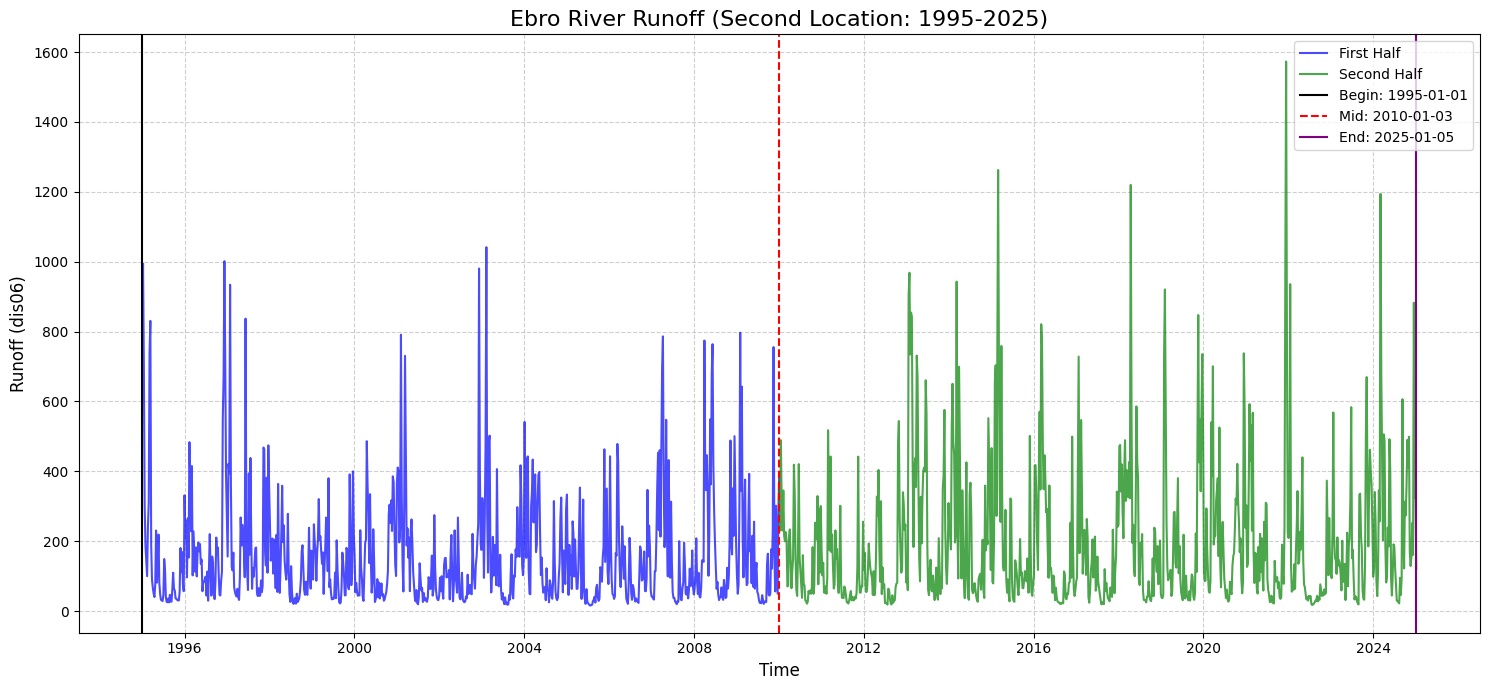

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np

# --- Required definitions from other cells for self-containment ---
input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"
data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])

first_begin=0
first_end=5479
second_begin=5480
second_end=10958
time_scale="1W"

def river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the average runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled and averaged runoff data.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the mean
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).mean(dim='valid_time')
    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
    return runoff_slice_time_location_time_scale

rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]
# --- End of required definitions ---

ebro_lon = None
ebro_lat = None

# Find Ebro river's 'Second location' coordinates
for river_data in rivers:
    if river_data['river'] == 'Ebro':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                ebro_lon = location_data['longitude']
                ebro_lat = location_data['latitude']
                break
    if ebro_lon is not None: # Break outer loop once found
        break

if ebro_lon is None or ebro_lat is None:
    raise ValueError("Ebro river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Ebro location
distances = (data.longitude - ebro_lon)**2 + (data.latitude - ebro_lat)**2
nearest_idx = distances.argmin().item()
nearest_ebro_lon = data.longitude[nearest_idx].item()
nearest_ebro_lat = data.latitude[nearest_idx].item()

print(f"Nearest Ebro location: Lat={nearest_ebro_lat:.4f}, Lon={nearest_ebro_lon:.4f}")

# Extract runoff data for the first half of the dataset
ebro_runoff_first_half = river_runoff_time_location_mean(
    data, nearest_ebro_lon, nearest_ebro_lat, first_begin, first_end, time_scale
)

# Extract runoff data for the second half of the dataset
ebro_runoff_second_half = river_runoff_time_location_mean(
    data, nearest_ebro_lon, nearest_ebro_lat, second_begin, second_end, time_scale
)

# Combine the two halves for plotting
combined_runoff = xr.concat([ebro_runoff_first_half, ebro_runoff_second_half], dim='valid_time')

# Get the time boundaries using .values to get numpy.datetime64 objects
begin_time = combined_runoff['valid_time'].min().values
mid_time = ebro_runoff_first_half['valid_time'].max().values # End of first half is start of second
end_time = combined_runoff['valid_time'].max().values

# Create the plot
plt.figure(figsize=(15, 7))
plt.plot(ebro_runoff_first_half['valid_time'], ebro_runoff_first_half['dis06'], label='First Half', color='blue', alpha=0.7)
plt.plot(ebro_runoff_second_half['valid_time'], ebro_runoff_second_half['dis06'], label='Second Half', color='green', alpha=0.7)

# Add vertical lines for begin, mid, and end dates
plt.axvline(x=begin_time, color='black', linestyle='-', linewidth=1.5, label=f'Begin: {pd.to_datetime(begin_time).strftime("%Y-%m-%d")}')
plt.axvline(x=mid_time, color='red', linestyle='--', linewidth=1.5, label=f'Mid: {pd.to_datetime(mid_time).strftime("%Y-%m-%d")}')
plt.axvline(x=end_time, color='purple', linestyle='-', linewidth=1.5, label=f'End: {pd.to_datetime(end_time).strftime("%Y-%m-%d")}')

# Add title and labels
plt.title(f'Ebro River Runoff (Second Location: {pd.to_datetime(begin_time).strftime("%Y")}-{pd.to_datetime(end_time).strftime("%Y")})', fontsize=16)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Runoff (dis06)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import xarray as xr
import numpy as np

def transform_to_quantiles(runoff_slice_max, runoff_slice_full):
    """
    Transforms the values of runoff_slice_max['dis24'] to their quantile values relative
    to the entire set of runoff_slice_full['dis24'].

    Parameters:
        runoff_slice_max (xarray.DataArray): The DataArray to transform.
        runoff_slice_full (xarray.DataArray): The reference DataArray for quantile calculation.

    Returns:
        numpy.ndarray: A numpy array of quantile values.
    """
    # Flatten the full reference dataset to calculate quantiles
    reference_values = runoff_slice_full['dis06'].values.flatten()

    # Remove NaN values for quantile computation
    reference_values = reference_values[~np.isnan(reference_values)]

    # Compute the quantiles
    def calculate_quantile(value):
        return np.sum(reference_values <= value) / len(reference_values)

    # Apply quantile transformation to each value in the target DataArray
    target_values = runoff_slice_max['dis06'].values

    # Vectorize the quantile calculation for efficiency
    vectorized_quantile = np.vectorize(calculate_quantile, otypes=[float])

    # Compute the quantile-transformed values
    quantile_transformed = vectorized_quantile(target_values)

    # Return the result as a numpy array
    return quantile_transformed

# Example usage:
# transformed_dis24 = transform_to_quantiles(runoff_slice_time_location_time_scale_max, runoff_slice_time_location_time_scale)


# General functions

In [ ]:
from scipy import stats
import numpy as np

def fit_best_distribution(data):
    """
    Fits multiple distributions to the data and selects the best based on the chi-square statistic.

    Parameters:
    - data: array-like, input numerical data.

    Returns:
    - best_fit: tuple of (scipy.stats distribution object, fitted parameters)
    - best_chi2: float, chi-square statistic of the best fit
    """
    distributions = [
        stats.norm,
        stats.lognorm,
        stats.weibull_min,
        stats.gamma,
        stats.cauchy,
        stats.expon,
        stats.laplace,
        stats.uniform,
        stats.beta,
        stats.pareto
    ]

    best_fit = None
    best_chi2 = np.inf

    data = np.array(data)
    data = data[np.isfinite(data)]

    if len(data) < 10:
        raise ValueError("Not enough data points to perform distribution fitting.")

    for distribution in distributions:
        try:
            params = distribution.fit(data)
            bins = np.histogram_bin_edges(data, bins='auto')
            observed, _ = np.histogram(data, bins)
            expected = len(data) * np.diff(distribution.cdf(bins, *params))

            # Avoid division by zero
            expected[expected == 0] = 1e-8

            chi2 = np.sum((observed - expected) ** 2 / expected)

            print(f"Fitted {distribution.name}: χ² = {chi2:.4f}")

            if chi2 < best_chi2:
                best_chi2 = chi2
                best_fit = (distribution, params)
        except Exception as e:
            print(f"Error fitting {distribution.name}: {e}")
            continue

    if best_fit is None:
        raise ValueError("No suitable distribution could be fitted.")

    return best_fit, best_chi2


In [ ]:
def calculate_rolling_max(runoff_slice_time_location_time_scale, period_after_event):
    """
    Calculates the maximum value between (and excluding) the i-th element and the i + period_after_event-th element
    for every i-th element in the dataset.

    Parameters:
    - runoff_slice_time_location_time_scale (xarray.DataArray or numpy.ndarray): The input data.
    - period_after_event (int): The number of elements after the i-th element to include in the maximum calculation.

    Returns:
    - max_values (numpy.ndarray): An array of maximum values for each i-th element.
    """
    import numpy as np
    import xarray as xr

    # Ensure the input data is a NumPy array
    if isinstance(runoff_slice_time_location_time_scale, xr.DataArray):
        data = runoff_slice_time_location_time_scale.values
    else:
        data = runoff_slice_time_location_time_scale

    # Initialize an array to store the maximum values
    max_values = np.empty(len(data))

    # Loop through each element
    for i in range(len(data)):
        # Define the range for the current window (exclude the i-th element)
        start_index = i + 1
        end_index = min(i + period_after_event + 1, len(data))  # Ensure not to go out of bounds

        # Calculate the maximum if the range is valid, otherwise set to NaN
        if start_index < len(data):
            max_values[i] = np.max(data[start_index:end_index])
        else:
            max_values[i] = np.nan  # No valid range for max calculation

    return max_values


In [ ]:
def find_closest_index(arr, value):
    # Compute the absolute differences between each element and the given value
    diffs = np.abs(arr - value)

    # Return the index of the smallest difference
    return diffs.argmin()

In [ ]:
# Create an empirical CDF from rolling_max
def empirical_cdf(data, values):
    """Calculate the empirical CDF for given data."""
    sorted_data = np.sort(data)
    return np.searchsorted(sorted_data, values, side='right') / len(data)

# Setting variables

In [ ]:
# Deze is goed

rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.767494, 'longitude': 18.944850},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]


TypeError: list indices must be integers or slices, not str

In [ ]:

first_begin=0
first_end=5479
second_begin=5480
second_end=10958
time_scale="1W"
threshold=0.5
period_after_event=4
X=[0.5,1]
Y=np.linspace(0,1,101)
flood_score=0.9


# Data preperation functions

In [ ]:
def river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the maximum runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing daily runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled data containing the maximum runoff value for each week.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat.
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the maximum for each period
   # runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).max(dim='valid_time')
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).max(dim='valid_time', skipna=True)

    # Debug information
    #print("Sample of weekly maximum runoff data:", runoff_slice_time_location_time_scale['dis06'].values)
    #print("NaN values count in runoff_slice_time_location_time_scale:", runoff_slice_time_location_time_scale['dis06'].isnull().sum().item())
    #print("Original NaN count:", runoff_slice_time_location['dis06'].isnull().sum().item())
    #print("Resampled time coordinates:", runoff_slice_time_location_time_scale['valid_time'].values)

    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())

    return runoff_slice_time_location_time_scale


In [ ]:
def SRI_calculate(runoff_slice_time_location_time_scale):
    # calculate the mean and variance based on the week index of the month
    # replace 'time.week' with 'time.dt.isocalendar().week'
    grouped_runoff = runoff_slice_time_location_time_scale['dis06'].groupby(runoff_slice_time_location_time_scale['valid_time'].dt.isocalendar().week)

    # Create a copy of the river runoff dataset to store the SRI values.
    SRI_slice_time_location = runoff_slice_time_location_time_scale['dis06'].copy()

    # now we can calculate the Z-scores, by first calculating the cdf values for a gamma-
    # and then transforming to a normal (0,1) distributed Z-score.

    for k in range(0, len(runoff_slice_time_location_time_scale['dis06'])):
        # again replace 'time.week' with 'time.dt.isocalendar().week'
        week = runoff_slice_time_location_time_scale['dis06'][k]['valid_time'].dt.isocalendar().week
        week_data = np.array(grouped_runoff[week.item()])
        week_data = week_data[np.isfinite(week_data)]
        if len(week_data) == 0:
            # Handle the case when all values are non-finite.
            continue
        shape, loc, scale = gamma.fit(week_data, floc=0)


        gamma_dist = gamma(shape, loc=loc, scale=scale)
        # calculate the cdf value for the runoff value based on the gamma distribution
        cdf_value = gamma_dist.cdf(runoff_slice_time_location_time_scale['dis06'][k])
        # transform the gamma CDF values to standard normal Z-scores
        SRI_slice_time_location[k] = norm.ppf(cdf_value)

    return SRI_slice_time_location



In [ ]:
def river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the average runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled and averaged runoff data.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the mean
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).mean(dim='valid_time')

    # Debug information
   # print("Sample of runoff data:", runoff_slice_time_location_time_scale['dis06'][:10])
   # print("NaN values count:", runoff_slice_time_location_time_scale['dis06'].isnull().sum().item())
    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
   # print("lon:", lon, "lat:",lat)

    return runoff_slice_time_location_time_scale

In [ ]:
# Now we create a functions that calculates the intensity and duration of the Droughts and Floods, an SRI threshold is needed to define the drought threshold,
#from the drought threshold, a quantile value is determined. # Notice that threshold is always positive and set negative for droughts.

def Intensity_calc (SRI_slice_time_location,runoff_slice_time_location_time_scale, threshold):
# Define the threshold value
  threshold_floods = norm.cdf(threshold)  # Adjust this value according to your requirements

  # Create an empty xarray dataset to store the individual areas
  area_above_threshold = xr.DataArray(np.zeros_like(SRI_slice_time_location), coords=SRI_slice_time_location.coords)

  # Calculate the area above the threshold for each time step
  for t in range(runoff_slice_time_location_time_scale.size):
      # Start a new summation when the value goes above the threshold
      if runoff_slice_time_location_time_scale[t] > threshold_floods:
          area_above_threshold[t] = runoff_slice_time_location_time_scale[t]-threshold_floods
      # Reset the summation if the value goes below the threshold
      else:
          area_above_threshold[t] = 0
      # Continue the summation if the value remains above the threshold
      if t > 0 and runoff_slice_time_location_time_scale[t] > threshold_floods and area_above_threshold[t-1] > 0:
          area_above_threshold[t] = area_above_threshold[t-1]+runoff_slice_time_location_time_scale[t]-threshold_floods

  # Store the individual areas above the threshold in a new variable
  SRI_slice_time_location['Flood_Intensity'] = area_above_threshold


  # Define the threshold value
  threshold = -1*threshold  # Adjust this value according to your requirements

  # Create an empty xarray dataset to store the individual areas
  area_above_threshold = xr.DataArray(np.zeros_like(SRI_slice_time_location), coords=SRI_slice_time_location.coords)

  # Calculate the area above the threshold for each time step
  for t in range(SRI_slice_time_location.size):
      # Start a new summation when the value goes above the threshold
      if SRI_slice_time_location[t] < threshold:
          area_above_threshold[t] = SRI_slice_time_location[t]-threshold
      # Reset the summation if the value goes below the threshold
      else:
          area_above_threshold[t] = 0
      # Continue the summation if the value remains above the threshold
      if t > 0 and SRI_slice_time_location[t] < threshold and area_above_threshold[t-1] < 0:
          area_above_threshold[t] = area_above_threshold[t-1]+SRI_slice_time_location[t]-threshold

  # Store the individual areas above the threshold in a new variable
  SRI_slice_time_location['Drought_Intensity'] = area_above_threshold

  return(SRI_slice_time_location)

In [ ]:
# Extract events is a function that uses the drought and flood intensity values and isolates it into single events
# Notice that by multipying the drougt intensity values by (-1) the function workst for both droughts and floods. Please put "Drought_Intensity"
# or "Flood_Intensity" into the data_array e.g. SRI_slice_time_location['Drougt_Intensity']

## this function can find both the extremes of droughts and floods, in case of droughts just multiply both data_array and SRI_Values with (-1). Notice thata is also stores
## flood_extreme, which is te biggest flood between "period_after_event" weeks after the event.


def extract_events(data_array, SRI_Values,quantiles_weekly_max, period_after_event):
    # Find indices where intensity crosses zero from below
    crossing_indices = np.where((data_array > 0) & (data_array.shift(valid_time=1, fill_value=0) == 0))[0]
    crossing_times = data_array.valid_time.values[crossing_indices]

    # Initialize lists to store start time, end time, maximum intensity, duration, extreme SRI, and flood_extreme
    start_times = []
    end_times = []
    max_intensities = []
    durations = []
    drought_peak = []
    quantile_max_value = []
    mean_severity=[]

    # Iterate over each crossing time and extract the event details
    for time in crossing_times:
        # Find the index of the next zero crossing from above
        next_zero_index = np.where((data_array.shift(valid_time=-1, fill_value=0) == 0) & (data_array.valid_time.values > time))[0]

        if len(next_zero_index) > 0:
            next_zero_index = next_zero_index[0]
        else:
            next_zero_index = len(data_array.valid_time) - 1

        # Extract the event slice
        event = data_array.sel(valid_time=slice(time, data_array.coords['valid_time'].values[next_zero_index]))

        start_times.append(event.valid_time.values[0])
        end_times.append(event.valid_time.values[-1])
        max_intensities.append(event.max().values)
        durations.append((event.valid_time.values[-1] - event.valid_time.values[0]).astype('timedelta64[W]') / np.timedelta64(1, 'W'))
        drought_peak.append((SRI_Values.sel(valid_time=slice(event.valid_time.values[0], event.valid_time.values[-1])).max().values))
        quantile_max_value.append((quantiles_weekly_max.sel(valid_time=slice(event.valid_time.values[-1], event.valid_time.values[-1] + np.timedelta64(period_after_event, 'W'))).max().values))
        mean_severity.append((event.max().values) / ((event.valid_time.values[-1] - event.valid_time.values[0]).astype('timedelta64[W]') / np.timedelta64(1, 'W')).astype(float))
    # Create a new DataArray to store the event details
    event_data = xr.Dataset(
        {
            'start_time': ('event', start_times),
            'end_time': ('event', end_times),
            'max_intensity': ('event', max_intensities),
            'duration_weeks': ('event', durations),
            'drought_peak': ('event', drought_peak),
            'quantile_max_value': ('event', quantile_max_value),
            'mean_drought_severity':('event', mean_severity)
        },
        coords={'event': range(len(start_times))}
    )

    return event_data

In [ ]:
def get_matching_pairs(flood_events, drought_events, time_between_events):
    time_delta = np.timedelta64(time_between_events, 'W')
    matched_start_times = []
    matched_end_times = []

    used_drought_indices = set()

    for flood_time in flood_events['start_time'].values:
        for j, drought_time in enumerate(drought_events['start_time'].values):
            if j in used_drought_indices:
                continue
            if np.timedelta64(0, 'D') <= (flood_time - drought_time) <= time_delta:
                matched_start_times.append(flood_time)
                matched_end_times.append(drought_time)
                used_drought_indices.add(j)
                break  # only one drought per flood

    matched_pairs = xr.Dataset({
        'start_time_flood': (['event'], np.array(matched_start_times)),
        'start_time_drought': (['event'], np.array(matched_end_times)),
    })

    return matched_pairs

In [ ]:
#

def get_matching_pairs_drought_trigger(drought_events, flood_events, time_between_events):
    """
    Matches each drought event to the first unmatched flood event that started
    at least `time_between_events` weeks after the drought ended.

    Parameters:
        drought_events (xr.Dataset): Dataset with 'start_time' and 'end_time' of drought events.
        flood_events (xr.Dataset): Dataset with 'start_time' of flood events.
        time_between_events (int): Minimum number of weeks between the end of a drought and the start of a flood.

    Returns:
        xr.Dataset: Matched pairs of drought and flood start times.
    """
    time_delta = np.timedelta64(time_between_events, 'W')
    matched_drought_times = []
    matched_flood_times = []

    used_flood_indices = set()

    for i, drought_end_time in enumerate(drought_events['end_time'].values):
        for j, flood_start_time in enumerate(flood_events['start_time'].values):
            if j in used_flood_indices:
                continue
            if (flood_start_time > drought_end_time) and (flood_start_time <= drought_end_time + time_delta):
                matched_drought_times.append(drought_events['start_time'].values[i])
                matched_flood_times.append(flood_start_time)
                used_flood_indices.add(j)
                break  # only one flood per drought

    matched_pairs = xr.Dataset({
        'start_time_drought': (['event'], np.array(matched_drought_times)),
        'start_time_flood': (['event'], np.array(matched_flood_times)),
    })

    return matched_pairs


In [ ]:
import numpy as np
import xarray as xr
from scipy.stats import binom

def get_matching_pairs_eca(drought_events, flood_events, time_between_events, direction="trigger"):
    """
    Matches drought and flood events based on ECA logic: either trigger or precursor.

    Parameters:
        drought_events (xr.Dataset): Dataset with 'start_time' and 'end_time' of drought events.
        flood_events (xr.Dataset): Dataset with 'start_time' of flood events.
        time_between_events (int): Number of weeks in the coincidence window.
        direction (str): "trigger" or "precursor"

    Returns:
        xr.Dataset: Matched pairs of event times.
    """
    time_delta = np.timedelta64(time_between_events, 'W')

    matched_drought_times = []
    matched_flood_times = []

    if direction == "trigger":
        # One flood per drought: floods after droughts
        used_flood_indices = set()
        for i, drought_end_time in enumerate(drought_events['end_time'].values):
            for j, flood_start_time in enumerate(flood_events['start_time'].values):
                if j in used_flood_indices:
                    continue
                if (flood_start_time > drought_end_time) and (flood_start_time <= drought_end_time + time_delta):
                    matched_drought_times.append(drought_events['start_time'].values[i])
                    matched_flood_times.append(flood_start_time)
                    used_flood_indices.add(j)
                    break  # Only one flood per drought

    elif direction == "precursor":
        # One drought per flood: droughts before floods
        used_drought_indices = set()
        for i, flood_start_time in enumerate(flood_events['start_time'].values):
            for j, drought_end_time in enumerate(drought_events['end_time'].values):
                if j in used_drought_indices:
                    continue
                if (drought_end_time < flood_start_time) and (drought_end_time >= flood_start_time - time_delta):
                    matched_flood_times.append(flood_start_time)
                    matched_drought_times.append(drought_events['start_time'].values[j])
                    used_drought_indices.add(j)
                    break  # Only one drought per flood

    else:
        raise ValueError("Invalid direction. Must be 'trigger' or 'precursor'.")

    matched_pairs = xr.Dataset({
        'start_time_drought': (['event'], np.array(matched_drought_times)),
        'start_time_flood': (['event'], np.array(matched_flood_times)),
    })

    return matched_pairs


    from scipy import stats
import numpy as np
import pandas as pd

def eca_p_value(drought_events, flood_events, total_weeks, period_after_event, direction="trigger"):
    """
    Calculates the binomial p-value for Event Coincidence Analysis (ECA)
    to test whether droughts trigger floods or precede them (precursor).

    Parameters:
        drought_events (xr.Dataset): Dataset with 'start_time' and 'end_time'.
        flood_events (xr.Dataset): Dataset with 'start_time'.
        total_weeks (int): Total number of time steps (weeks) in the full record.
        period_after_event (int): Time window in weeks.
        direction (str): "trigger" or "precursor".

    Returns:
        dict: {
            "p_value": empirical one-sided p-value,
            "drought_count": number of droughts (used as trials),
            "flood_count": number of floods,
            "drought_flood_count": number of observed matches
        }
    """
    # Convert to DataFrames
    drought_df = drought_events[['start_time', 'end_time']].to_dataframe().reset_index(drop=True)
    flood_df = flood_events[['start_time']].to_dataframe().reset_index(drop=True)

    drought_count = len(drought_df)
    flood_count = len(flood_df)
    delta = pd.Timedelta(weeks=period_after_event)

    # Count matching events
    match_count = 0

    if direction == "trigger":
        # For each drought, check if a flood occurs within the window after drought end
        matching_pairs=get_matching_pairs_eca(drought_events, flood_events, period_after_event, direction="trigger")
        match_count=matching_pairs.dims['event']
        # Probability that a drought is followed by a flood in random case
        p_single = period_after_event / total_weeks
        trials = drought_count

    elif direction == "precursor":
        # For each flood, check if a drought ended within the window before the flood
        matching_pairs=get_matching_pairs_eca(drought_events, flood_events, period_after_event, direction="precursor")
        match_count = matching_pairs.dims['event']

        # Probability that a flood is preceded by a drought in random case
        p_single = period_after_event / total_weeks
        trials = flood_count

    else:
        raise ValueError("Invalid direction. Use 'trigger' or 'precursor'.")

    # Probability that at least one match occurs per trial
    p_at_least_one = 1 - (1 - p_single) ** trials

    # Compute p-value: probability of getting match_count or more
    p_value = sum(stats.binom.pmf(k, trials, p_at_least_one)
                  for k in range(match_count, trials + 1))
    print( "p_value", p_value,
        "drought_count", drought_count,
        "flood_count", flood_count,
        "drought_flood_count", match_count)
    return {
        "p_value": p_value,
        "drought_count": drought_count,
        "flood_count": flood_count,
        "drought_flood_count": match_count
    }





In [ ]:
# now we can put all these function in one function, this is in the case we're intested in the trasition probability.
def drought_characteristics (data, lon, lat, begin, end, time_scale, threshold, period_after_event):
  SRI_Values=SRI_calculate(river_runoff_time_location(data, lon, lat, begin, end, time_scale))
  Intensities=Intensity_calc(SRI_Values, threshold)
  drought_intensity=Intensities["Drought_Intensity"]
  drought_event_data=extract_events(drought_intensity*-1, SRI_Values*-1, period_after_event)

  return(drought_event_data)

In [ ]:
import xarray as xr
import numpy as np

def transform_to_quantiles(runoff_slice_max, runoff_slice_full):
    """
    Transforms the values of runoff_slice_max['dis06'] to their quantile values relative
    to the entire set of runoff_slice_full['dis06'].

    Parameters:
        runoff_slice_max (xarray.DataArray): The DataArray to transform.
        runoff_slice_full (xarray.DataArray): The reference DataArray for quantile calculation.

    Returns:
        xarray.DataArray: A DataArray of quantile values.
    """
    # Flatten the full reference dataset to calculate quantiles
    reference_values = runoff_slice_full['dis06'].values.flatten()

    # Remove NaN values for quantile computation
    reference_values = reference_values[~np.isnan(reference_values)]

    # Compute the quantiles
    def calculate_quantile(value):
        return np.sum(reference_values <= value) / len(reference_values)

    # Apply quantile transformation to each value in the target DataArray
    target_values = runoff_slice_max['dis06'].values

    # Vectorize the quantile calculation for efficiency
    vectorized_quantile = np.vectorize(calculate_quantile, otypes=[float])

    # Compute the quantile-transformed values
    quantile_transformed = vectorized_quantile(target_values)

    # Return the result as a new DataArray with the same coordinates as the original
    return xr.DataArray(
        quantile_transformed,
        dims=runoff_slice_max['dis06'].dims,
        coords=runoff_slice_max['dis06'].coords,
        name='quantile_dis06'
    )

# P-value calculations

In [ ]:
#a function that determines the p_values

def drought_flood_p_value (data, lon, lat, begin, end, time_scale, threshold, period_after_event) :
  # getting a subeset for the area, and
  runoff_slice_time_location_time_scale=river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale)
  print('runoff_slice_time_location_time_scale', runoff_slice_time_location_time_scale)

  # calculating the SRI values
  SRI_Values=SRI_calculate(runoff_slice_time_location_time_scale)

  print('SRI_Values',SRI_Values)
  runoff_maximum_weekly=river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale)

  qunatiles_weekly_max=transform_to_quantiles(runoff_maximum_weekly, runoff_slice_time_location_time_scale)
  # Obtaining the intensities
  Intensities=Intensity_calc(SRI_Values,qunatiles_weekly_max, threshold)

  drought_intensity=Intensities["Drought_Intensity"]
  flood_intensity=Intensities["Flood_Intensity"]

  flood_events=extract_events(flood_intensity, qunatiles_weekly_max,qunatiles_weekly_max,period_after_event)
  print(flood_events)
  drought_events=extract_events(drought_intensity*-1, SRI_Values*-1,qunatiles_weekly_max,period_after_event)
  drougt_flood_pairs=get_matching_pairs(flood_events, drought_events, period_after_event)
  timespan=len(Intensities["Drought_Intensity"]['valid_time'])
  flood_count= len(flood_events["event"])
  drought_count=len(drought_events["event"])
  drought_flood_count=len(get_matching_pairs(flood_events, drought_events, period_after_event)["event"])
  drought_flood_count_new=0
  # Convert both datasets to DataFrames
  events_df = drought_events[['start_time', 'max_intensity']].to_dataframe().reset_index()
  events_df = events_df.sort_values('start_time')

  events_ff = flood_events[['start_time', 'max_intensity']].to_dataframe().reset_index()
  events_ff = events_ff.sort_values('start_time')

  period_after_event_weeks = pd.Timedelta(weeks=period_after_event)

  # Identify matching drought-flood pairs and store indices
  matching_droughts = set()
  matching_floods = set()

  for i, drought_row in events_df.iterrows():
    for j, flood_row in events_ff.iterrows():
        if j in matching_floods:  # Skip if this flood is already matched
            continue
        time_diff = flood_row['start_time'] - drought_row['start_time']
        if pd.Timedelta(0) <= time_diff <= period_after_event_weeks:
            matching_droughts.add(i)
            matching_floods.add(j)
            drought_flood_count_new += 1
            break  # One flood per drought





  # Plotting
  plt.figure(figsize=(14, 6))

  # Plot droughts (blue by default, yellow if matched)
  for i, row in events_df.iterrows():
      color = 'black' if i in matching_droughts else 'red'
      plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color='red', linewidth=1)
      plt.plot(row['start_time'], row['max_intensity'], 'o', color='red', markersize=4)

  # Plot floods (red by default, yellow if matched)
  for j, row in events_ff.iterrows():
      color = 'black' if j in matching_floods else 'blue'
      plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color='blue', linewidth=1)
      plt.plot(row['start_time'], row['max_intensity'], 'o', color=color, markersize=4)

  # Add summary text to figure
  summary_text = f'Droughts: {drought_count}   Floods: {flood_count}   Drought-to-Flood Events: {drought_flood_count}  Drought-to-Flood Events new{drought_flood_count_new}'
  plt.title('Drought and Flood Max Intensities Over Time')
  plt.xlabel('Start Time')
  plt.ylabel('Max Intensity')
  plt.text(0.01, 0.95, summary_text, transform=plt.gca().transAxes, fontsize=10, bbox=dict(facecolor='white', alpha=0.5))

  plt.grid(True, linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()

  # calculating the probability that an arbitraity flood precedided by a specific drought.
  p_spes_drought=period_after_event/timespan

  # probability of at least one flood
  p_at_least_one_drought=1-(1-p_spes_drought)**drought_count


  # probability of observing drought_flood_count amount of floods
  p_drought_flood_count=stats.binom.pmf(drought_flood_count, drought_count, p_at_least_one_drought)

  p_value=0
  for count in  range(drought_flood_count , drought_count):
    p_value+= stats.binom.pmf(count, drought_count, p_at_least_one_drought)

  p_value_new=0
  p_value_new = sum(stats.binom.pmf(k, drought_count, p_at_least_one_drought)
              for k in range(drought_flood_count, drought_count + 1))
  return(p_value,p_value_new,  drought_count, flood_count,drought_flood_count)

In [ ]:
import numpy as np
import pandas as pd

def monte_carlo_p_value(
    drought_events,
    flood_events,
    period_after_event,
    start_date,
    n_weeks,
    n_simulations,
    observed_matches,
    seed=42,

):
    """
    Monte Carlo ECA using drought end times to test whether floods follow droughts
    more often than expected by chance.

    Parameters:
    - drought_events: xarray.Dataset with 'end_time' (datetime64[ns])
    - flood_events: xarray.Dataset with 'start_time' (datetime64[ns])
    - period_after_event: int, number of weeks to check for flood after drought ends
    - start_date: string, np.datetime64, pd.Timestamp, or xarray.DataArray
    - n_weeks: int, total number of weekly time steps (for randomized flood timing)
    - n_simulations: int, number of Monte Carlo randomizations
    - seed: int, random seed for reproducibility

    Returns:
    - p_value: float, empirical p-value
    - observed_matches: int, real drought→flood matches
    - match_counts: list[int], simulated match counts
    """
    np.random.seed(seed)

    # Handle various input formats for start_date
    if hasattr(start_date, "values"):  # xarray or numpy array
        start_date = pd.Timestamp(start_date.values.item())
    elif isinstance(start_date, np.datetime64):
        start_date = pd.Timestamp(start_date)
    else:
        start_date = pd.to_datetime(str(start_date))

    # Generate weekly time range
    time_range = pd.date_range(start=start_date, periods=n_weeks, freq="W")

    # Extract event times
    drought_ends = pd.to_datetime(drought_events["end_time"].values)
    flood_starts = pd.to_datetime(flood_events["start_time"].values)
    delta = pd.Timedelta(weeks=period_after_event)

    # Step 1: Observed matches


    # Step 2: Monte Carlo simulations
    match_counts = []
    for _ in range(n_simulations):
        randomized_floods = np.random.choice(time_range, size=len(flood_starts), replace=False)
        count = 0
        for drought_end in drought_ends:
            if np.any((randomized_floods >= drought_end) & (randomized_floods <= drought_end + delta)):
                count += 1

        match_counts.append(count)
    print('maximum dtf', max(match_counts))
    # Step 3: Empirical p-value
    match_counts = np.array(match_counts)
    p_value = np.sum(match_counts >= observed_matches) / n_simulations

    print('P-VALLUEEEEE:',p_value)

    return p_value, observed_matches, match_counts


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def monte_carlo_p_value(
    drought_events,
    flood_events,
    period_after_event,
    start_date,
    n_weeks,
    n_simulations,
    observed_matches,
    seed=42,
    plot_first_n=3
):
    np.random.seed(seed)

    # Normalize start_date
    if hasattr(start_date, "values"):
        start_date = pd.Timestamp(start_date.values.item())
    elif isinstance(start_date, np.datetime64):
        start_date = pd.Timestamp(start_date)
    else:
        start_date = pd.to_datetime(start_date)

    # Define full valid time range
    full_time_range = pd.date_range(start=start_date, periods=n_weeks, freq="W")
    time_min, time_max = full_time_range[0], full_time_range[-1] - pd.Timedelta(weeks=period_after_event)

    # Extract and prep input data
    drought_ends = pd.to_datetime(drought_events["end_time"].values)
    drought_df = drought_events[['end_time', 'max_intensity']].to_dataframe().reset_index(drop=True)
    flood_df_real = flood_events[['start_time', 'max_intensity']].to_dataframe().reset_index(drop=True)

    delta = pd.Timedelta(weeks=period_after_event)
    match_counts = []

    for sim in range(n_simulations):
        # Step 1: Randomize flood times within allowed range
        randomized_dates = np.random.choice(
            pd.date_range(time_min, time_max, freq="D"),
            size=len(flood_df_real),
            replace=False
        )

        flood_df = flood_df_real.copy()
        flood_df['start_time'] = np.sort(randomized_dates)  # Optional: sort for readability

        # Step 2: Match droughts to floods
        matching_droughts = set()
        matching_floods = set()
        count = 0

        for i, drought_time in enumerate(drought_ends):
            for j, flood_time in enumerate(flood_df['start_time']):
                if j in matching_floods:
                    continue
                if pd.Timedelta(0) <= (flood_time - drought_time) <= delta:
                    matching_droughts.add(i)
                    matching_floods.add(j)
                    count += 1
                    break

        match_counts.append(count)

        # Step 3: Plot some simulations
        if sim < plot_first_n:
            plt.figure(figsize=(14, 6))

            for i, row in drought_df.iterrows():
                color = 'yellow' if i in matching_droughts else 'red'
                plt.plot([row['end_time'], row['end_time']], [0, row['max_intensity']], color=color, linewidth=1)
                plt.plot(row['end_time'], row['max_intensity'], 'o', color=color, markersize=4)

            for j, row in flood_df.iterrows():
                color = 'yellow' if j in matching_floods else 'blue'
                plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color=color, linewidth=1)
                plt.plot(row['start_time'], row['max_intensity'], 'o', color=color, markersize=4)

            summary = f"Simulation {sim+1} — Droughts: {len(drought_df)}, Floods: {len(flood_df)}, Matches: {count}"
            plt.title(summary)
            plt.xlabel('Time')
            plt.ylabel('Max Intensity')
            plt.text(0.01, 0.95, summary, transform=plt.gca().transAxes,
                     fontsize=10, bbox=dict(facecolor='white', alpha=0.5))
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.tight_layout()
            plt.show()

    # Step 4: Empirical p-value
    match_counts = np.array(match_counts)
    p_value = np.sum(match_counts >= observed_matches) / n_simulations

    print(f"Empirical p-value: {p_value:.4f} — Max simulated matches: {match_counts.max()}")

    return p_value, observed_matches, match_counts


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

def monte_carlo_p_value(
    drought_events,
    flood_events,
    period_after_event,
    data,
    begin,
    end,
    n_simulations,
    observed_matches,
    seed=42,
    plot_first_n=3,
):
    """
    Monte Carlo ECA using real time window defined by data['valid_time'][begin:end].
    """
    np.random.seed(seed)
    print('BEGIN:', begin, 'END:', end)

    # Get the actual valid time range from the data
    valid_times = pd.to_datetime(data['valid_time'].values[begin:end])
    time_min = valid_times.min()
    time_max = valid_times.max() - pd.Timedelta(weeks=period_after_event)

    # Extract drought/flood data
    drought_ends = pd.to_datetime(drought_events["end_time"].values)
    drought_df = drought_events[['end_time', 'max_intensity']].to_dataframe().reset_index(drop=True)
    flood_df_real = flood_events[['start_time', 'max_intensity']].to_dataframe().reset_index(drop=True)

    delta = pd.Timedelta(weeks=period_after_event)
    match_counts = []

    for sim in range(n_simulations):
        # Step 1: Randomly sample flood times from valid range
        randomized_dates = np.random.choice(
            pd.date_range(time_min, time_max, freq="D"),
            size=len(flood_df_real),
            replace=False
        )

        flood_df = flood_df_real.copy()
        flood_df['start_time'] = np.sort(randomized_dates)

        # Step 2: Match floods to droughts
        matching_droughts = set()
        matching_floods = set()
        count = 0

        for i, drought_time in enumerate(drought_ends):
            for j, flood_time in enumerate(flood_df['start_time']):
                if j in matching_floods:
                    continue
                if pd.Timedelta(0) <= (flood_time - drought_time) <= delta:
                    matching_droughts.add(i)
                    matching_floods.add(j)
                    count += 1
                    break

        match_counts.append(count)

        # Step 3: Plot (only for first few simulations)
     #   if sim < plot_first_n:
      #      plt.figure(figsize=(14, 6))

#            for i, row in drought_df.iterrows():
 #               plt.plot([row['end_time'], row['end_time']], [0, row['max_intensity']], color='red', linewidth=1)
  #              plt.plot(row['end_time'], row['max_intensity'], 'o', color='red', markersize=4)

   #         for j, row in flood_df.iterrows():
    #            color = 'black' if j in matching_floods else 'blue'
     #           plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color='blue', linewidth=1)
      #          plt.plot(row['start_time'], row['max_intensity'], 'o', color=color, markersize=4)

       #     summary = (
        #        f"Simulation {sim+1} — Droughts: {len(drought_df)}, "
         #       f"Floods: {len(flood_df)}, Drought-to-Flood events: {count}"
          #  )
           # plt.title(summary)
            #plt.xlabel('Time')
  #          plt.ylabel('Max Intensity')
   #         plt.text(0.01, 0.95, summary, transform=plt.gca().transAxes,
    #                 fontsize=10, bbox=dict(facecolor='white', alpha=0.5))

     #       # Add legend
      #      red_patch = mlines.Line2D([], [], color='red', marker='o', linestyle='None', markersize=6, label='Drought Event')
       #     blue_patch = mlines.Line2D([], [], color='blue', marker='o', linestyle='None', markersize=6, label='Flood Event')
        #    black_patch = mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=6, label='Drought-to-Flood Event')
         #   plt.legend(handles=[red_patch, blue_patch, black_patch], loc='upper right')

          #  plt.grid(True, linestyle='--', alpha=0.5)
           # plt.tight_layout()
            #plt.show()

    # Step 4: Calculate empirical p-value
    match_counts = np.array(match_counts)
    p_value = np.sum(match_counts >= observed_matches) / n_simulations

    print(f"Empirical p-value: {p_value:.4f} — Max simulated matches: {match_counts.max()}")

    return p_value, observed_matches, match_counts


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
from scipy.stats import gamma, norm, binom
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

# --- Required variable definitions from previous cells ---
input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"
data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])

first_begin=0
first_end=5479
second_begin=5480
second_end=10958
time_scale="1W"
threshold=0.5 # Default threshold
period_after_event=4 # Default period

rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.767494, 'longitude': 18.944850},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]

# --- Required function definitions from previous cells ---
def river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale):
    runoff_slice_time = data.isel(valid_time=slice(begin, end))
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).mean(dim='valid_time')
    # print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
    return runoff_slice_time_location_time_scale

def SRI_calculate(runoff_slice_time_location_time_scale):
    grouped_runoff = runoff_slice_time_location_time_scale['dis06'].groupby(runoff_slice_time_location_time_scale['valid_time'].dt.isocalendar().week)
    SRI_slice_time_location = runoff_slice_time_location_time_scale['dis06'].copy()
    for k in range(0, len(runoff_slice_time_location_time_scale['dis06'])):
        week = runoff_slice_time_location_time_scale['dis06'][k]['valid_time'].dt.isocalendar().week
        week_data = np.array(grouped_runoff[week.item()])
        week_data = week_data[np.isfinite(week_data)]
        if len(week_data) == 0:
            continue
        shape, loc, scale = gamma.fit(week_data, floc=0)
        gamma_dist = gamma(shape, loc=loc, scale=scale)
        cdf_value = gamma_dist.cdf(runoff_slice_time_location_time_scale['dis06'][k])
        SRI_slice_time_location[k] = norm.ppf(cdf_value)
    return SRI_slice_time_location

def river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale):
    runoff_slice_time = data.isel(valid_time=slice(begin, end))
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).max(dim='valid_time', skipna=True)
    # print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
    return runoff_slice_time_location_time_scale

def transform_to_quantiles(runoff_slice_max, runoff_slice_full):
    reference_values = runoff_slice_full['dis06'].values.flatten()
    reference_values = reference_values[~np.isnan(reference_values)]

    def calculate_quantile(value):
        return np.sum(reference_values <= value) / len(reference_values)

    target_values = runoff_slice_max['dis06'].values
    vectorized_quantile = np.vectorize(calculate_quantile, otypes=[float])
    quantile_transformed = vectorized_quantile(target_values)

    return xr.DataArray(
        quantile_transformed,
        dims=runoff_slice_max['dis06'].dims,
        coords=runoff_slice_max['dis06'].coords,
        name='quantile_dis06'
    )

def Intensity_calc (SRI_slice_time_location,quantiles_weekly_max, threshold):
    threshold_floods = norm.cdf(threshold)
    area_above_threshold = xr.DataArray(np.zeros_like(SRI_slice_time_location), coords=SRI_slice_time_location.coords)
    for t in range(quantiles_weekly_max.size):
        if quantiles_weekly_max[t] > threshold_floods:
            area_above_threshold[t] = quantiles_weekly_max[t]-threshold_floods
        else:
            area_above_threshold[t] = 0
        if t > 0 and quantiles_weekly_max[t] > threshold_floods and area_above_threshold[t-1] > 0:
            area_above_threshold[t] = area_above_threshold[t-1]+quantiles_weekly_max[t]-threshold_floods
    SRI_slice_time_location['Flood_Intensity'] = area_above_threshold

    threshold_drought = -1 * threshold
    area_above_threshold = xr.DataArray(np.zeros_like(SRI_slice_time_location), coords=SRI_slice_time_location.coords)
    for t in range(SRI_slice_time_location.size):
        if SRI_slice_time_location[t] < threshold_drought:
            area_above_threshold[t] = SRI_slice_time_location[t]-threshold_drought
        else:
            area_above_threshold[t] = 0
        if t > 0 and SRI_slice_time_location[t] < threshold_drought and area_above_threshold[t-1] < 0:
            area_above_threshold[t] = area_above_threshold[t-1]+SRI_slice_time_location[t]-threshold_drought
    SRI_slice_time_location['Drought_Intensity'] = area_above_threshold

    return(SRI_slice_time_location)

def extract_events(data_array, SRI_Values, quantiles_weekly_max, period_after_event):
    crossing_indices = np.where((data_array > 0) & (data_array.shift(valid_time=1, fill_value=0) == 0))[0]
    crossing_times = data_array.valid_time.values[crossing_indices]

    start_times = []
    end_times = []
    max_intensities = []
    durations = []
    drought_peak = []
    quantile_max_value = []
    mean_severity = []

    for time in crossing_times:
        next_zero_index = np.where((data_array.shift(valid_time=-1, fill_value=0) == 0) & (data_array.valid_time.values > time))[0]

        if len(next_zero_index) > 0:
            next_zero_index = next_zero_index[0]
        else:
            next_zero_index = len(data_array.valid_time) - 1

        event = data_array.sel(valid_time=slice(time, data_array.coords['valid_time'].values[next_zero_index]))

        start_times.append(event.valid_time.values[0])
        end_times.append(event.valid_time.values[-1])
        max_intensities.append(event.max().values)
        durations.append((event.valid_time.values[-1] - event.valid_time.values[0]).astype('timedelta64[W]') / np.timedelta64(1, 'W'))
        drought_peak.append((SRI_Values.sel(valid_time=slice(event.valid_time.values[0], event.valid_time.values[-1])).max().values))
        quantile_max_value.append((quantiles_weekly_max.sel(valid_time=slice(event.valid_time.values[-1], event.valid_time.values[-1] + np.timedelta64(period_after_event, 'W'))).max().values))
        mean_severity.append((event.max().values) / ((event.valid_time.values[-1] - event.valid_time.values[0]).astype('timedelta64[W]') / np.timedelta64(1, 'W')).astype(float))

    event_data = xr.Dataset(
        {
            'start_time': ('event', start_times),
            'end_time': ('event', end_times),
            'max_intensity': ('event', max_intensities),
            'duration_weeks': ('event', durations),
            'drought_peak': ('event', drought_peak),
            'quantile_max_value': ('event', quantile_max_value),
            'mean_drought_severity':('event', mean_severity)
        },
        coords={'event': range(len(start_times))}
    )

    return event_data

def get_matching_pairs_drought_trigger(drought_events, flood_events, time_between_events):
    time_delta = np.timedelta64(time_between_events, 'W')
    matched_drought_times = []
    matched_flood_times = []

    used_flood_indices = set()

    for i, drought_end_time in enumerate(drought_events['end_time'].values):
        for j, flood_start_time in enumerate(flood_events['start_time'].values):
            if j in used_flood_indices:
                continue
            if (flood_start_time > drought_end_time) and (flood_start_time <= drought_end_time + time_delta):
                matched_drought_times.append(drought_events['start_time'].values[i])
                matched_flood_times.append(flood_start_time)
                used_flood_indices.add(j)
                break

    matched_pairs = xr.Dataset({
        'start_time_drought': (['event'], np.array(matched_drought_times)),
        'start_time_flood': (['event'], np.array(matched_flood_times)),
    })

    return matched_pairs

def get_matching_pairs_eca(drought_events, flood_events, time_between_events, direction="trigger"):
    time_delta = np.timedelta64(time_between_events, 'W')

    matched_drought_times = []
    matched_flood_times = []

    if direction == "trigger":
        used_flood_indices = set()
        for i, drought_end_time in enumerate(drought_events['end_time'].values):
            for j, flood_start_time in enumerate(flood_events['start_time'].values):
                if j in used_flood_indices:
                    continue
                if (flood_start_time > drought_end_time) and (flood_start_time <= drought_end_time + time_delta):
                    matched_drought_times.append(drought_events['start_time'].values[i])
                    matched_flood_times.append(flood_start_time)
                    used_flood_indices.add(j)
                    break

    elif direction == "precursor":
        used_drought_indices = set()
        for i, flood_start_time in enumerate(flood_events['start_time'].values):
            for j, drought_end_time in enumerate(drought_events['end_time'].values):
                if j in used_drought_indices:
                    continue
                if (drought_end_time < flood_start_time) and (drought_end_time >= flood_start_time - time_delta):
                    matched_flood_times.append(flood_start_time)
                    matched_drought_times.append(drought_events['start_time'].values[j])
                    used_drought_indices.add(j)
                    break

    else:
        raise ValueError("Invalid direction. Must be 'trigger' or 'precursor'.")

    matched_pairs = xr.Dataset({
        'start_time_drought': (['event'], np.array(matched_drought_times)),
        'start_time_flood': (['event'], np.array(matched_flood_times)),
    })

    return matched_pairs

def eca_p_value(drought_events, flood_events, total_weeks, period_after_event, direction="trigger"):
    drought_df = drought_events[['start_time', 'end_time']].to_dataframe().reset_index(drop=True)
    flood_df = flood_events[['start_time']].to_dataframe().reset_index(drop=True)

    drought_count = len(drought_df)
    flood_count = len(flood_df)
    delta = pd.Timedelta(weeks=period_after_event)

    match_count = 0

    if direction == "trigger":
        matching_pairs=get_matching_pairs_eca(drought_events, flood_events, period_after_event, direction="trigger")
        match_count=matching_pairs.dims['event']
        p_single = period_after_event / total_weeks
        trials = drought_count

    elif direction == "precursor":
        matching_pairs=get_matching_pairs_eca(drought_events, flood_events, period_after_event, direction="precursor")
        match_count = matching_pairs.dims['event']
        p_single = period_after_event / total_weeks
        trials = flood_count

    else:
        raise ValueError("Invalid direction. Use 'trigger' or 'precursor'.")

    p_at_least_one = 1 - (1 - p_single) ** trials

    p_value = sum(binom.pmf(k, trials, p_at_least_one)
                  for k in range(match_count, trials + 1))
    # print( "p_value", p_value,
    #     "drought_count", drought_count,
    #     "flood_count", flood_count,
    #     "drought_flood_count", match_count)
    return {
        "p_value": p_value,
        "drought_count": drought_count,
        "flood_count": flood_count,
        "drought_flood_count": match_count
    }

def monte_carlo_p_value(
    drought_events,
    flood_events,
    period_after_event,
    data,
    begin,
    end,
    n_simulations,
    observed_matches,
    seed=42,
    plot_first_n=0 # Set to 0 to avoid plotting during Monte Carlo
):
    np.random.seed(seed)
    # print('BEGIN:', begin, 'END:', end)

    valid_times = pd.to_datetime(data['valid_time'].values[begin:end])
    time_min = valid_times.min()
    time_max = valid_times.max() - pd.Timedelta(weeks=period_after_event)

    drought_ends = pd.to_datetime(drought_events["end_time"].values)
    drought_df = drought_events[['end_time', 'max_intensity']].to_dataframe().reset_index(drop=True)
    flood_df_real = flood_events[['start_time', 'max_intensity']].to_dataframe().reset_index(drop=True)

    delta = pd.Timedelta(weeks=period_after_event)
    match_counts = []

    for sim in range(n_simulations):
        randomized_dates = np.random.choice(
            pd.date_range(time_min, time_max, freq="D"),
            size=len(flood_df_real),
            replace=False
        )

        flood_df = flood_df_real.copy()
        flood_df['start_time'] = np.sort(randomized_dates)

        matching_droughts = set()
        matching_floods = set()
        count = 0

        for i, drought_time in enumerate(drought_ends):
            for j, flood_time in enumerate(flood_df['start_time']):
                if j in matching_floods:
                    continue
                if pd.Timedelta(0) <= (flood_time - drought_time) <= delta:
                    matching_droughts.add(i)
                    matching_floods.add(j)
                    count += 1
                    break

        match_counts.append(count)

    match_counts = np.array(match_counts)
    p_value = np.sum(match_counts >= observed_matches) / n_simulations

    # print(f"Empirical p-value: {p_value:.4f} — Max simulated matches: {match_counts.max()}")

    return p_value, observed_matches, match_counts

def drought_flood_p_value_trigger_ECA(data, lon, lat, begin, end, time_scale, threshold, period_after_event):
    runoff_slice_time_location_time_scale = river_runoff_time_location_mean(
        data, lon, lat, begin, end, time_scale
    )

    SRI_values = SRI_calculate(runoff_slice_time_location_time_scale)

    runoff_maximum_weekly = river_runoff_time_location_maximum(
        data, lon, lat, begin, end, time_scale
    )
    quantiles_weekly_max = transform_to_quantiles(
        runoff_maximum_weekly, runoff_slice_time_location_time_scale
    )

    intensities = Intensity_calc(SRI_values, quantiles_weekly_max, threshold)
    drought_intensity = intensities["Drought_Intensity"]
    flood_intensity = intensities["Flood_Intensity"]

    flood_events = extract_events(
        flood_intensity, quantiles_weekly_max, quantiles_weekly_max, period_after_event
    )
    drought_events = extract_events(
        drought_intensity * -1, SRI_values * -1, quantiles_weekly_max, period_after_event
    )

    # Manual matching for observed_matches (as needed for Monte Carlo)
    drought_df_temp = drought_events[['start_time', 'end_time']].to_dataframe().reset_index().sort_values('start_time')
    flood_df_temp = flood_events[['start_time']].to_dataframe().reset_index().sort_values('start_time')

    period_after_event_weeks = pd.Timedelta(weeks=period_after_event)
    observed_matches = 0
    used_flood_indices = set()

    for i, drought_row in drought_df_temp.iterrows():
        for j, flood_row in flood_df_temp.iterrows():
            if j in used_flood_indices:
                continue
            if (flood_row['start_time'] > drought_row['end_time']) and \
               (flood_row['start_time'] <= drought_row['end_time'] + period_after_event_weeks):
                observed_matches += 1
                used_flood_indices.add(j)
                break

    p_value_monte_carlo_trigger, _, _ = monte_carlo_p_value(
        drought_events,
        flood_events,
        period_after_event,
        data,
        begin,
        end,
        n_simulations=10000,
        observed_matches=observed_matches,
        seed=42
    )

    timespan = len(intensities["Drought_Intensity"]['valid_time'])

    eca_trigger_result = eca_p_value(
        drought_events, flood_events, timespan, period_after_event, direction="trigger"
    )

    p_value_trigger = eca_trigger_result["p_value"]
    drought_count = eca_trigger_result["drought_count"]
    flood_count = eca_trigger_result["flood_count"]
    match_count_trigger = eca_trigger_result["drought_flood_count"]

    return (
        p_value_monte_carlo_trigger,
        p_value_trigger
    )

# --- Find Danube Second Location coordinates ---
danube_lon = None
danube_lat = None

for river_data in rivers:
    if river_data['river'] == 'Danube':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                danube_lon = location_data['longitude']
                danube_lat = location_data['latitude']
                break
    if danube_lon is not None:
        break

if danube_lon is None or danube_lat is None:
    raise ValueError("Danube river's 'Second location' coordinates not found.")

# Find the nearest grid point
distances = (data.longitude - danube_lon)**2 + (data.latitude - danube_lat)**2
nearest_idx = distances.argmin().item()
nearest_danube_lon = data.longitude[nearest_idx].item()
nearest_danube_lat = data.latitude[nearest_idx].item()

print(f"Danube (Second Location - Visegrád) Nearest Grid Point: Lat={nearest_danube_lat:.4f}, Lon={nearest_danube_lon:.4f}")

# --- First Period Calculation ---
print("\n--- First Period ---")
p_mc_first, p_poisson_first = drought_flood_p_value_trigger_ECA(
    data, nearest_danube_lon, nearest_danube_lat, first_begin, first_end, time_scale, threshold=1, period_after_event=4
)
print(f"First Period: Poisson p-value = {p_poisson_first:.4f}, Monte Carlo p-value = {p_mc_first:.4f}")

# --- Second Period Calculation ---
print("\n--- Second Period ---")
p_mc_second, p_poisson_second = drought_flood_p_value_trigger_ECA(
    data, nearest_danube_lon, nearest_danube_lat, second_begin, second_end, time_scale, threshold=1, period_after_event=4
)
print(f"Second Period: Poisson p-value = {p_poisson_second:.4f}, Monte Carlo p-value = {p_mc_second:.4f}")


Danube (Second Location - Visegrád) Nearest Grid Point: Lat=49.9917, Lon=19.5917

--- First Period ---


KeyboardInterrupt: 

In [ ]:
def drought_flood_p_value_trigger_ECA(data, lon, lat, begin, end, time_scale, threshold, period_after_event):
    # Step 1: Subset data and compute mean runoff
    runoff_slice_time_location_time_scale = river_runoff_time_location_mean(
        data, lon, lat, begin, end, time_scale
    )

    # Step 2: Calculate SRI
    SRI_values = SRI_calculate(runoff_slice_time_location_time_scale)

    # Step 3: Weekly max runoff and quantiles
    runoff_maximum_weekly = river_runoff_time_location_maximum(
        data, lon, lat, begin, end, time_scale
    )
    quantiles_weekly_max = transform_to_quantiles(
        runoff_maximum_weekly, runoff_slice_time_location_time_scale
    )

    # Step 4: Calculate drought/flood intensities
    intensities = Intensity_calc(SRI_values, quantiles_weekly_max, threshold)
    drought_intensity = intensities["Drought_Intensity"]
    flood_intensity = intensities["Flood_Intensity"]

    # Step 5: Extract events
    flood_events = extract_events(
        flood_intensity, quantiles_weekly_max, quantiles_weekly_max, period_after_event
    )
    drought_events = extract_events(
        drought_intensity * -1, SRI_values * -1, quantiles_weekly_max, period_after_event
    )

    # Step 6: Get matching drought-flood pairs
    drought_flood_pairs = get_matching_pairs_drought_trigger(
        flood_events, drought_events, period_after_event
    )
    drought_flood_count = len(drought_flood_pairs["event"])

    # Step 7: Manual matching for cross-check
    drought_df = drought_events[['start_time', 'max_intensity']].to_dataframe().reset_index().sort_values('start_time')
    flood_df = flood_events[['start_time', 'max_intensity']].to_dataframe().reset_index().sort_values('start_time')

    period_after_event_weeks = pd.Timedelta(weeks=period_after_event)
    matching_droughts = set()
    matching_floods = set()
    drought_flood_count_new = 0

    for i, drought_row in drought_df.iterrows():
        for j, flood_row in flood_df.iterrows():
            if j in matching_floods:
                continue
            time_diff = flood_row['start_time'] - drought_row['start_time']
            if pd.Timedelta(0) <= time_diff <= period_after_event_weeks:
                matching_droughts.add(i)
                matching_floods.add(j)
                drought_flood_count_new += 1
                break  # One flood per drought



    # Step 8: Plotting (your original color logic preserved)
    plt.figure(figsize=(14, 6))

    for i, row in drought_df.iterrows():
        plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color='red', linewidth=1)
        plt.plot(row['start_time'], row['max_intensity'], 'o', color='red', markersize=4)

    for j, row in flood_df.iterrows():
        color = 'black' if j in matching_floods else 'blue'
        plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color='blue', linewidth=1)
        plt.plot(row['start_time'], row['max_intensity'], 'o', color=color, markersize=4)

    summary_text = (
        f'Droughts: {len(drought_df)}   '
        f'Floods: {len(flood_df)}   '
        f'Drought-to-Flood Events: {drought_flood_count_new}'
    )
    plt.title('Drought and Flood Max Intensities Over Time')
    plt.xlabel('Start Time')
    plt.ylabel('Max Intensity')
    plt.text(0.01, 0.95, summary_text, transform=plt.gca().transAxes,
            fontsize=10, bbox=dict(facecolor='white', alpha=0.5))

    # Add legend
    red_patch = mlines.Line2D([], [], color='red', marker='o', linestyle='None', markersize=6, label='Drought Event')
    blue_patch = mlines.Line2D([], [], color='blue', marker='o', linestyle='None', markersize=6, label='Flood Event')
    black_patch = mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=6, label='Drought-to-Flood Event')
    plt.legend(handles=[red_patch, blue_patch, black_patch], loc='upper right')

    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Step 9: Monte Carlo p-value
    p_value_monte_carlo_trigger, observed_matches, match_counts = monte_carlo_p_value(
    drought_events,
    flood_events,
    period_after_event,
    data,
    begin,
    end,
    n_simulations=10000,
    observed_matches=drought_flood_count_new,
    seed=42
)

    print('monte_carlo_values monte_carlo_p_value',p_value_monte_carlo_trigger,observed_matches,match_counts)


      # Step 10: Analytical p-values from ECA
    timespan = len(intensities["Drought_Intensity"]['valid_time'])

    eca_trigger_result = eca_p_value(
        drought_events, flood_events, timespan, period_after_event, direction="trigger"
    )

    p_value_trigger = eca_trigger_result["p_value"]
    drought_count = eca_trigger_result["drought_count"]
    flood_count = eca_trigger_result["flood_count"]
    match_count_trigger = eca_trigger_result["drought_flood_count"]

    print('eca_p_value (trigger):', p_value_trigger, drought_count, flood_count, match_count_trigger)

    eca_precursor_result = eca_p_value(
        drought_events, flood_events, timespan, period_after_event, direction="precursor"
    )

    p_value_precursor = eca_precursor_result["p_value"]
    match_count_precursor = eca_precursor_result["drought_flood_count"]

    print('eca_p_value (precursor):', p_value_precursor, drought_count, flood_count, match_count_precursor)

    # Step 11: Return key results
    return (
        p_value_monte_carlo_trigger,
        drought_count,
        flood_count,
        match_counts,
        observed_matches,
        p_value_trigger,
        p_value_precursor,
        match_count_trigger,
        match_count_precursor
    )



In [ ]:
print(first_begin, first_end, time_scale, threshold, period_after_event)

# Simulations

In [ ]:
# Show the table
results_df.to_csv('/content/results_df.csv', index=False)

# Optional: Download link (in notebook)
from google.colab import files
files.download('/content/results_df.csv')

NameError: name 'results_df' is not defined

{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.767494, 'longitude': 18.94485}, {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}]} {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}


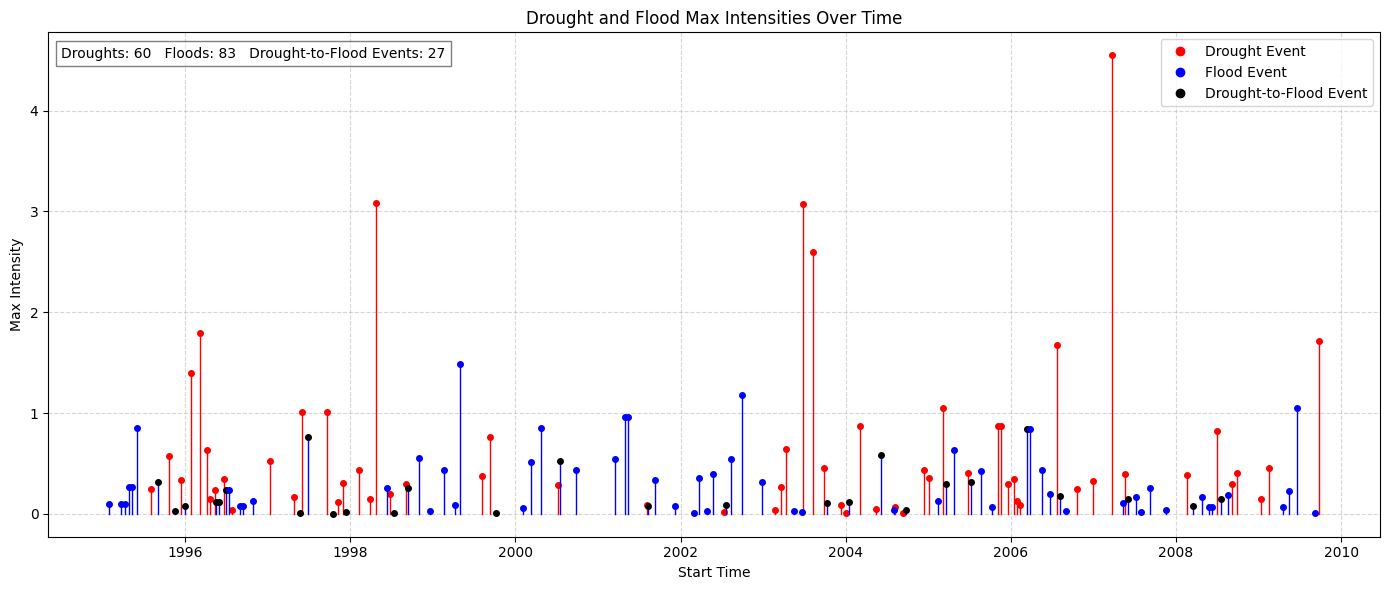

monte_carlo_values monte_carlo_p_value 0.0211 27 [20 22 19 ... 15 15 19]
eca_p_value (trigger): 0.00022892483288688344 60 83 29
eca_p_value (precursor): 0.5148253903019417 60 83 29
Danube (First location) - Droughts: 60, Floods: 83, p_trigger: 0.000, p_MC_trigger: 0.021, Matches: 29
{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.767494, 'longitude': 18.94485}, {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}]} {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.767494, 'longitude': 18.94485}


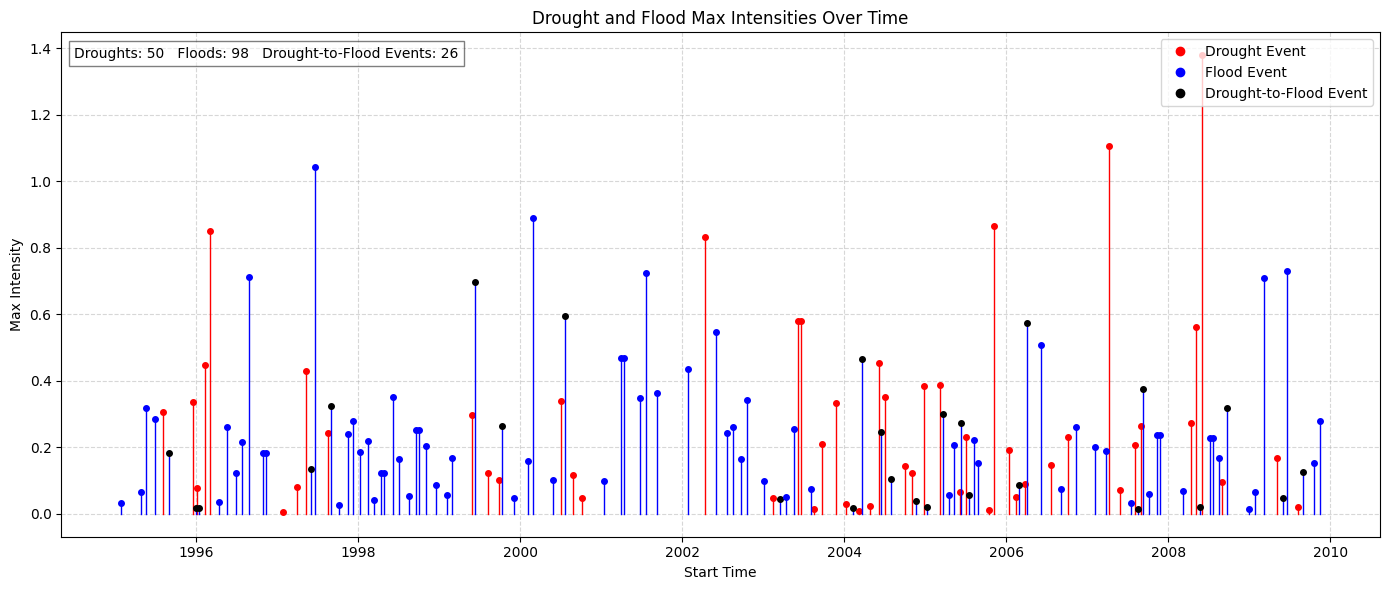

monte_carlo_values monte_carlo_p_value 0.0266 26 [25 19 17 ... 20 18 19]
eca_p_value (trigger): 5.442034442526297e-06 50 98 26
eca_p_value (precursor): 0.9972972085361553 50 98 26
Danube (Second location) - Droughts: 50, Floods: 98, p_trigger: 0.000, p_MC_trigger: 0.027, Matches: 26
{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.767494, 'longitude': 18.94485}, {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}]} {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}


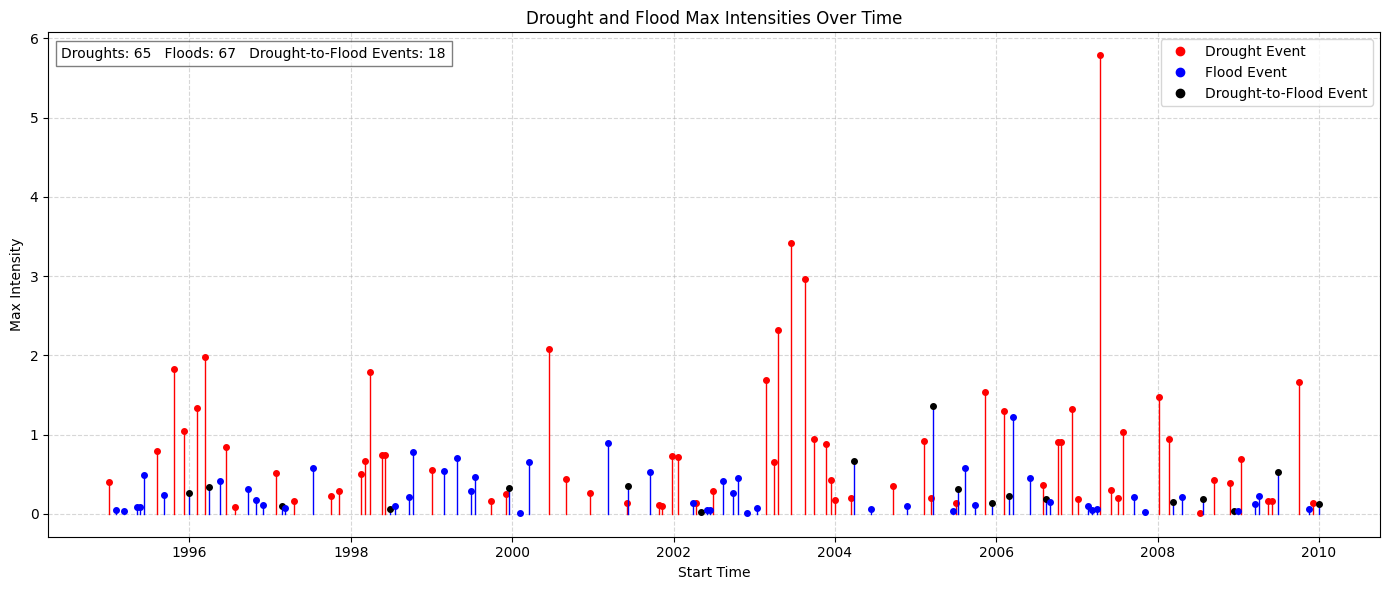

monte_carlo_values monte_carlo_p_value 0.531 18 [18 15 19 ... 13 21 14]
eca_p_value (trigger): 0.5888641173511148 65 67 18
eca_p_value (precursor): 0.694259588561046 65 67 18
Danube (Third location) - Droughts: 65, Floods: 67, p_trigger: 0.589, p_MC_trigger: 0.531, Matches: 18
{'river': 'Dnieper', 'locations': [{'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367}, {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.48264, 'longitude': 35.041132}, {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.63581}]} {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367}


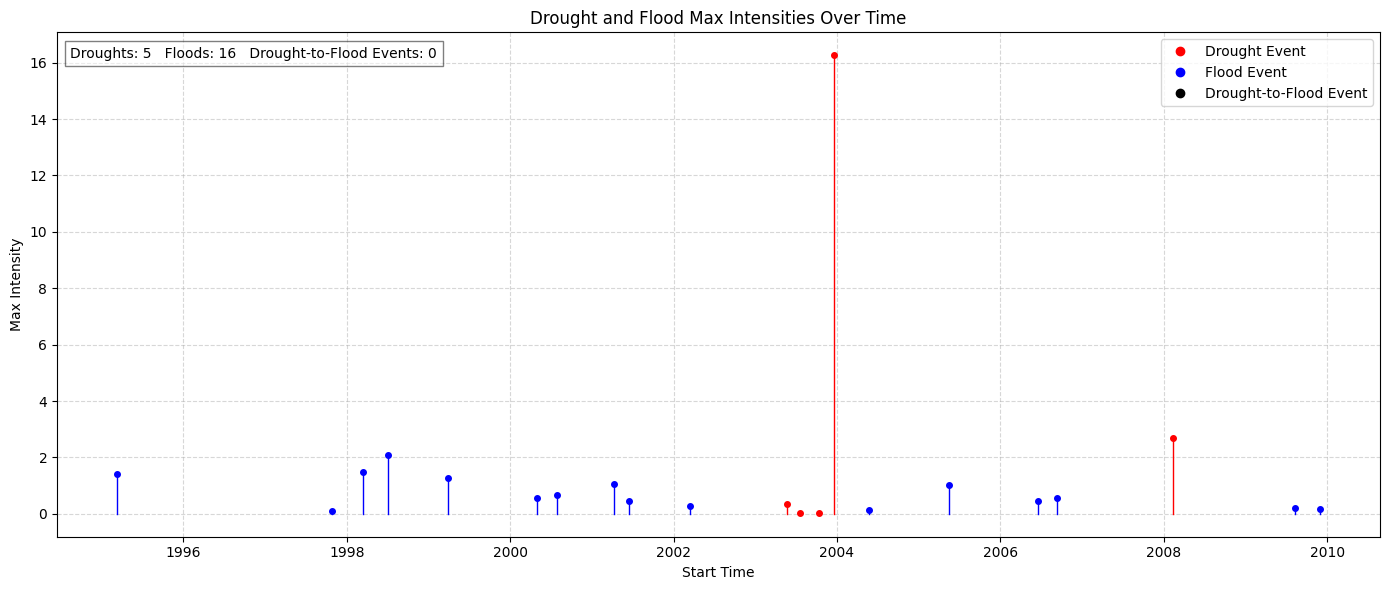

monte_carlo_values monte_carlo_p_value 1.0 0 [1 0 0 ... 0 1 0]
eca_p_value (trigger): 1.0 5 16 0
eca_p_value (precursor): 1.0 5 16 0
Dnieper (First location) - Droughts: 5, Floods: 16, p_trigger: 1.000, p_MC_trigger: 1.000, Matches: 0
{'river': 'Dnieper', 'locations': [{'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367}, {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.48264, 'longitude': 35.041132}, {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.63581}]} {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.48264, 'longitude': 35.041132}


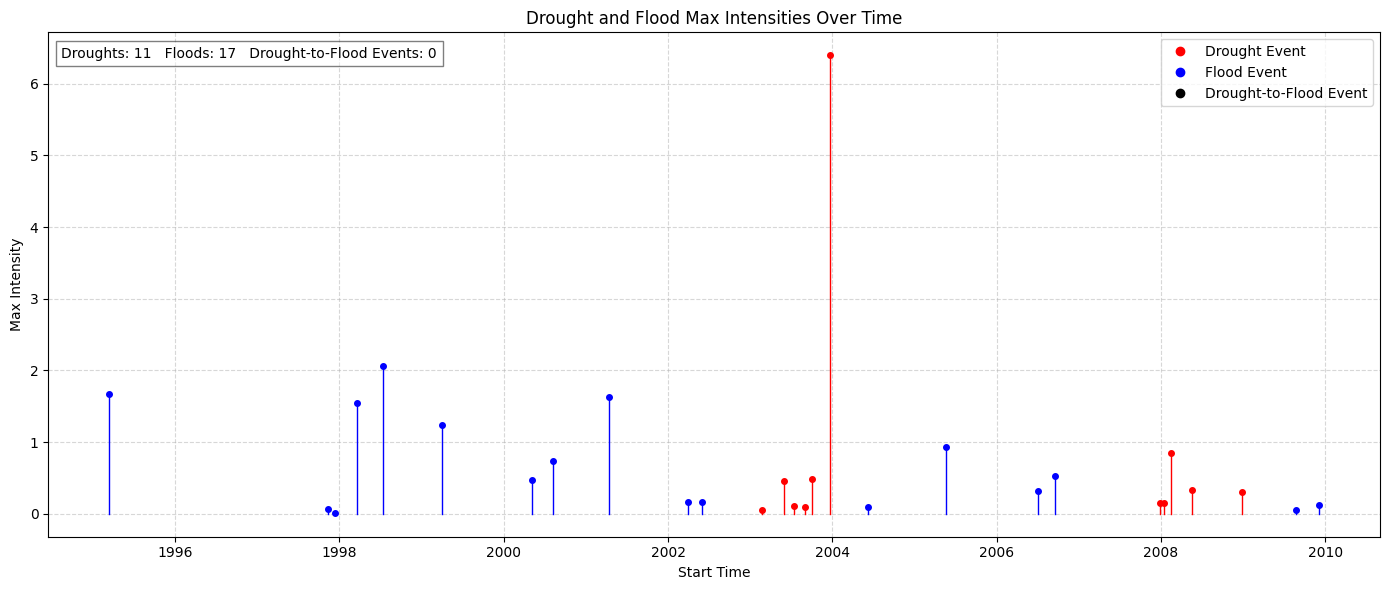

monte_carlo_values monte_carlo_p_value 1.0 0 [2 1 0 ... 2 2 0]
eca_p_value (trigger): 0.9999999999999998 11 17 0
eca_p_value (precursor): 0.9999999999999999 11 17 0
Dnieper (Second location) - Droughts: 11, Floods: 17, p_trigger: 1.000, p_MC_trigger: 1.000, Matches: 0
{'river': 'Dnieper', 'locations': [{'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367}, {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.48264, 'longitude': 35.041132}, {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.63581}]} {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.63581}


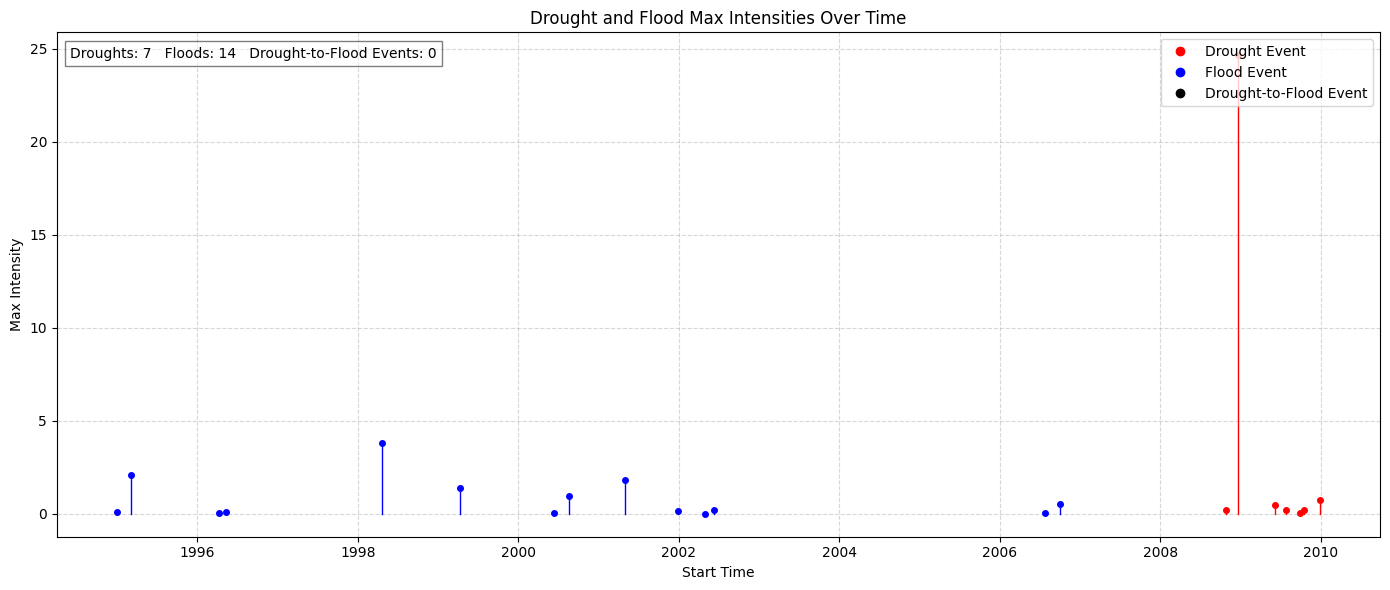

monte_carlo_values monte_carlo_p_value 1.0 0 [1 0 0 ... 0 0 0]
eca_p_value (trigger): 0.9999999999999994 7 14 0
eca_p_value (precursor): 1.0 7 14 0
Dnieper (Third location) - Droughts: 7, Floods: 14, p_trigger: 1.000, p_MC_trigger: 1.000, Matches: 0
{'river': 'Rhine', 'locations': [{'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314}, {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.28945}, {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}]} {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314}


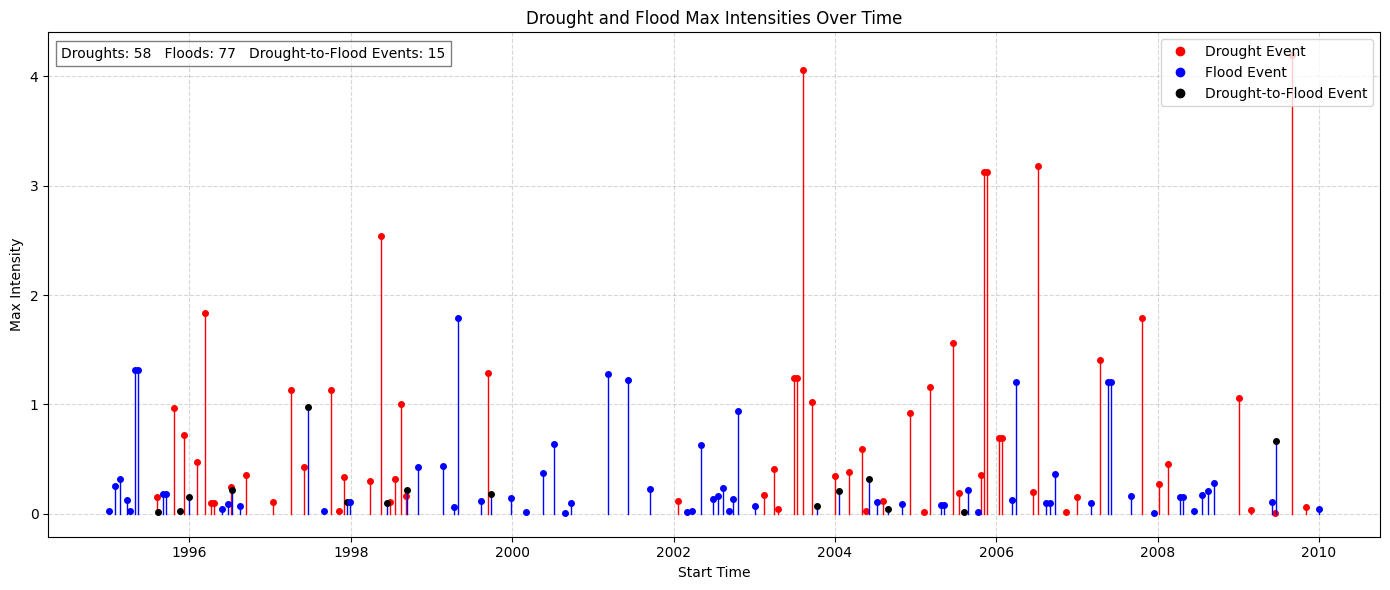

monte_carlo_values monte_carlo_p_value 0.8371 15 [20 19 17 ... 10 19 16]
eca_p_value (trigger): 0.21358294281592516 58 77 18
eca_p_value (precursor): 0.9701523912526164 58 77 18
Rhine (First location) - Droughts: 58, Floods: 77, p_trigger: 0.214, p_MC_trigger: 0.837, Matches: 18
{'river': 'Rhine', 'locations': [{'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314}, {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.28945}, {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}]} {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.28945}


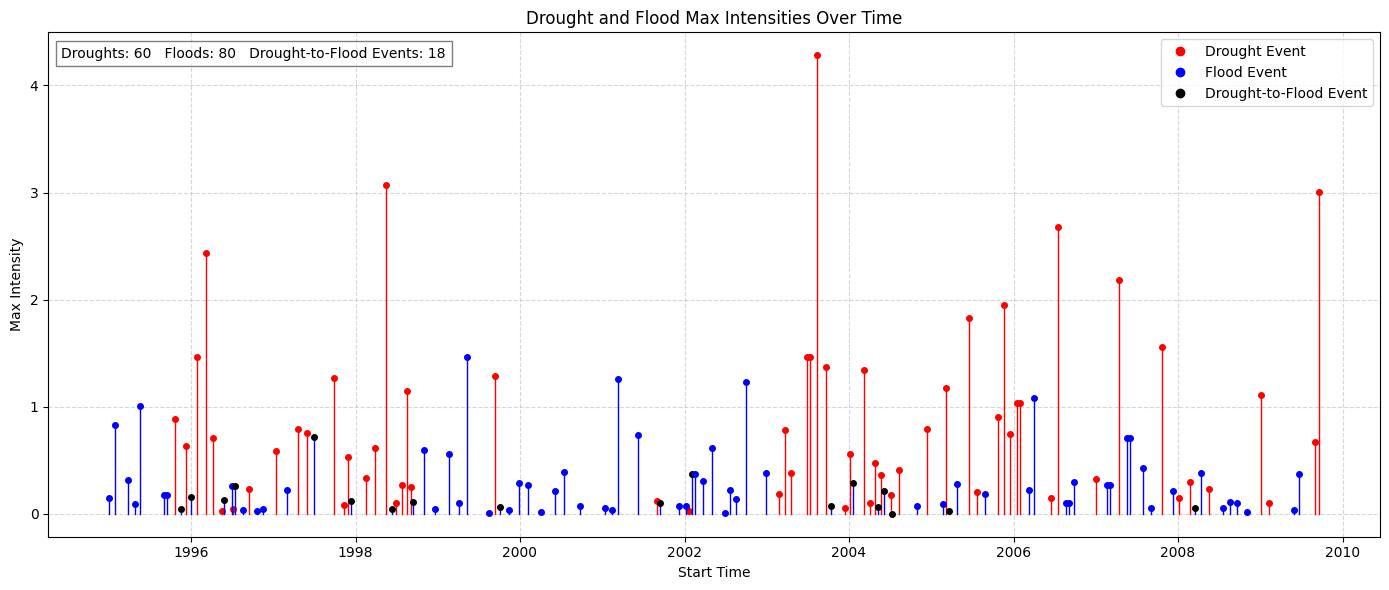

monte_carlo_values monte_carlo_p_value 0.7292 18 [20 18 20 ... 17 20 20]
eca_p_value (trigger): 0.05260827505665451 60 80 22
eca_p_value (precursor): 0.8996896168845472 60 80 22
Rhine (Second location) - Droughts: 60, Floods: 80, p_trigger: 0.053, p_MC_trigger: 0.729, Matches: 22
{'river': 'Rhine', 'locations': [{'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314}, {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.28945}, {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}]} {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}


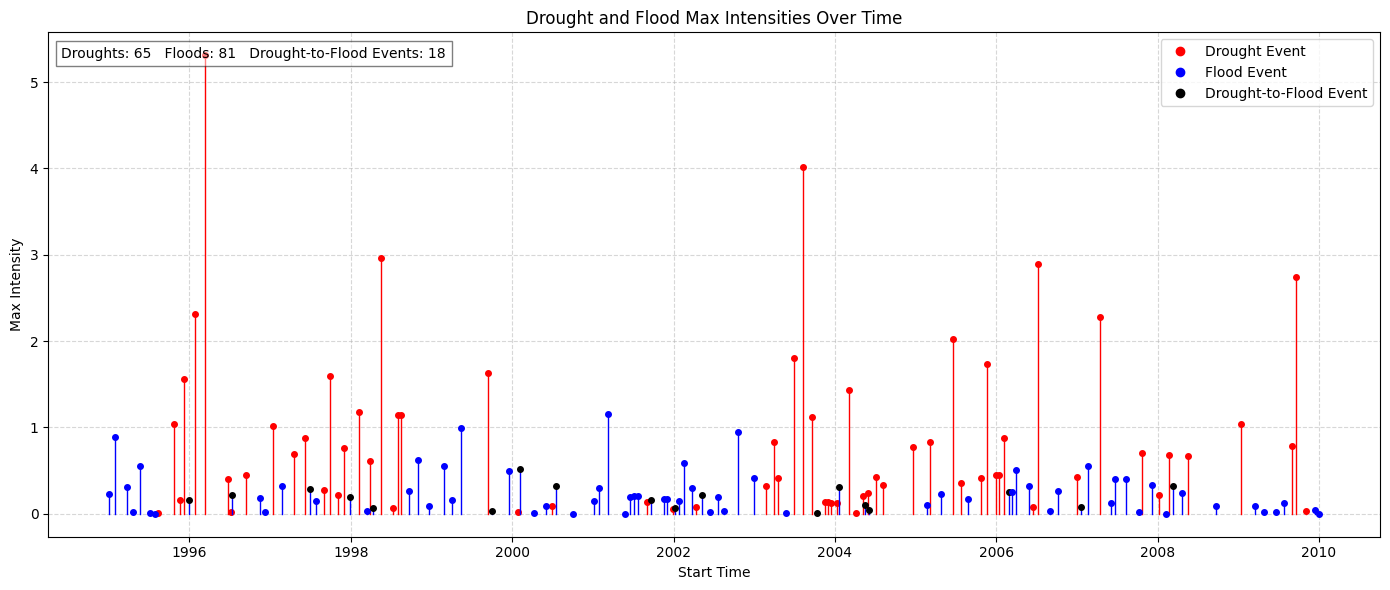

monte_carlo_values monte_carlo_p_value 0.8583 18 [21 18 19 ... 19 24 23]
eca_p_value (trigger): 0.1295133945754796 65 81 23
eca_p_value (precursor): 0.8796694099490352 65 81 23
Rhine (Third location) - Droughts: 65, Floods: 81, p_trigger: 0.130, p_MC_trigger: 0.858, Matches: 23
{'river': 'Don', 'locations': [{'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972}, {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345}, {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}]} {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972}


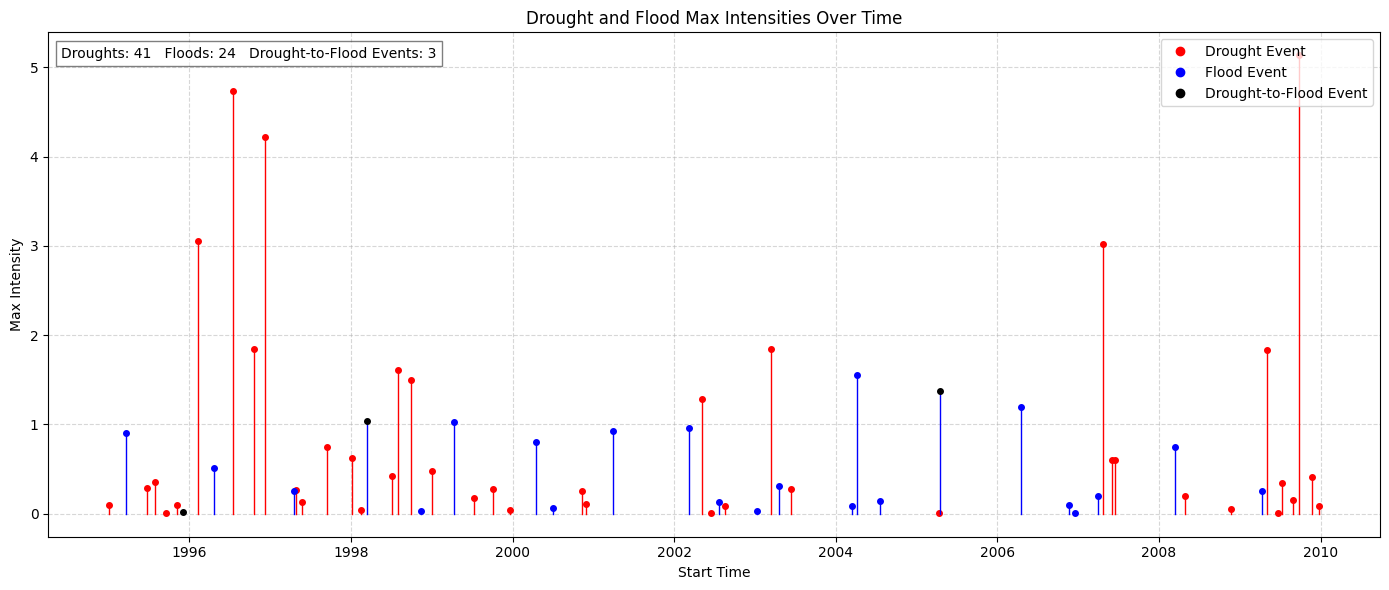

monte_carlo_values monte_carlo_p_value 0.8478 3 [7 5 2 ... 3 6 3]
eca_p_value (trigger): 0.9648508872611753 41 24 4
eca_p_value (precursor): 0.2984796861465677 41 24 4
Don (First location) - Droughts: 41, Floods: 24, p_trigger: 0.965, p_MC_trigger: 0.848, Matches: 4
{'river': 'Don', 'locations': [{'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972}, {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345}, {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}]} {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345}


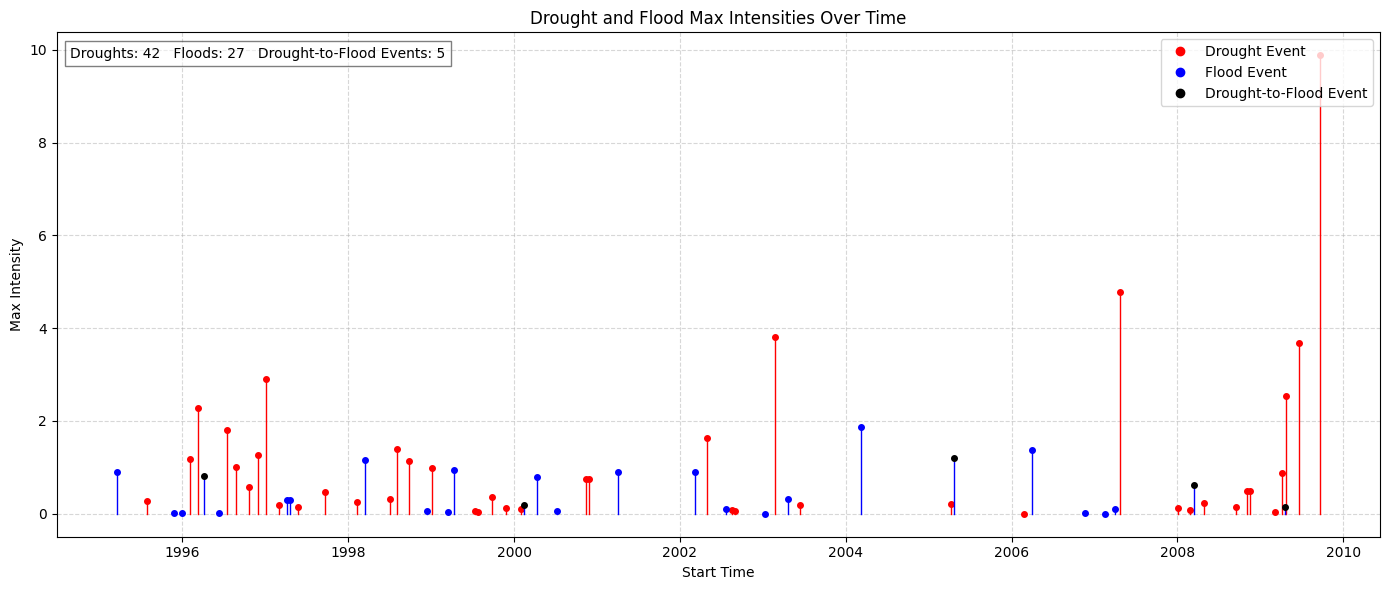

monte_carlo_values monte_carlo_p_value 0.56 5 [6 5 5 ... 3 6 3]
eca_p_value (trigger): 0.5804111061118019 42 27 8
eca_p_value (precursor): 0.01751904407864678 42 27 8
Don (Second location) - Droughts: 42, Floods: 27, p_trigger: 0.580, p_MC_trigger: 0.560, Matches: 8
{'river': 'Don', 'locations': [{'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972}, {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345}, {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}]} {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}


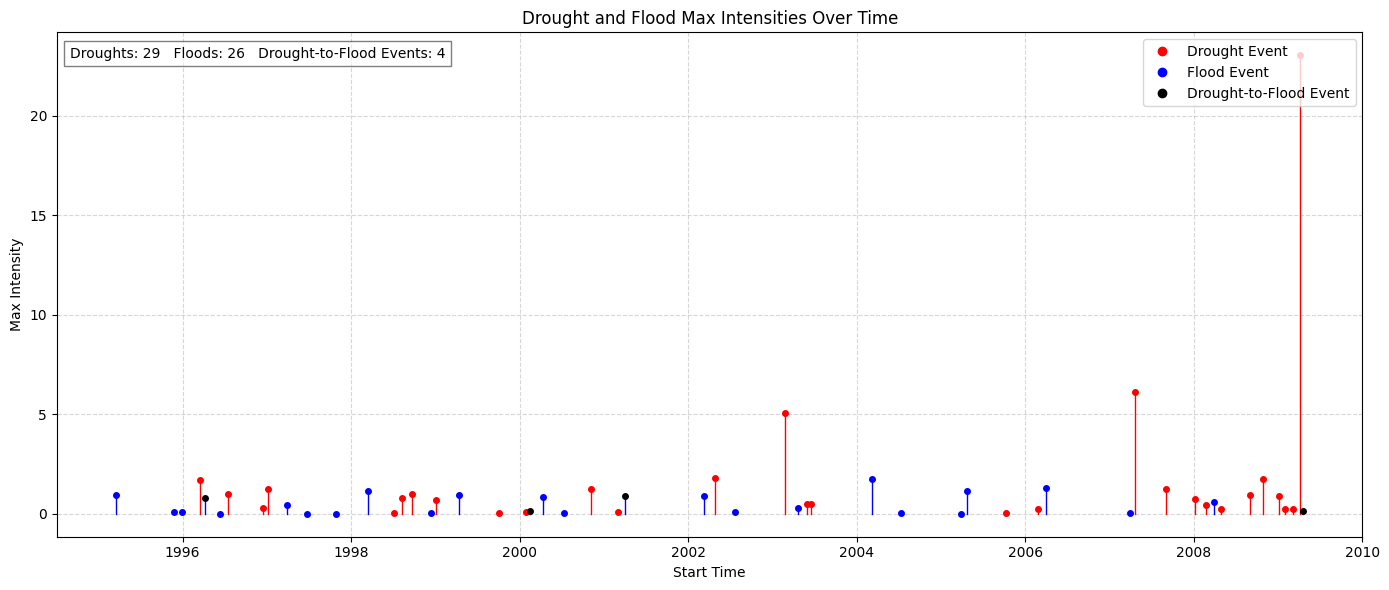

monte_carlo_values monte_carlo_p_value 0.4541 4 [6 1 3 ... 3 5 1]
eca_p_value (trigger): 0.580692353524544 29 26 4
eca_p_value (precursor): 0.4091939800873364 29 26 4
Don (Third location) - Droughts: 29, Floods: 26, p_trigger: 0.581, p_MC_trigger: 0.454, Matches: 4
{'river': 'Vistula', 'locations': [{'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.98856, 'longitude': 19.584211}, {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997}, {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.01432, 'longitude': 18.647809}]} {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.98856, 'longitude': 19.584211}


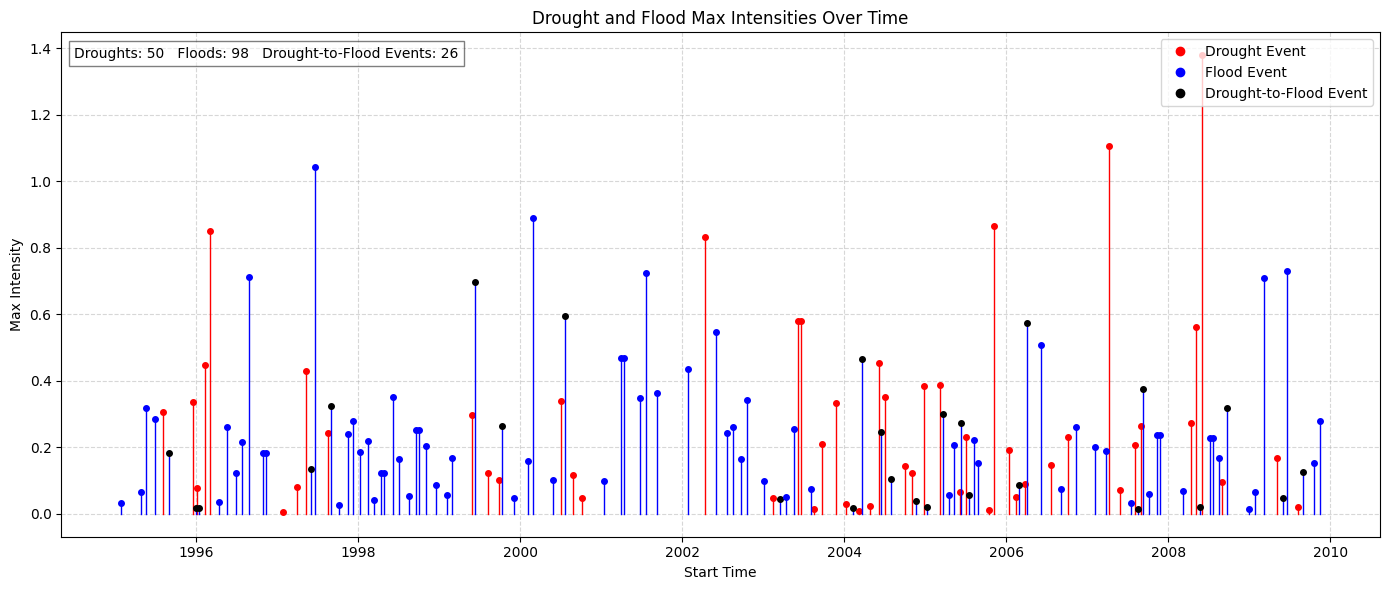

monte_carlo_values monte_carlo_p_value 0.0266 26 [25 19 17 ... 20 18 19]
eca_p_value (trigger): 5.442034442526297e-06 50 98 26
eca_p_value (precursor): 0.9972972085361553 50 98 26
Vistula (First location) - Droughts: 50, Floods: 98, p_trigger: 0.000, p_MC_trigger: 0.027, Matches: 26
{'river': 'Vistula', 'locations': [{'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.98856, 'longitude': 19.584211}, {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997}, {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.01432, 'longitude': 18.647809}]} {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997}


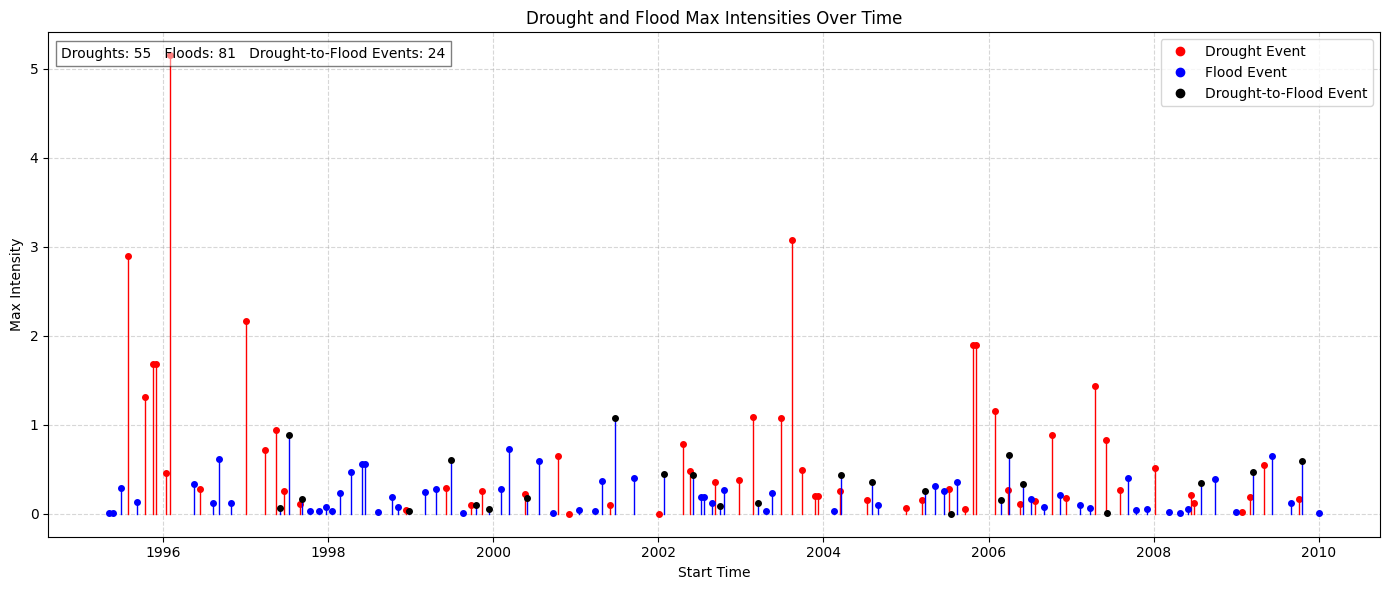

monte_carlo_values monte_carlo_p_value 0.0415 24 [17 13 19 ... 20 17 14]
eca_p_value (trigger): 0.0014796884593183464 55 81 24
eca_p_value (precursor): 0.8242089222898341 55 81 24
Vistula (Second location) - Droughts: 55, Floods: 81, p_trigger: 0.001, p_MC_trigger: 0.042, Matches: 24
{'river': 'Vistula', 'locations': [{'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.98856, 'longitude': 19.584211}, {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997}, {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.01432, 'longitude': 18.647809}]} {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.01432, 'longitude': 18.647809}


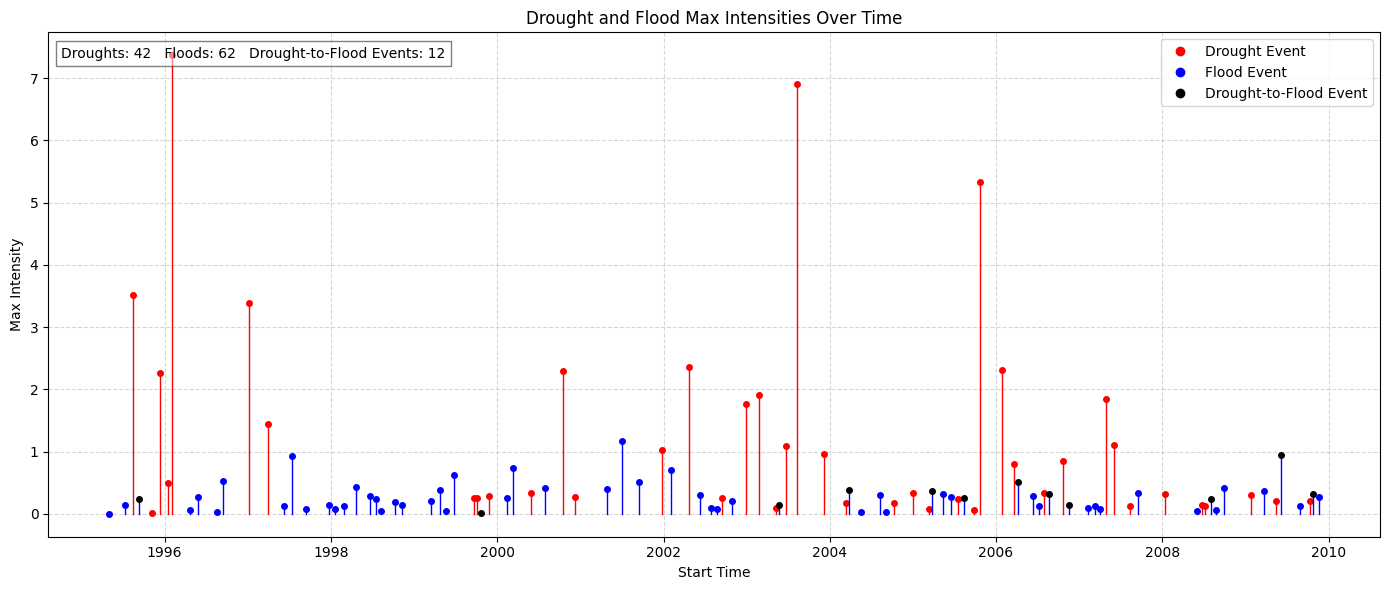

monte_carlo_values monte_carlo_p_value 0.426 12 [16 10  8 ... 11 10  6]
eca_p_value (trigger): 0.003659563132075098 42 62 16
eca_p_value (precursor): 0.6428175987332906 42 62 16
Vistula (Third location) - Droughts: 42, Floods: 62, p_trigger: 0.004, p_MC_trigger: 0.426, Matches: 16
{'river': 'Po', 'locations': [{'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335}, {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053}, {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.01556, 'longitude': 11.288393}]} {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335}


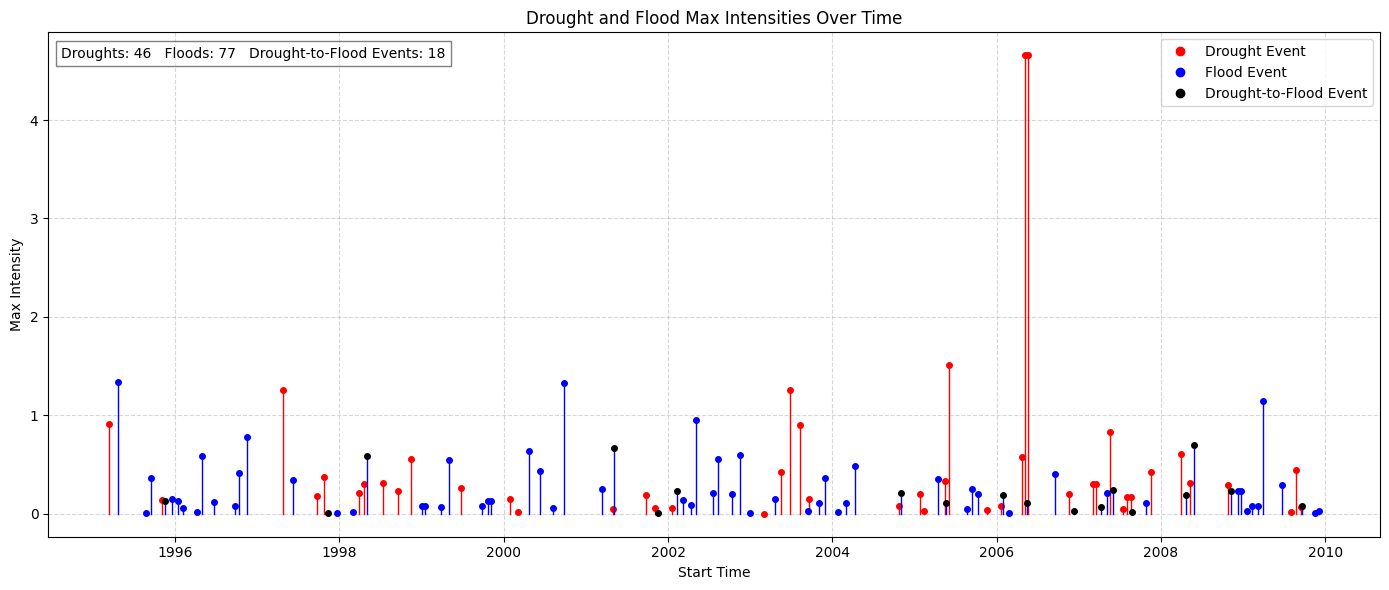

monte_carlo_values monte_carlo_p_value 0.1269 18 [12 15 17 ...  5 12 14]
eca_p_value (trigger): 0.0037949745660270243 46 77 18
eca_p_value (precursor): 0.9701523912526164 46 77 18
Po (First location) - Droughts: 46, Floods: 77, p_trigger: 0.004, p_MC_trigger: 0.127, Matches: 18
{'river': 'Po', 'locations': [{'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335}, {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053}, {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.01556, 'longitude': 11.288393}]} {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053}


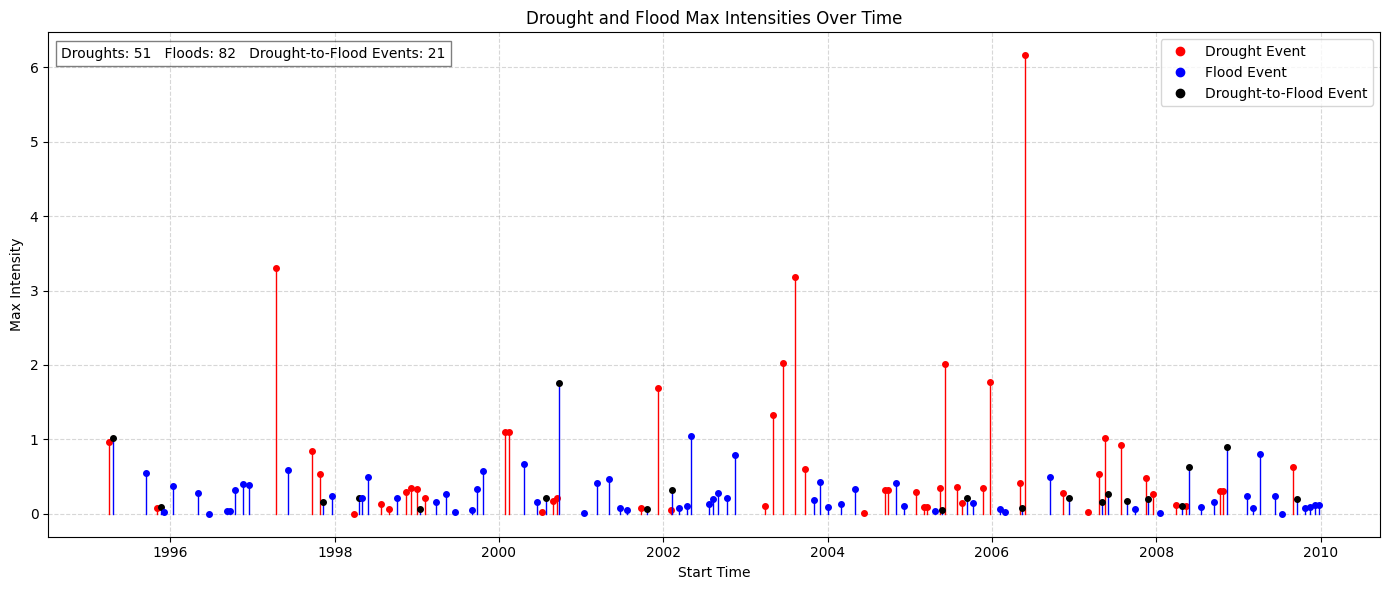

monte_carlo_values monte_carlo_p_value 0.0926 21 [11 15 18 ... 13 20 13]
eca_p_value (trigger): 3.2637467332197125e-06 51 82 27
eca_p_value (precursor): 0.6403675079391955 51 82 27
Po (Second location) - Droughts: 51, Floods: 82, p_trigger: 0.000, p_MC_trigger: 0.093, Matches: 27
{'river': 'Po', 'locations': [{'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335}, {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053}, {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.01556, 'longitude': 11.288393}]} {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.01556, 'longitude': 11.288393}


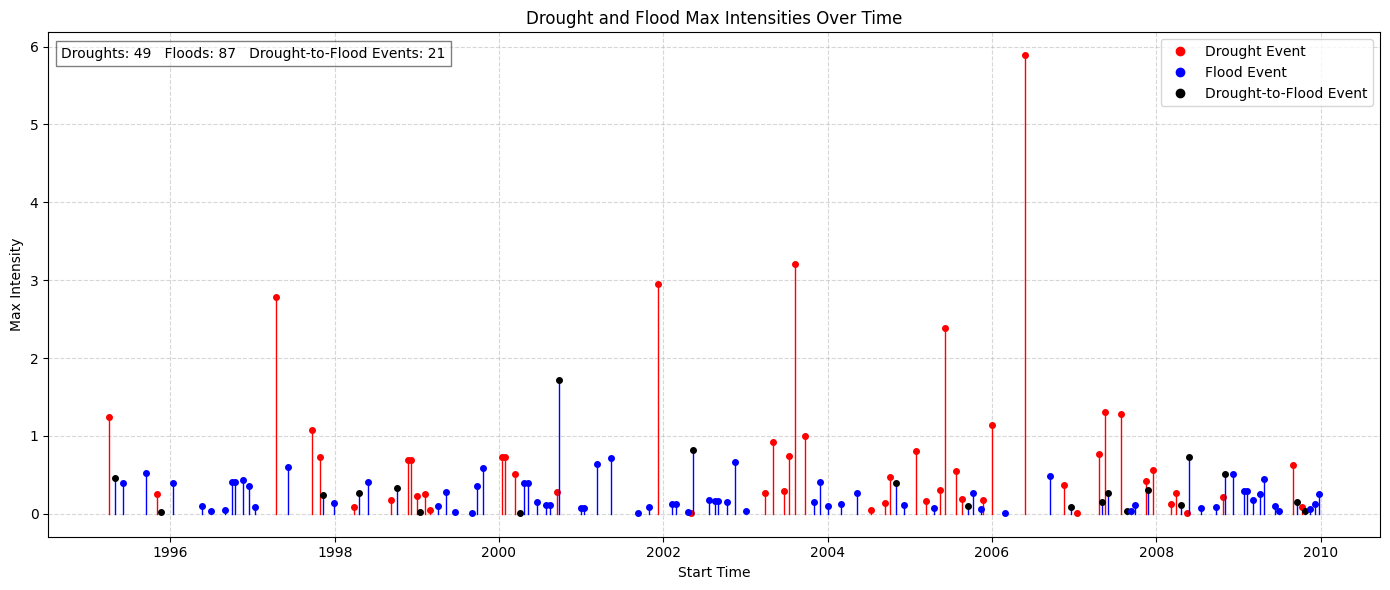

monte_carlo_values monte_carlo_p_value 0.122 21 [14 17 15 ... 19 19 19]
eca_p_value (trigger): 0.0003415914656916604 49 87 22
eca_p_value (precursor): 0.9871291257793978 49 87 22
Po (Third location) - Droughts: 49, Floods: 87, p_trigger: 0.000, p_MC_trigger: 0.122, Matches: 22
{'river': 'Elbe', 'locations': [{'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.7411}, {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592}, {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}]} {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.7411}


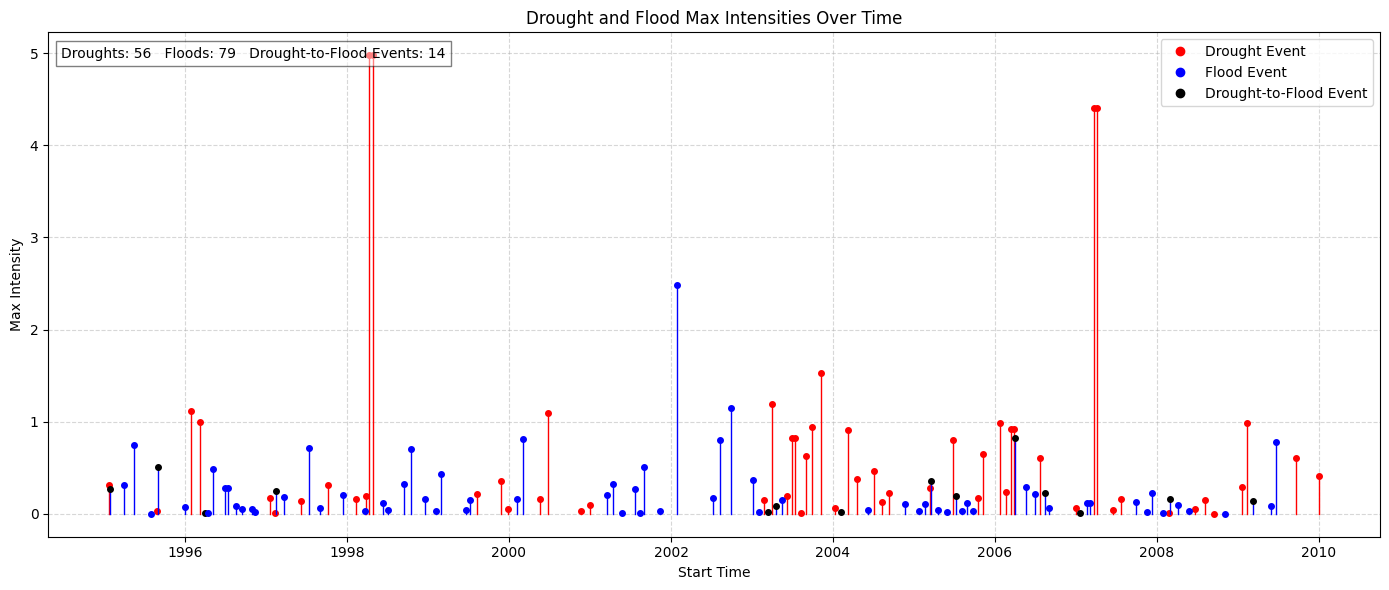

monte_carlo_values monte_carlo_p_value 0.894 14 [18 21 16 ... 19 13 12]
eca_p_value (trigger): 0.5447882242674048 56 79 14
eca_p_value (precursor): 0.9993366394897283 56 79 14
Elbe (First location) - Droughts: 56, Floods: 79, p_trigger: 0.545, p_MC_trigger: 0.894, Matches: 14
{'river': 'Elbe', 'locations': [{'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.7411}, {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592}, {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}]} {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592}


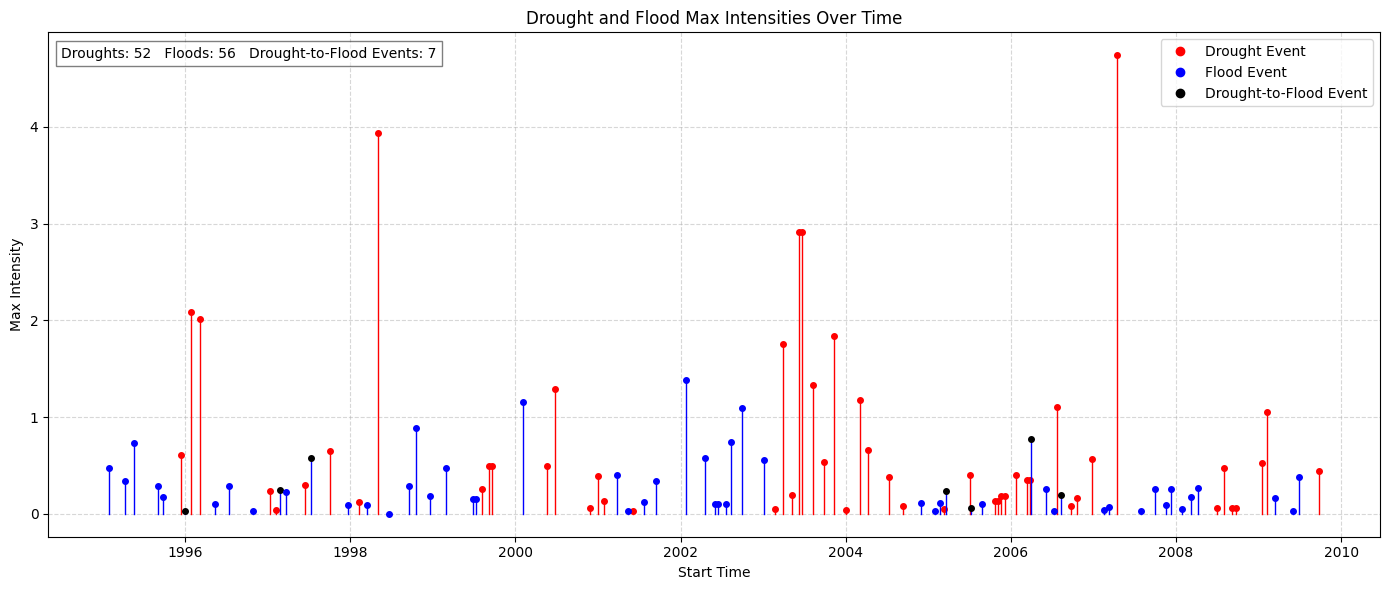

monte_carlo_values monte_carlo_p_value 0.9812 7 [14 15  9 ...  7 15  6]
eca_p_value (trigger): 0.9420597783051837 52 56 8
eca_p_value (precursor): 0.9819993331696278 52 56 8
Elbe (Second location) - Droughts: 52, Floods: 56, p_trigger: 0.942, p_MC_trigger: 0.981, Matches: 8
{'river': 'Elbe', 'locations': [{'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.7411}, {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592}, {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}]} {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}


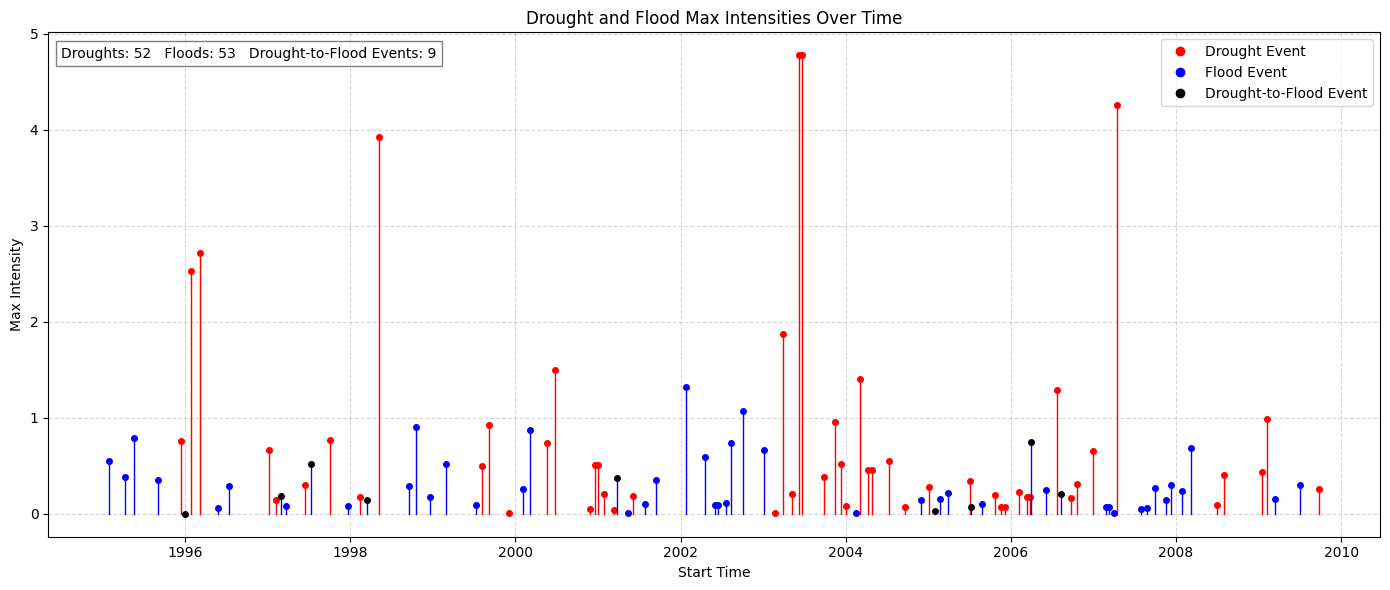

monte_carlo_values monte_carlo_p_value 0.8708 9 [11 14  7 ... 10 14 10]
eca_p_value (trigger): 0.8869967086771343 52 53 9
eca_p_value (precursor): 0.9107613549822634 52 53 9
Elbe (Third location) - Droughts: 52, Floods: 53, p_trigger: 0.887, p_MC_trigger: 0.871, Matches: 9
{'river': 'Rhône', 'locations': [{'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143}, {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692}, {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}]} {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143}


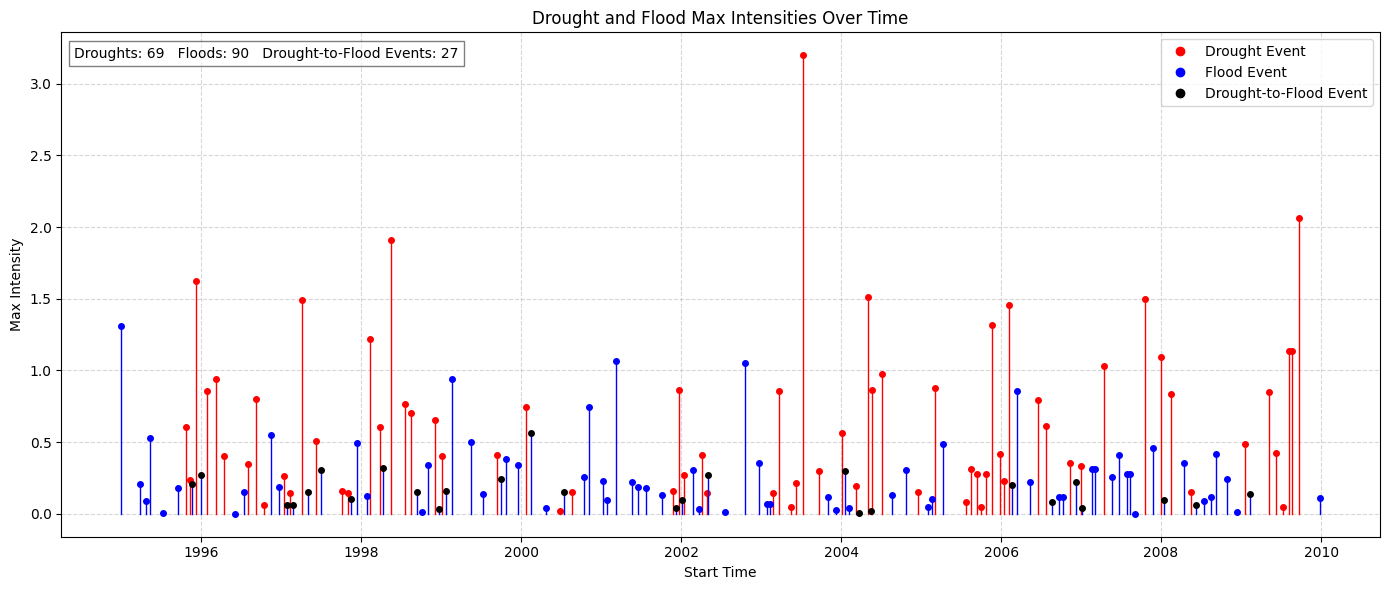

monte_carlo_values monte_carlo_p_value 0.3144 27 [28 27 26 ... 25 25 23]
eca_p_value (trigger): 0.005389594157813695 69 90 31
eca_p_value (precursor): 0.7204756025559074 69 90 31
Rhône (First location) - Droughts: 69, Floods: 90, p_trigger: 0.005, p_MC_trigger: 0.314, Matches: 31
{'river': 'Rhône', 'locations': [{'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143}, {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692}, {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}]} {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692}


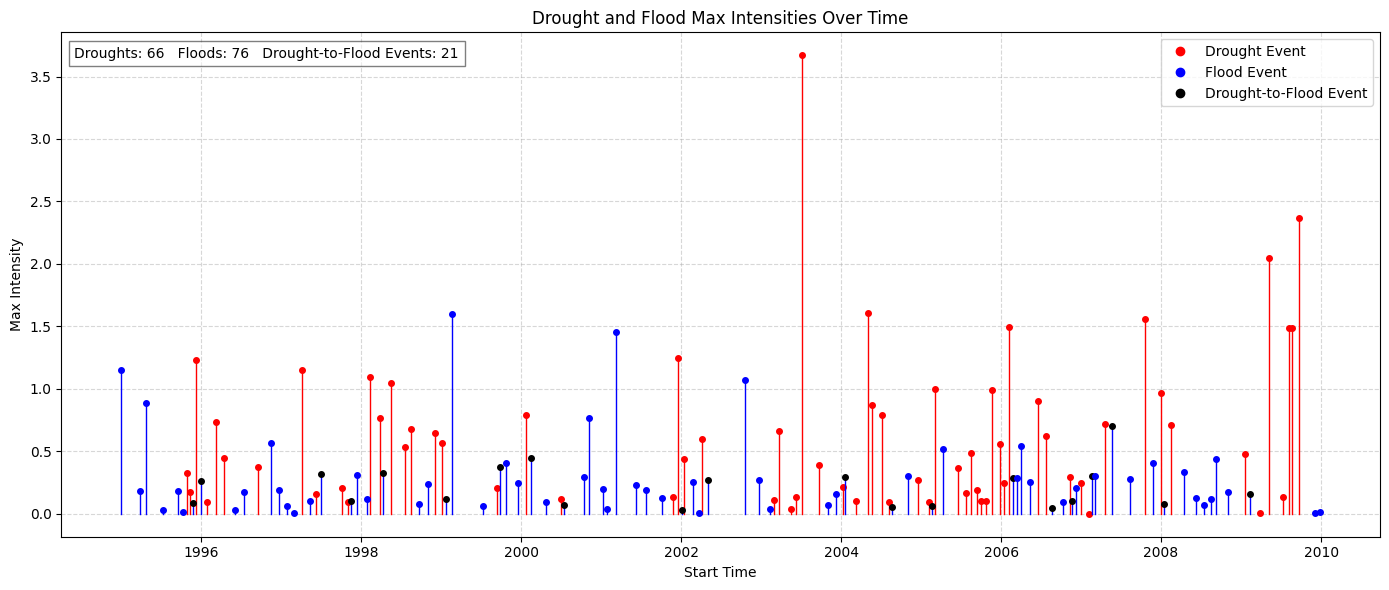

monte_carlo_values monte_carlo_p_value 0.5038 21 [26 18 19 ... 19 22 15]
eca_p_value (trigger): 0.10735188128781538 66 76 24
eca_p_value (precursor): 0.5894984850770981 66 76 24
Rhône (Second location) - Droughts: 66, Floods: 76, p_trigger: 0.107, p_MC_trigger: 0.504, Matches: 24
{'river': 'Rhône', 'locations': [{'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143}, {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692}, {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}]} {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}


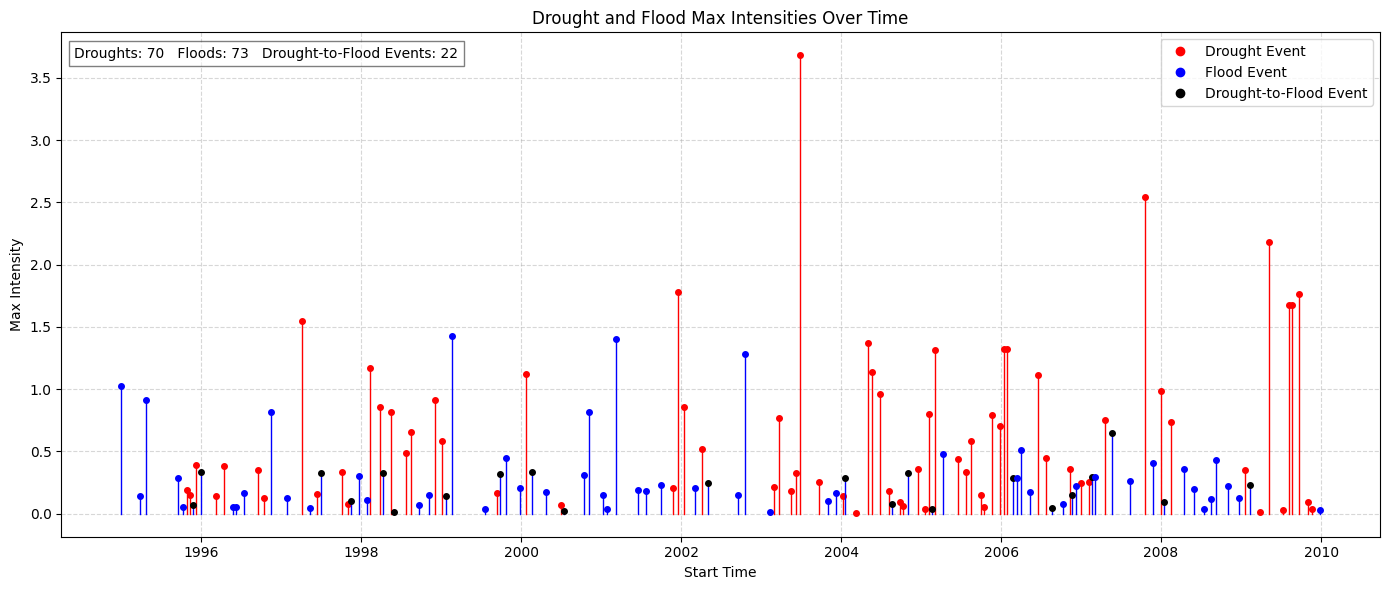

monte_carlo_values monte_carlo_p_value 0.3661 22 [23 17 19 ... 19 22 14]
eca_p_value (trigger): 0.049407064374469484 70 73 28
eca_p_value (precursor): 0.11600172990423817 70 73 28
Rhône (Third location) - Droughts: 70, Floods: 73, p_trigger: 0.049, p_MC_trigger: 0.366, Matches: 28
{'river': 'Oder', 'locations': [{'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122}, {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394}, {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}]} {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122}


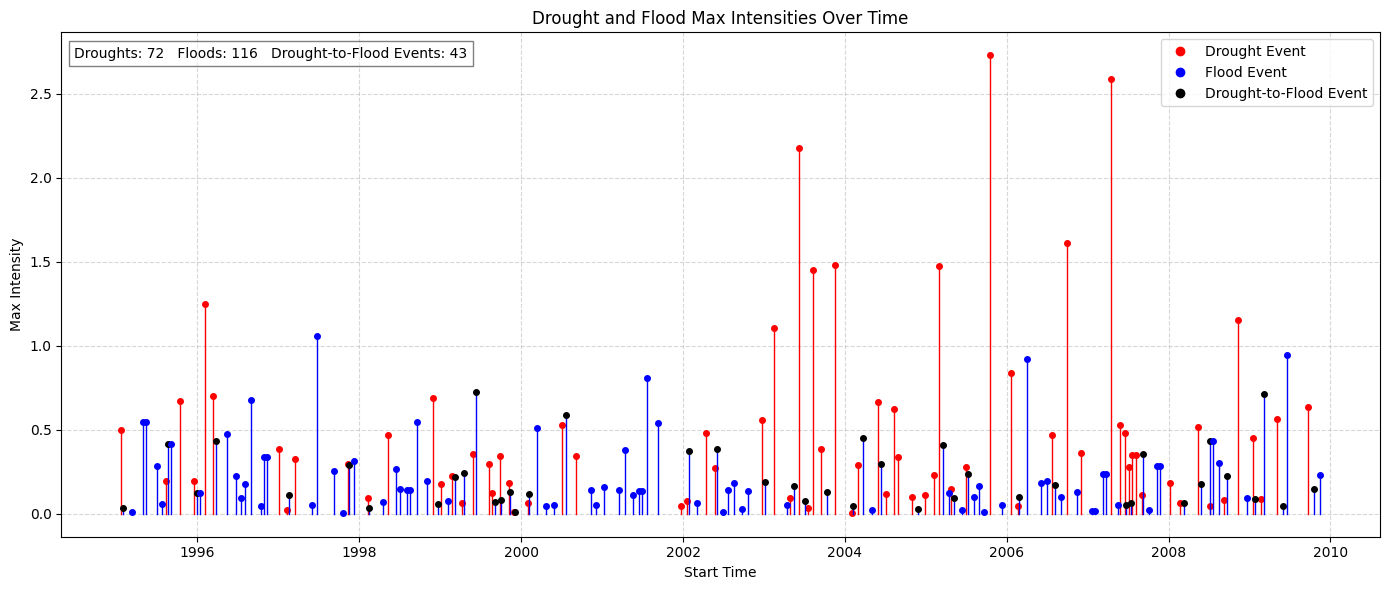

monte_carlo_values monte_carlo_p_value 0.001 43 [32 37 31 ... 32 28 33]
eca_p_value (trigger): 1.1560391748952404e-05 72 116 40
eca_p_value (precursor): 0.990364704261127 72 116 40
Oder (First location) - Droughts: 72, Floods: 116, p_trigger: 0.000, p_MC_trigger: 0.001, Matches: 40
{'river': 'Oder', 'locations': [{'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122}, {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394}, {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}]} {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394}


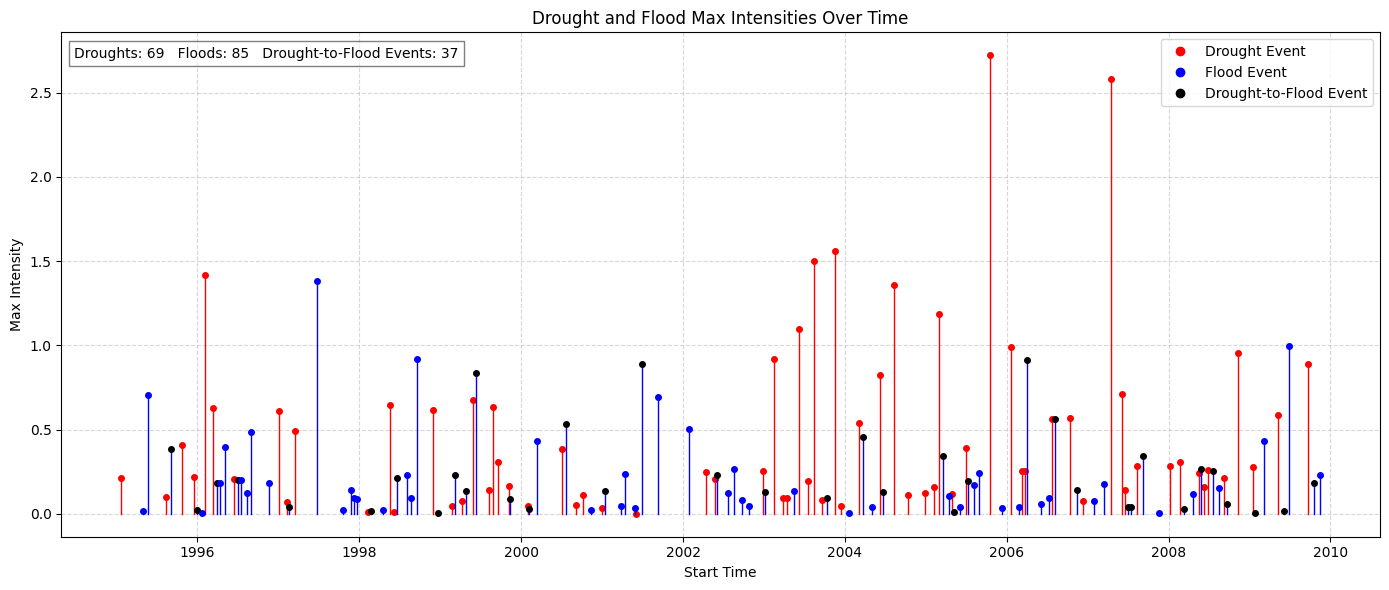

monte_carlo_values monte_carlo_p_value 0.0001 37 [24 28 24 ... 23 24 24]
eca_p_value (trigger): 8.001139887924822e-05 69 85 36
eca_p_value (precursor): 0.10565874594466751 69 85 36
Oder (Second location) - Droughts: 69, Floods: 85, p_trigger: 0.000, p_MC_trigger: 0.000, Matches: 36
{'river': 'Oder', 'locations': [{'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122}, {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394}, {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}]} {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}


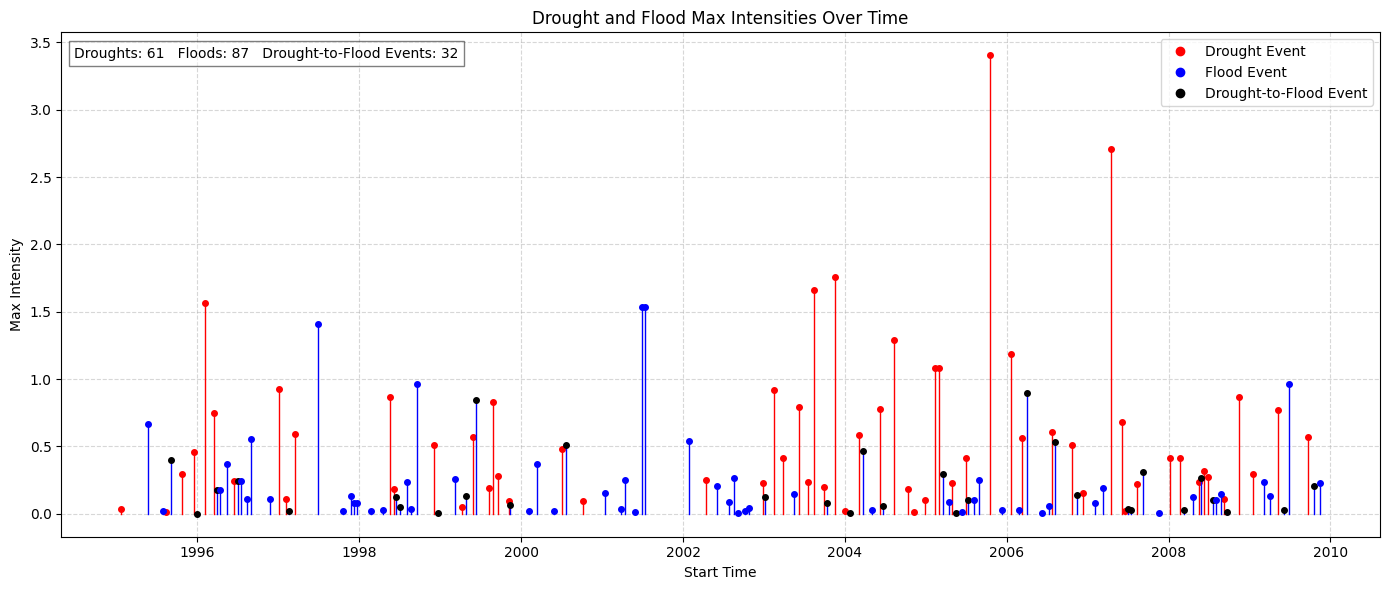

monte_carlo_values monte_carlo_p_value 0.0014 32 [23 26 25 ... 20 22 18]
eca_p_value (trigger): 5.6423804602112345e-05 61 87 31
eca_p_value (precursor): 0.562361040015256 61 87 31
Oder (Third location) - Droughts: 61, Floods: 87, p_trigger: 0.000, p_MC_trigger: 0.001, Matches: 31
{'river': 'Loire', 'locations': [{'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934}, {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064}, {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.42091, 'longitude': -0.521823}]} {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934}


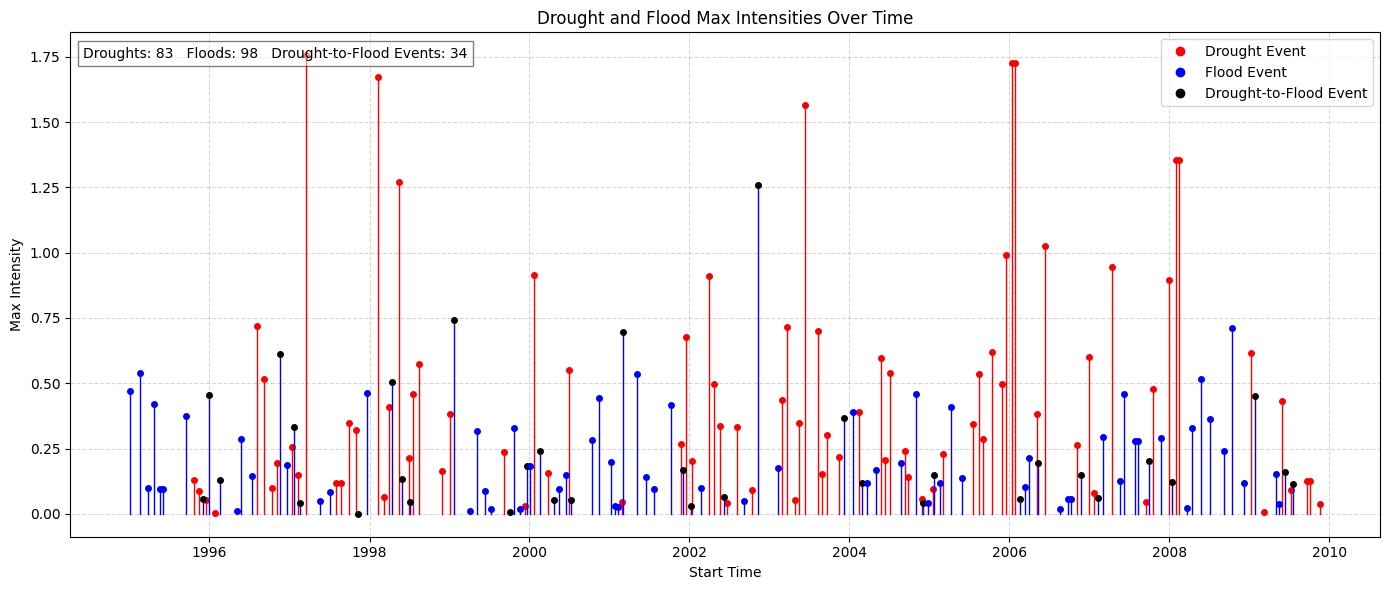

In [ ]:
def safe_format(value):
    """Safely format a value as a float with 3 decimals, or return as string if not possible."""
    try:
        return f"{float(value):.3f}"
    except (ValueError, TypeError):
        return str(value)

results = []

for river in rivers:
    for loc in river['locations']:
        lon = loc['longitude']
        lat = loc['latitude']
        village = loc['village']
        location = loc['river_location']
        river_name = river['river']
        print(river,  loc)

        # Find nearest grid point
        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        try:
            (
                p_value_monte_carlo_trigger,
                drought_count,
                flood_count,
                match_counts,
                observed_matches,
                p_value_trigger,
                p_value_precursor,
                match_count_trigger,
                match_count_precursor
            ) = drought_flood_p_value_trigger_ECA(
                data, nearest_lon, nearest_lat, first_begin, first_end,
                time_scale, threshold=1, period_after_event=4
            )
        except Exception as e:
            print(f"Error with {river_name} at {location}: {e}")
            continue

        results.append({
            'River': river_name,
            'Village': village,
            'Location': location,
            'Nearest Latitude': nearest_lat,
            'Nearest Longitude': nearest_lon,
            'P-Value Trigger Poisson': p_value_trigger,
            'P-Value Precursor Poisson': p_value_precursor,
            'P-Value Monte Carlo Trigger': p_value_monte_carlo_trigger,

            'Drought Count': drought_count,
            'Flood Count': flood_count,
            'Drought-to-flood Count': observed_matches,

        })

        print(
            f"{river_name} ({location}) - Droughts: {drought_count}, Floods: {flood_count}, "
            f"p_trigger: {safe_format(p_value_trigger)}, p_MC_trigger: {safe_format(p_value_monte_carlo_trigger)}, "
            f"Matches: {match_count_trigger}"
        )

# Export results
results_df = pd.DataFrame(results)
results_df.to_csv('/content/results_df.csv', index=False)

from google.colab import files
files.download('/content/results_df.csv')


In [ ]:
def safe_format(value):
    """Safely format a value as a float with 3 decimals, or return as string if not possible."""
    try:
        return f"{float(value):.3f}"
    except (ValueError, TypeError):
        return str(value)

results = []

for river in rivers:
    for loc in river['locations']:
        lon = loc['longitude']
        lat = loc['latitude']
        village = loc['village']
        location = loc['river_location']
        river_name = river['river']
        print(river,  loc)

        # Find nearest grid point
        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        try:
            (
                p_value_monte_carlo_trigger,
                drought_count,
                flood_count,
                match_counts,
                observed_matches,
                p_value_trigger,
                p_value_precursor,
                match_count_trigger,
                match_count_precursor
            ) = drought_flood_p_value_trigger_ECA(
                data, nearest_lon, nearest_lat, second_begin, second_end,
                time_scale, threshold=1, period_after_event=4
            )
        except Exception as e:
            print(f"Error with {river_name} at {location}: {e}")
            continue

        results.append({
            'River': river_name,
            'Village': village,
            'Location': location,
            'Nearest Latitude': nearest_lat,
            'Nearest Longitude': nearest_lon,
            'P-Value Trigger Poisson': p_value_trigger,
            'P-Value Precursor Poisson': p_value_precursor,
            'P-Value Monte Carlo Trigger': p_value_monte_carlo_trigger,

            'Drought Count': drought_count,
            'Flood Count': flood_count,
            'Drought-to-flood Count': observed_matches,

        })

        print(
            f"{river_name} ({location}) - Droughts: {drought_count}, Floods: {flood_count}, "
            f"p_trigger: {safe_format(p_value_trigger)}, p_MC_trigger: {safe_format(p_value_monte_carlo_trigger)}, "
            f"Matches: {match_count_trigger}"
        )

# Export results
results_second_df = pd.DataFrame(results)
results_second_df.to_csv('/content/results_second_df.csv', index=False)

from google.colab import files
files.download('/content/results_second_df.csv')


In [ ]:
results_df.to_csv('/content/results_df.csv', index=False)

# Optional: Download link (in notebook)
from google.colab import files
files.download('/content/results_df.csv')

In [ ]:
results_p_value_second = []

for river in rivers:
    for loc in river['locations']:
        lon = loc['longitude']
        lat = loc['latitude']
        village = loc['village']
        location =loc['river_location']
        river_name = river['river']

        # Find the nearest coordinates in the dataset
        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        # Run the function using the nearest grid point
        p_value,p_value_new, drought_count, flood_count, drought_flood_count = drought_flood_p_value(
            data, nearest_lon, nearest_lat, second_begin, second_end, time_scale, threshold, period_after_event
        )

        print(river_name, location,'Drought Count:', drought_count, 'Flood Count:',flood_count, 'Drought-Flood Pair Count:', drought_flood_count, 'p-value:', p_value)

        # Store the result
        results_p_value_second.append({
            'River': river_name,
            'Village': village,
            'Location': location,
            'Original Latitude': lat,
            'Original Longitude': lon,
            'Nearest Latitude': nearest_lat,
            'Nearest Longitude': nearest_lon,
            'P-Value': p_value,
            'Drought Count': drought_count,
            'Flood Count': flood_count,
            'Drought-Flood Pair Count': drought_flood_count
        })

# Convert to DataFrame
results_p_value_second = pd.DataFrame(results_p_value_second)

# Convert to DataFrame
results_p_value_seconds_df = pd.DataFrame(results_p_value_second)

# Show the table

results_p_value_seconds_df.to_csv('/content/results_p_value_seconds_df.csv', index=False)

# Optional: Download link (in notebook)
from google.colab import files
files.download('/content/results_p_value_seconds_df.csv')


# Calculating the copulas

In [ ]:
copula_func_drought_peak

In [ ]:
# Now we create the immages needed
def copula_func_drought_peak (data,lon, lat,begin,end,time_scale, X, Y, flood_score,threshold, period_after_event,river, village, river_location):
  # getting a subeset for the area, and
  runoff_slice_time_location_time_scale=river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale)
  # calculating the SRI values
  SRI_Values=SRI_calculate(runoff_slice_time_location_time_scale)
  runoff_maximum_weekly=river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale)
  quantiles_weekly_max=transform_to_quantiles(runoff_maximum_weekly, runoff_slice_time_location_time_scale)
  # Obtaining the intensities
  Intensities=Intensity_calc(SRI_Values,quantiles_weekly_max, threshold)

  drought_intensity=Intensities["Drought_Intensity"]
  flood_intensity=Intensities["Flood_Intensity"]


  drought_events=extract_events(drought_intensity*-1, SRI_Values*-1,quantiles_weekly_max,period_after_event)

   # Filter the DataArray
  valid_mask = np.isfinite(drought_events["drought_peak"]) & \
              np.isfinite(drought_events["quantile_max_value"])

  # Apply the mask to keep only valid rows
  drought_events = drought_events.where(valid_mask, drop=True)



  results=fit_copula(drought_events["drought_peak"], drought_events["quantile_max_value"], X, Y,quantiles_weekly_max, flood_score,river, village, river_location)

  return results

# Now we create the immages needed
def copula_func_mean_drought_severity (data,lon, lat,begin,end,time_scale, X, Y, flood_score,threshold, period_after_event,river, village, river_location):
  # getting a subeset for the area, and
  runoff_slice_time_location_time_scale=river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale)
  # calculating the SRI values
  SRI_Values=SRI_calculate(runoff_slice_time_location_time_scale)
  runoff_maximum_weekly=river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale)
  quantiles_weekly_max=transform_to_quantiles(runoff_maximum_weekly, runoff_slice_time_location_time_scale)
  # Obtaining the intensities
  Intensities=Intensity_calc(SRI_Values,quantiles_weekly_max, threshold)

  drought_intensity=Intensities["Drought_Intensity"]
  flood_intensity=Intensities["Flood_Intensity"]


  drought_events=extract_events(drought_intensity*-1, SRI_Values*-1,quantiles_weekly_max,period_after_event)

   # Filter the DataArray
  valid_mask = np.isfinite(drought_events["mean_drought_severity"]) & \
              np.isfinite(drought_events["quantile_max_value"])

  # Apply the mask to keep only valid rows
  drought_events = drought_events.where(valid_mask, drop=True)




  results=fit_copula(drought_events["mean_drought_severity"], drought_events["quantile_max_value"], X, Y,quantiles_weekly_max, flood_score,river, village, river_location)

  return results







In [ ]:
# Copula

### DIT IS EEN AANGEPASTE VERSIE
def fit_copula(data1, data2, X, Y,quantiles_weekly_max, flood_score,river, village, river_location):


      # Fit the best distributions to the data
    dist1, params1 = fit_best_distribution(data1)
    dist2, params2 = fit_best_distribution(data2)

    # Calculate the probability of drought
    prob_drought_first = dist1.cdf(X[0], *params1)
    prob_drought_second = dist1.cdf(X[1], *params1)

    # Calculate the probability of flood
    prob_flood = dist2.cdf(Y, *params2)
    prob_flood_fixed = dist2.cdf(flood_score, *params2)

    # Rank the data
    ranks1 = stats.rankdata(data1) / (len(data1) + 1)
    ranks2 = stats.rankdata(data2) / (len(data2) + 1)

    transformed_data = np.column_stack((ranks1, ranks2))

    # List of copulas to try
    cops = list(range(1, 16))

    # Fit the best copula
    cop, par, AIC = bestcop(cops, transformed_data)

    copula = cop  # Access the best copula

    n=100000

    ur = random(cop, par, n)

    # flood quantile values of interes
    flood_quantiles = np.linspace(0, 1,len(Y))




    threshold_minor_drought=np.sum(data1 <= X[0])/(len(data1) + 1)
    threshold_minor_drought=threshold_minor_drought.values

        # Initialize drought_to_flood_probability_minor
    drought_to_flood_probability_minor = []
    drought_to_flood_probability_major = []

    # Compute the probabilities for each future_flood_value in Y
    for future_flood_value in Y:
        probability = np.sum((ur[:, 0] >= threshold_minor_drought) & (ur[:, 1] >= future_flood_value)) / np.sum(ur[:, 0] >= threshold_minor_drought)
        drought_to_flood_probability_minor.append(probability)

    # Convert to numpy array for further processing if needed
    drought_to_flood_probability_minor = np.array(drought_to_flood_probability_minor)


    threshold_major_drought=np.sum(data1 <= X[1])/(len(data1) + 1)
    threshold_major_drought=threshold_major_drought.values


    # Compute the probabilities for each future_flood_value in Y
    for future_flood_value in Y:
        probability = np.sum((ur[:, 0] >= threshold_major_drought) & (ur[:, 1] >= future_flood_value)) / np.sum(ur[:, 0] >= threshold_major_drought)
        drought_to_flood_probability_major.append(probability)

    # Convert to numpy array for further processing if needed
    drought_to_flood_probability_major = np.array(drought_to_flood_probability_major)



    #Unconditional probabilities
    rolling_max= calculate_rolling_max(quantiles_weekly_max, 4)

    # Calculate the CDF values for the sequence
    cdf_values_unconditinal = 1-empirical_cdf(rolling_max,flood_quantiles)

    # conditioning on any prior drought
    ur = random(cop, par, n)
    cdf_values_conditional_on_drought = 1-empirical_cdf(ur[:,1],flood_quantiles)

    # creating the drought to flood probabilities
    n=10000
    u = random(cop, par, n)




    # Generate drought values if needed
    drought_values = np.linspace(data1.min().item(), data1.max().item(), 100)

    def calculate_fraction(prior_drought_value, future_flood_value, u):
    # Generate random values for u

      # Sum times u[:0] >= prior_drought_value and u[:1] >= future_flood_value
      # Sum the total incidents where both conditions are true
      combined_count = np.sum((u[:, 0] >= prior_drought_value) & (u[:, 1] >= future_flood_value))

      fraction = combined_count / np.sum((u[:, 0] >= prior_drought_value))

      return fraction


    # Create a meshgrid for x, y values
    B,C  = np.meshgrid(flood_quantiles,drought_values)

    # Initialize a matrix to hold the z values
    Z = np.zeros_like(B)


    print('Number of drought events:', len(data1))
    # Calculate z for each (x, y) combination
    for i in range(len(drought_values)):
        for j in range(len(flood_quantiles)):
            # Calculate the fraction based on the CDF of the distribution
            #drought_cdf = dist1.cdf(drought_values[i], *params1)
            #print("type drought_cdf", type(drought_cdf))
            #print(drought_cdf)
            drought_pseudo=np.float64(np.sum(data1 <= drought_values[i]) / (len(data1) + 1))
            # Assuming calculate_fraction takes the CDF value and the sequence[j] as inputs
            Z[i, j] = calculate_fraction(drought_pseudo, flood_quantiles[j], u)





    results = {
            "dist1": dist1,
            "dist2": dist2,
            "copula": copula,
            "AIC": AIC,
            "conditional_probability_minor_drought": drought_to_flood_probability_minor,
            "conditional_probability_major_drought": drought_to_flood_probability_major,
            "unconditional_probability": cdf_values_unconditinal,
            "conditional_probability_drought":cdf_values_conditional_on_drought,
        }

        # FIGUUR 1: Plot the drought-to-flood probability surface
    fig1 = plt.figure(figsize=(8, 6))
    plt.pcolormesh(B, C, Z, shading='auto', cmap='viridis')
    plt.colorbar(label="Probability")
    plt.xlabel("Future flood quantile")
    plt.ylabel("Prior drought value")
    plt.title("Drought to Flood Probabilities\nRiver: {} | Village: {} | River Location: {}".format(river, village, river_location))
    results["figure1"] = fig1
    plt.show()


        # Create an x-axis based on the length of your data
    x = np.arange(len(results["conditional_probability_minor_drought"]))
    x_uncon = np.arange(len(results["unconditional_probability"]))
    y_green = results["conditional_probability_minor_drought"]  # was y_red
    y_red = results["conditional_probability_major_drought"]    # was y_green

    # FIGUUR 2: Plot the probability curves
    fig2 = plt.figure()
    plt.plot(x, y_green, label='Drought-to-Flood probability | minor drought', color='green')
    plt.plot(x, y_red, label='Drought-to-Flood probability | major drought', color='red')
    plt.plot(x_uncon, results["unconditional_probability"], label='Unconditional probabilities', color='orange')

    # Fill the area between the green and red curves:
    # When green is above red, fill with green.
    plt.fill_between(x, y_green, y_red, where=(y_green > y_red), interpolate=True, color='green', alpha=0.3)
    # When red is above green, fill with red.
    plt.fill_between(x, y_green, y_red, where=(y_red >= y_green), interpolate=True, color='red', alpha=0.3)

    plt.title("Drought-to-Flood probabilities\nRiver: {} | Village: {} | River Location: {}".format(river, village, river_location))
    plt.xlabel("Future flood quantile value")
    plt.ylabel("Probability")
    plt.grid()
    plt.legend()
    results["figure2"] = fig2
    plt.show()

    return results

In [ ]:
## LAATSE VERSIE, eerste periode

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import io
import numpy as np
from PIL import Image


def process_img(img):
    """
    Converts the input to a numpy array suitable for imshow.
    If img is a matplotlib figure, save it to a buffer and load via PIL.
    Otherwise, assume it can be converted directly.
    """
    if hasattr(img, 'savefig'):
        buf = io.BytesIO()
        img.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        pil_img = Image.open(buf)
        return np.array(pil_img)
    else:
        return np.array(img)

def create_page(dp_pairs, md_pairs, page_number):
    """
    Create a composite page from pairs of images.

    Each row corresponds to one iteration:
      - Left block (columns 0 and 1): two images for Drought_Peak (image1, image2).
      - Right block (columns 2 and 3): two images for Mean_Drought_Severity (image1, image2).

    The top row (row 0) shows the titles for each block.
    """
    # Number of rows (pairs) on this page.
    rows = len(dp_pairs)
    # Create a figure; add one extra row for the titles.
    fig = plt.figure(figsize=(16, (rows + 1) * 3))
    gs = gridspec.GridSpec(rows + 1, 4, height_ratios=[0.5] + [1] * rows)

    # Add block titles.
    ax_title_left = fig.add_subplot(gs[0, 0:2])
    ax_title_left.axis('off')
    ax_title_left.text(0.5, 0.5, 'Drought Peak : First period', ha='center', va='center',
                        fontsize=16, fontweight='bold')

    ax_title_right = fig.add_subplot(gs[0, 2:4])
    ax_title_right.axis('off')
    ax_title_right.text(0.5, 0.5, 'Mean Drought Severity: First period', ha='center', va='center',
                         fontsize=16, fontweight='bold')

    # For each pair, add the images in a single row.
    for i in range(rows):
        # Extract the pair for drought peak and mean drought severity.
        dp_img1, dp_img2 = dp_pairs[i]
        md_img1, md_img2 = md_pairs[i]

        # Row index in grid: i+1 (since row 0 is for titles)
        ax_dp1 = fig.add_subplot(gs[i+1, 0])
        ax_dp1.axis('off')
        ax_dp1.imshow(process_img(dp_img1))

        ax_dp2 = fig.add_subplot(gs[i+1, 1])
        ax_dp2.axis('off')
        ax_dp2.imshow(process_img(dp_img2))

        ax_md1 = fig.add_subplot(gs[i+1, 2])
        ax_md1.axis('off')
        ax_md1.imshow(process_img(md_img1))

        ax_md2 = fig.add_subplot(gs[i+1, 3])
        ax_md2.axis('off')
        ax_md2.imshow(process_img(md_img2))

    fig.suptitle(f"Page {page_number}", fontsize=18)
    fig.tight_layout()
    return fig

# Define the save folder.
save_folder = '/content/drive/MyDrive/1. Drougt-to-flood article/4. image all - first period'
if not os.path.exists(save_folder):
    os.makedirs(save_folder)

# List to store composite pages.
pages = []

# Lists to accumulate pairs.
drought_peak_pairs = []  # each element is a tuple: (dp_image1, dp_image2)
mean_drought_pairs = []  # each element is a tuple: (md_image1, md_image2)
pair_count = 0          # count of pairs on the current page
page_count = 1          # page counter

# Loop over your rivers and locations.
for river in rivers:
    for loc in river['locations']:
        village = loc['village']
        lat = loc['latitude']
        lon = loc['longitude']
        river_location = loc['river_location']

        # Identify the nearest point.
        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        # Obtain the drought peak figures.
        X = [1, 2]
        results_drought_peak = copula_func_drought_peak(data, nearest_lon, nearest_lat,
                                                        first_begin, first_end, '1W',
                                                        X, Y, 0.9, 0.5, 4,
                                                        river['river'], village, river_location)
        dp_image1 = results_drought_peak["figure1"]
        dp_image2 = results_drought_peak["figure2"]

        # Obtain the mean drought severity figures.
        X = [0.5, 1]
        results_mean_drought_severity = copula_func_mean_drought_severity(data, nearest_lon, nearest_lat,
                                                                           first_begin, first_end, '1W',
                                                                          X, Y, 0.9, 0.5, 4,
                                                                          river['river'], village, river_location)
        md_image1 = results_mean_drought_severity["figure1"]
        md_image2 = results_mean_drought_severity["figure2"]

        # Append the pairs.
        drought_peak_pairs.append((dp_image1, dp_image2))
        mean_drought_pairs.append((md_image1, md_image2))
        pair_count += 1

        # When 8 pairs (rows) have been collected, create and save a page.
        if pair_count == 8:
            fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
            pages.append(fig)
            save_path = os.path.join(save_folder, f'page_{page_count}.png')
            fig.savefig(save_path, bbox_inches='tight')
            plt.show(fig)  # Optionally display the page.

            # Reset the accumulators for the next page.
            drought_peak_pairs = []
            mean_drought_pairs = []
            pair_count = 0
            page_count += 1

# After the loop, if there are any leftover pairs, create and save a final page.
if pair_count > 0:
    fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
    pages.append(fig)
    save_path = os.path.join(save_folder, f'page_{page_count}.png')
    fig.savefig(save_path, bbox_inches='tight')
    plt.show(fig)

# The list `pages` now contains all the composite page figures.
pages


In [ ]:
second_end

In [ ]:
## LAATSE VERSIE, tweede periode

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import io
import numpy as np
from PIL import Image

def process_img(img):
    """
    Converts the input to a numpy array suitable for imshow.
    If img is a matplotlib figure, save it to a buffer and load via PIL.
    Otherwise, assume it can be converted directly.
    """
    if hasattr(img, 'savefig'):
        buf = io.BytesIO()
        img.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        pil_img = Image.open(buf)
        return np.array(pil_img)
    else:
        return np.array(img)

def create_page(dp_pairs, md_pairs, page_number):
    """
    Create a composite page from pairs of images.

    Each row corresponds to one iteration:
      - Left block (columns 0 and 1): two images for Drought_Peak (image1, image2).
      - Right block (columns 2 and 3): two images for Mean_Drought_Severity (image1, image2).

    The top row (row 0) shows the titles for each block.
    """
    # Number of rows (pairs) on this page.
    rows = len(dp_pairs)
    # Create a figure; add one extra row for the titles.
    fig = plt.figure(figsize=(16, (rows + 1) * 3))
    gs = gridspec.GridSpec(rows + 1, 4, height_ratios=[0.5] + [1] * rows)

    # Add block titles.
    ax_title_left = fig.add_subplot(gs[0, 0:2])
    ax_title_left.axis('off')
    ax_title_left.text(0.5, 0.5, 'Drought Peak : Second period', ha='center', va='center',
                        fontsize=16, fontweight='bold')

    ax_title_right = fig.add_subplot(gs[0, 2:4])
    ax_title_right.axis('off')
    ax_title_right.text(0.5, 0.5, 'Mean Drought Severity : Second period', ha='center', va='center',
                         fontsize=16, fontweight='bold')

    # For each pair, add the images in a single row.
    for i in range(rows):
        # Extract the pair for drought peak and mean drought severity.
        dp_img1, dp_img2 = dp_pairs[i]
        md_img1, md_img2 = md_pairs[i]

        # Row index in grid: i+1 (since row 0 is for titles)
        ax_dp1 = fig.add_subplot(gs[i+1, 0])
        ax_dp1.axis('off')
        ax_dp1.imshow(process_img(dp_img1))

        ax_dp2 = fig.add_subplot(gs[i+1, 1])
        ax_dp2.axis('off')
        ax_dp2.imshow(process_img(dp_img2))

        ax_md1 = fig.add_subplot(gs[i+1, 2])
        ax_md1.axis('off')
        ax_md1.imshow(process_img(md_img1))

        ax_md2 = fig.add_subplot(gs[i+1, 3])
        ax_md2.axis('off')
        ax_md2.imshow(process_img(md_img2))

    fig.suptitle(f"Page {page_number}", fontsize=18)
    fig.tight_layout()
    return fig

# Define the save folder.
save_folder = '/content/drive/MyDrive/1. Drougt-to-flood article/4. image all - second period'
if not os.path.exists(save_folder):
    os.makedirs(save_folder)

# List to store composite pages.
pages = []

# Lists to accumulate pairs.
drought_peak_pairs = []  # each element is a tuple: (dp_image1, dp_image2)
mean_drought_pairs = []  # each element is a tuple: (md_image1, md_image2)
pair_count = 0          # count of pairs on the current page
page_count = 1          # page counter

# Loop over your rivers and locations.
for river in rivers:
    for loc in river['locations']:
        village = loc['village']
        lat = loc['latitude']
        lon = loc['longitude']
        river_location = loc['river_location']

        # Identify the nearest point.
        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        # Obtain the drought peak figures.
        X = [1, 2]
        results_drought_peak = copula_func_drought_peak(data, nearest_lon, nearest_lat,
                                                        second_begin, second_end, '1W',
                                                        X, Y, 0.9, 0.5, 4,
                                                        river['river'], village, river_location)
        dp_image1 = results_drought_peak["figure1"]
        dp_image2 = results_drought_peak["figure2"]

        # Obtain the mean drought severity figures.
        X = [0.5, 1]
        results_mean_drought_severity = copula_func_mean_drought_severity(data, nearest_lon, nearest_lat,
                                                                           second_begin, second_end, '1W',
                                                                          X, Y, 0.9, 0.5, 4,
                                                                          river['river'], village, river_location)
        md_image1 = results_mean_drought_severity["figure1"]
        md_image2 = results_mean_drought_severity["figure2"]

        # Append the pairs.
        drought_peak_pairs.append((dp_image1, dp_image2))
        mean_drought_pairs.append((md_image1, md_image2))
        pair_count += 1

        # When 8 pairs (rows) have been collected, create and save a page.
        if pair_count == 8:
            fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
            pages.append(fig)
            save_path = os.path.join(save_folder, f'page_{page_count}.png')
            fig.savefig(save_path, bbox_inches='tight')
            plt.show(fig)  # Optionally display the page.

            # Reset the accumulators for the next page.
            drought_peak_pairs = []
            mean_drought_pairs = []
            pair_count = 0
            page_count += 1

# After the loop, if there are any leftover pairs, create and save a final page.
if pair_count > 0:
    fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
    pages.append(fig)
    save_path = os.path.join(save_folder, f'page_{page_count}.png')
    fig.savefig(save_path, bbox_inches='tight')
    plt.show(fig)

# The list `pages` now contains all the composite page figures.
pages

# Extra code - Prullenbak

In [ ]:
for river in rivers:
    for loc in river['locations']:
        village = loc['village']
        lat = loc['latitude']
        lon = loc['longitude']
        # obtain the results

        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2

        # Find the index of the nearest point
        nearest_idx = distances.argmin().item()

        # Isolate the longitude and latitude of the nearest point
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        print(nearest_lon, nearest_lat)

        results=copula_func_drought_peak(data, nearest_lon, nearest_lat, first_begin, first_end, '1W', X, Y, 0.9, 0.5, 4)
        #results=copula_func_drought_peak(data, nearest_lon, nearest_lat, second_begin, second_end, '1W', X, Y, 0.9, 0.5, 4)
        # store the immages in two separate figures



In [ ]:
from vinecopulas.bivariate import *
import numpy as np
from scipy import stats

def fit_copula(data1, data2, X, Y,quantiles_weekly_max, flood_score):
      # Fit the best distributions to the data
    dist1, params1 = fit_best_distribution(data1)
    dist2, params2 = fit_best_distribution(data2)

    # Calculate the probability of drought
    prob_drought_first = dist1.cdf(X[0], *params1)
    prob_drought_second = dist1.cdf(X[1], *params1)

    # Calculate the probability of flood
    prob_flood = dist2.cdf(Y, *params2)
    prob_flood_fixed = dist2.cdf(flood_score, *params2)

    # Rank the data
    ranks1 = stats.rankdata(data1) / (len(data1) + 1)
    ranks2 = stats.rankdata(data2) / (len(data2) + 1)

    transformed_data = np.column_stack((ranks1, ranks2))

    # List of copulas to try
    cops = list(range(1, 16))

    # Fit the best copula
    cop, par, AIC = bestcop(cops, transformed_data)
    copula = cop  # Access the best copula

    # flood quantile values of interes
    flood_quantiles = np.linspace(0, 1,100)

    #sampling from the copula
    n=10000
    ui2=prob_drought_first
    uii1 = randomconditional(cop, ui2, par, n, un = 2)

    # Calculate the fraction of values in uii1 that are >= each value in the sequence
    probabilities_minor = np.array([np.mean(uii1 >= value) for value in flood_quantiles])

    ui2=prob_drought_second
    uii2 = randomconditional(cop, ui2, par, n, un = 2)
    # Calculate the fraction of values in uii1 that are >= each value in the sequence
    probabilities_major = np.array([np.mean(uii2 >= value) for value in flood_quantiles])

    #Unconditional probabilities
    rolling_max= calculate_rolling_max(quantiles_weekly_max, 4)

    # Calculate the CDF values for the sequence
    cdf_values_unconditinal = 1-empirical_cdf(rolling_max,flood_quantiles)

    # conditioning on any prior drought
    ur = random(cop, par, n)
    cdf_values_conditional_on_drought = 1-empirical_cdf(ur[:,1],flood_quantiles)

    # creating the drought to flood probabilities
    n=100000
    u = random(cop, par, n)
    drought_values=np.linspace(data1.min(),data1.max(), 100)

    def calculate_fraction(prior_drought_value, future_flood_value, u):
    # Generate random values for u

      # Sum times u[:0] >= prior_drought_value and u[:1] >= future_flood_value
      # Sum the total incidents where both conditions are true
      combined_count = np.sum((u[:, 0] >= prior_drought_value) & (u[:, 1] >= future_flood_value))

      fraction = combined_count / len(u)

      return fraction


    # Create a meshgrid for x, y values
    B, C = np.meshgrid(drought_values, flood_quantiles)

    # Initialize a matrix to hold the z values
    Z = np.zeros_like(B)


    print('Number of drought events:', len(data1))
    # Calculate z for each (x, y) combination
    for i in range(len(drought_values)):
        for j in range(len(flood_quantiles)):
            # Calculate the fraction based on the CDF of the distribution
            drought_cdf = dist1.cdf(drought_values[i], *params1)
            # Assuming calculate_fraction takes the CDF value and the sequence[j] as inputs
            Z[i, j] = calculate_fraction(drought_cdf, flood_quantiles[j], u)

    # Create the plot
    plt.figure(figsize=(8, 6))
    plt.pcolormesh(C, B, Z)  # Use 'auto' shading for smoother transitions
    plt.colorbar(label="Probability")
    plt.xlabel("future flood quantile")
    plt.ylabel("prior drought value")
    plt.title("Drought to Flood Probabilities")
    plt.show()



    results = {
            "dist1": dist1,
            "dist2": dist2,
            "copula": copula,
            "AIC": AIC,
            "conditional_probability_minor_drought": probabilities_minor,
            "conditional_probability_major_drought": probabilities_major,
            "unconditional_probability": cdf_values_unconditinal,
            "conditional_probability_drought":cdf_values_conditional_on_drought,
        }

    return results

In [ ]:
from vinecopulas.bivariate import *
import numpy as np
from scipy import stats

def fit_copula(data1, data2, X, Y, flood_score):
    # Fit the best distributions to the data
    dist1, params1 = fit_best_distribution(data1)
    dist2, params2 = fit_best_distribution(data2)

    # Calculate the probability of drought
    prob_drought_first = dist1.cdf(X[0], *params1)
    prob_drought_second = dist1.cdf(X[1], *params1)

    # Calculate the probability of flood
    prob_flood = dist2.cdf(Y, *params2)
    prob_flood_fixed = dist2.cdf(flood_score, *params2)

    # Rank the data
    ranks1 = stats.rankdata(data1) / (len(data1) + 1)
    ranks2 = stats.rankdata(data2) / (len(data2) + 1)

    transformed_data = np.column_stack((ranks1, ranks2))

    # List of copulas to try (this assumes copula indices from 1 to 15)
    cops = list(range(1, 16))

    # Fit the best copula using some method `bestcop` (Ensure this is imported/defined)
    cop, par, AIC = bestcop(cops, transformed_data)  # Assuming this is a valid function or method
    copula = cops[cop]  # Access the best copula

    # Stack the synthetic observations u and v for copula fitting
    uv_first = [[prob_drought_first] * len(Y), prob_flood]
    uv_second = [[prob_drought_second] * len(Y), prob_flood]
    uv_fixed_low = (prob_drought_first, prob_flood_fixed)
    uv_fixed_high = (prob_drought_second, prob_flood_fixed)


    u_first = np.column_stack([uv_first[0], uv_first[1]])
    u_second = np.column_stack([uv_first[0], uv_first[1]])
    # Calculate conditional probabilities
    conditional_probability_first = (1 - prob_drought_first - prob_flood + CDF(copula, u_first, par)) / (1 - prob_drought_first)
    conditional_probability_second =(1 - prob_drought_second - prob_flood + CDF(copula, u_second, par)) / (1 - prob_drought_second)


    prob_low_fixed = conditional_probability_first[find_closest_index(Y, flood_score)]
    prob_high_fixed = conditional_probability_first[find_closest_index(Y, flood_score)]

    results = {
        "dist1": dist1,
        "dist2": dist2,
        "copula": copula,
        "AIC": AIC,
        "prob_low_fixed": prob_low_fixed,
        "prob_high_fixed": prob_high_fixed,
        "conditional_probability_first": conditional_probability_first,
        "conditional_probability_second": conditional_probability_second
    }

    return results


In [ ]:
# Define the path where the image will be saved
path = "/content/gdrive/MyDrive/1. Drougt-to-flood article /4. images/rolling_max_drought_runoff_peak.png"


# Extract the data for plotting
# Assuming `drought_events["drought_peak"]` is a DataArray or pandas series
data = rolling_max  # Replace with the actual variable name if different
time = data.time if hasattr(data, 'time') else range(len(data))  # Adjust to your data's time or index

# Create the plot
plt.figure(figsize=(10, 6))

# Plot vertical lines with a dot at the top
for t, value in zip(time, data):
    plt.plot([t, t], [0, value], color='blue', linewidth=1)  # Vertical line
    plt.plot(t, value, 'o', color='blue')  # Dot at the end

# Add title and labels
plt.title("Rolling max runoff quantile, first period, Po, third location")
plt.xlabel("Time")
plt.ylabel("Mean drought severity")

# Save the plot as a PNG with a transparent background
plt.savefig(path, transparent=True, dpi=300, bbox_inches="tight")

# Display the plot
plt.show()

In [ ]:
X=[0.25,0.5]

# Sample data for the existing columns (taken from the previous example)
river_names = ["Danube", "Dnieper", "Rhine", "Don", "Vistula", "Po", "Elbe",
    "Rhône", "Oder", "Loire", "Seine", "Ebro", "Douro", "Tagus", "Weser", "Meuse"
]

river_coordinates = [
  (46.265027, 18.913613), (46.670569, 32.739474), (51.8365, 6.18055),
    (50.983861, 39.398567), (54.206746, 18.914961), (44.974524, 11.883032), (53.413083, 10.397055),
    (43.892968, 4.696954), (53.045477, 14.334038), (47.370648, -1.074400), (49.449000, 0.651228),
    (40.876517, 0.5080830), (41.123780, -8.558018), (39.094337, -8.744354), (53.279397, 8.487830),
    (51.911618, 4.249376)
]


for river, (lati, loni) in zip(river_names, river_coordinates):
    # Call the copula_func_drought_peak function with the specific latitude and longitude
    print ('River', river)
    print(river, "first period")
    cop_results = copula_func_mean_drought_severity(data, loni, lati, first_begin, first_end, '1W', X, Y, 0.9, 0.5, 4)
    print (river, "second period")
    cop_results = copula_func_mean_drought_severity(data, loni, lati, second_begin, second_end, '1W', X, Y, 0.9, 0.5, 4)


In [ ]:
# Sample data for the existing columns (taken from the previous example)
X=[1,2]

river_names = ["Danube", "Dnieper", "Rhine", "Don", "Vistula", "Po", "Elbe",
    "Rhône", "Oder", "Loire", "Seine", "Ebro", "Douro", "Tagus", "Weser", "Meuse"
]

river_coordinates = [
  (46.265027, 18.913613), (46.670569, 32.739474), (51.8365, 6.18055),
    (50.983861, 39.398567), (54.206746, 18.914961), (44.974524, 11.883032), (53.413083, 10.397055),
    (43.892968, 4.696954), (53.045477, 14.334038), (47.370648, -1.074400), (49.449000, 0.651228),
    (40.876517, 0.5080830), (41.123780, -8.558018), (39.094337, -8.744354), (53.279397, 8.487830),
    (51.911618, 4.249376)
]


for river, (lati, loni) in zip(river_names, river_coordinates):
    # Call the copula_func_drought_peak function with the specific latitude and longitude
    print ('River', river)
    print(river, "first period")
    cop_results = copula_func_drought_peak(data, loni, lati, first_begin, first_end, '1W', X, Y, 0.9, 0.5, 4)
    print (river, "second period")
    cop_results = copula_func_drought_peak(data, loni, lati, second_begin, second_end, '1W', X, Y, 0.9, 0.5, 4)



# Task
Create a table of all river locations including river name, location name, village, and the latitude and longitude rounded to two decimal places.

## Extract and Format River Locations

### Subtask:
Iterate through the `rivers` list. For each river, extract its name and iterate through its locations. For each location, extract the 'river_location' (e.g., 'First location'), 'village', 'latitude', and 'longitude'. Round the 'latitude' and 'longitude' to two decimal places. Organize this information into a suitable format for a table, ensuring all three locations for each river are captured.


**Reasoning**:
The subtask requires iterating through the 'rivers' list, extracting and formatting location details, rounding latitude and longitude to two decimal places, and storing them in a structured format suitable for a table. A code block will be used to perform these operations and store the data in a list of dictionaries.



In [ ]:
formatted_river_locations = []

for river_data in rivers:
    river_name = river_data['river']
    for location_data in river_data['locations']:
        river_location_name = location_data['river_location']
        village_name = location_data['village']
        latitude = round(location_data['latitude'], 2)
        longitude = round(location_data['longitude'], 2)

        formatted_river_locations.append({
            'River': river_name,
            'Location Name': river_location_name,
            'Village': village_name,
            'Latitude': latitude,
            'Longitude': longitude
        })

# Display the first few entries to verify the format
print(formatted_river_locations[:5])

NameError: name 'rivers' is not defined

**Reasoning**:
The previous code failed because the 'rivers' variable was not defined. I need to include the definition of the 'rivers' list from cell 'xqo7beYw5i6t' in the current code block to make it accessible.



In [ ]:
rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]

formatted_river_locations = []

for river_data in rivers:
    river_name = river_data['river']
    for location_data in river_data['locations']:
        river_location_name = location_data['river_location']
        village_name = location_data['village']
        latitude = round(location_data['latitude'], 2)
        longitude = round(location_data['longitude'], 2)

        formatted_river_locations.append({
            'River': river_name,
            'Location Name': river_location_name,
            'Village': village_name,
            'Latitude': latitude,
            'Longitude': longitude
        })

# Display the first few entries to verify the format
print(formatted_river_locations[:5])


[{'River': 'Danube', 'Location Name': 'First location', 'Village': 'Aschach an der Donau', 'Latitude': 48.37, 'Longitude': 14.03}, {'River': 'Danube', 'Location Name': 'Second location', 'Village': 'Visegrád', 'Latitude': 43.79, 'Longitude': 19.29}, {'River': 'Danube', 'Location Name': 'Third location', 'Village': 'Donji Milanovac', 'Latitude': 44.47, 'Longitude': 22.16}, {'River': 'Dnieper', 'Location Name': 'First location', 'Village': 'Krementsjoek', 'Latitude': 49.05, 'Longitude': 33.41}, {'River': 'Dnieper', 'Location Name': 'Second location', 'Village': 'Dnipro', 'Latitude': 48.48, 'Longitude': 35.04}]


**Reasoning**:
The extracted and formatted river location data is currently in a list of dictionaries. To present this information in a table format as requested by the main task, it should be converted into a pandas DataFrame.



In [ ]:
import pandas as pd

# Convert the list of dictionaries to a pandas DataFrame
river_locations_df = pd.DataFrame(formatted_river_locations)

# Display the DataFrame
print(river_locations_df)

      River    Location Name                Village  Latitude  Longitude
0    Danube   First location   Aschach an der Donau     48.37      14.03
1    Danube  Second location               Visegrád     43.79      19.29
2    Danube   Third location        Donji Milanovac     44.47      22.16
3   Dnieper   First location           Krementsjoek     49.05      33.41
4   Dnieper  Second location                 Dnipro     48.48      35.04
5   Dnieper   Third location                Cherson     46.64      32.64
6     Rhine   First location            Straatsburg     48.47       7.76
7     Rhine  Second location                  Mainz     49.99       8.29
8     Rhine   Third location               Nijmegen     51.85       5.86
9       Don   First location          Nikolaevskaya     47.60      41.49
10      Don  Second location          Kochetovskaya     47.57      40.84
11      Don   Third location           Rostov - Dov     47.19      39.67
12  Vistula   First location                Łączany

## Final Task

### Subtask:
Present the generated table to the user.


## Summary:

### Q&A
The task was to create a table of all river locations including river name, location name, village, and the latitude and longitude rounded to two decimal places. This task was successfully completed.

### Data Analysis Key Findings
*   The raw `rivers` data, containing nested dictionaries, was successfully processed.
*   For each of the 16 rivers, three distinct locations were extracted, resulting in a total of 48 individual river location entries.
*   Latitude and longitude values for all locations were accurately rounded to two decimal places as required.
*   The extracted and formatted data was then structured into a pandas DataFrame, providing a clear tabular representation of river name, location name, village, latitude, and longitude for all entries.

### Insights or Next Steps
*   The structured river location data in the DataFrame is now ready for various applications such as geographic mapping, statistical analysis of location distribution, or integration into a larger database.
*   Further analysis could involve calculating distances between consecutive locations on the same river or visualizing these locations on an interactive map.


# Task
**Extract Po River Runoff Data**

**Reasoning:**
To fulfill the first step of the plan, I need to extract the runoff data for the 'Po' river at its 'Second location'. This involves:
1.  Identifying the longitude and latitude for the 'Po' river's 'Second location' from the `rivers` list.
2.  Using these coordinates along with the `data` xarray Dataset, `first_begin`, `first_end`, and `time_scale` variables to call the `river_runoff_time_location_mean` function. This function will extract and resample the `dis06` runoff data.

I will iterate through the `rivers` list to find the 'Po' river and its 'Second location' coordinates. Then I'll call the `river_runoff_time_location_mean` function to get the runoff data.

## Extract Po River Runoff Data

### Subtask:
Identify the longitude and latitude for the 'Po' river's 'Second location'. Use these coordinates to extract the `dis06` runoff data from the main `data` xarray Dataset for that specific location.


**Reasoning**:
First, I will find the 'Po' river in the `rivers` list and extract the latitude and longitude for its 'Second location'. Then, I will use these coordinates along with other predefined variables to call the `river_runoff_time_location_mean` function to get the runoff data.



In [ ]:
po_lon = None
po_lat = None

for river_data in rivers:
    if river_data['river'] == 'Po':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                po_lon = location_data['longitude']
                po_lat = location_data['latitude']
                break
    if po_lon is not None: # Break outer loop once found
        break

if po_lon is None or po_lat is None:
    raise ValueError("Po river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Po location
distances = (data.longitude - po_lon)**2 + (data.latitude - po_lat)**2
nearest_idx = distances.argmin().item()
nearest_po_lon = data.longitude[nearest_idx].item()
nearest_po_lat = data.latitude[nearest_idx].item()

# Call the river_runoff_time_location_mean function
po_runoff_data = river_runoff_time_location_mean(
    data, nearest_po_lon, nearest_po_lat, first_begin, first_end, time_scale
)

print(f"Extracted runoff data for Po river (Second location) at nearest coordinates: Latitude {nearest_po_lat:.2f}, Longitude {nearest_po_lon:.2f}")
print(po_runoff_data)


NameError: name 'rivers' is not defined

**Reasoning**:
The previous code failed because the `rivers` variable was not defined. I need to include the definition of the `rivers` list in the current code block to make it accessible before being used.



In [ ]:
rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]

po_lon = None
po_lat = None

for river_data in rivers:
    if river_data['river'] == 'Po':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                po_lon = location_data['longitude']
                po_lat = location_data['latitude']
                break
    if po_lon is not None: # Break outer loop once found
        break

if po_lon is None or po_lat is None:
    raise ValueError("Po river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Po location
distances = (data.longitude - po_lon)**2 + (data.latitude - po_lat)**2
nearest_idx = distances.argmin().item()
nearest_po_lon = data.longitude[nearest_idx].item()
nearest_po_lat = data.latitude[nearest_idx].item()

# Call the river_runoff_time_location_mean function
po_runoff_data = river_runoff_time_location_mean(
    data, nearest_po_lon, nearest_po_lat, first_begin, first_end, time_scale
)

print(f"Extracted runoff data for Po river (Second location) at nearest coordinates: Latitude {nearest_po_lat:.2f}, Longitude {nearest_po_lon:.2f}")
print(po_runoff_data)


NameError: name 'data' is not defined

**Reasoning**:
The previous code failed because the `data`, `first_begin`, `first_end`, and `time_scale` variables were not defined within the current code block. I need to include their definitions from earlier cells to make them accessible.



In [ ]:
import xarray as xr

input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"
data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])

first_begin=0
first_end=5479
second_begin=5480
second_end=10958
time_scale="1W"

rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]

po_lon = None
po_lat = None

for river_data in rivers:
    if river_data['river'] == 'Po':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                po_lon = location_data['longitude']
                po_lat = location_data['latitude']
                break
    if po_lon is not None: # Break outer loop once found
        break

if po_lon is None or po_lat is None:
    raise ValueError("Po river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Po location
distances = (data.longitude - po_lon)**2 + (data.latitude - po_lat)**2
nearest_idx = distances.argmin().item()
nearest_po_lon = data.longitude[nearest_idx].item()
nearest_po_lat = data.latitude[nearest_idx].item()

# Call the river_runoff_time_location_mean function
po_runoff_data = river_runoff_time_location_mean(
    data, nearest_po_lon, nearest_po_lat, first_begin, first_end, time_scale
)

print(f"Extracted runoff data for Po river (Second location) at nearest coordinates: Latitude {nearest_po_lat:.2f}, Longitude {nearest_po_lon:.2f}")
print(po_runoff_data)


NameError: name 'river_runoff_time_location_mean' is not defined

**Reasoning**:
The previous code failed with a `NameError` because the `river_runoff_time_location_mean` function was not defined. I need to include the definition of this function from the earlier cells into the current code block to ensure all necessary components are available.



In [ ]:
import xarray as xr
import numpy as np # Added for np.isinf

input_file="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"
data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])

first_begin=0
first_end=5479
second_begin=5480
second_end=10958
time_scale="1W"

def river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the average runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled and averaged runoff data.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the mean
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).mean(dim='valid_time')

    # Debug information
   # print("Sample of runoff data:", runoff_slice_time_location_time_scale['dis06'][:10])
   # print("NaN values count:", runoff_slice_time_location_time_scale['dis06'].isnull().sum().item())
    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
   # print("lon:", lon, "lat:",lat)

    return runoff_slice_time_location_time_scale


rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 43.787648, 'longitude': 19.292771},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Glogow', 'latitude': 51.671335, 'longitude': 16.083664}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Charleville-Mézières', 'latitude': 49.783665, 'longitude': 4.720671 },
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]

po_lon = None
po_lat = None

for river_data in rivers:
    if river_data['river'] == 'Po':
        for location_data in river_data['locations']:
            if location_data['river_location'] == 'Second location':
                po_lon = location_data['longitude']
                po_lat = location_data['latitude']
                break
    if po_lon is not None: # Break outer loop once found
        break

if po_lon is None or po_lat is None:
    raise ValueError("Po river's 'Second location' coordinates not found.")

# Find the nearest grid point in the data for the extracted Po location
distances = (data.longitude - po_lon)**2 + (data.latitude - po_lat)**2
nearest_idx = distances.argmin().item()
nearest_po_lon = data.longitude[nearest_idx].item()
nearest_po_lat = data.latitude[nearest_idx].item()

# Call the river_runoff_time_location_mean function
po_runoff_data = river_runoff_time_location_mean(
    data, nearest_po_lon, nearest_po_lat, first_begin, first_end, time_scale
)

print(f"Extracted runoff data for Po river (Second location) at nearest coordinates: Latitude {nearest_po_lat:.2f}, Longitude {nearest_po_lon:.2f}")
print(po_runoff_data)


Infinite values count: 0
Extracted runoff data for Po river (Second location) at nearest coordinates: Latitude 45.06, Longitude 9.71
<xarray.Dataset> Size: 13kB
Dimensions:     (valid_time: 784)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 1995-01-01 ... 2010-01-03
    village     object 8B 'Piacenza'
    river       object 8B 'Po'
    surface     float64 8B 0.0
    point       object 8B (np.float64(45.05833333333487), np.float64(9.708333...
    latitude    float64 8B 45.06
    longitude   float64 8B 9.708
Data variables:
    dis06       (valid_time) float64 6kB 462.1 371.8 346.4 ... 1.163e+03 946.9
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2024-12-20T22:25 GRIB to CDM+CF via cfgrib-0

## Plot Runoff Time Series with Split

### Subtask:
Generate a time series plot of the extracted `dis06` runoff data. Calculate the middle point of the time series and add a vertical line at this point to split the dataset visually.


**Reasoning**:
The subtask requires generating a time series plot of the extracted runoff data, calculating the middle point of the time series, and adding a vertical line at this point to split the dataset visually. I will use `matplotlib.pyplot` to create the plot and add the vertical line as instructed.



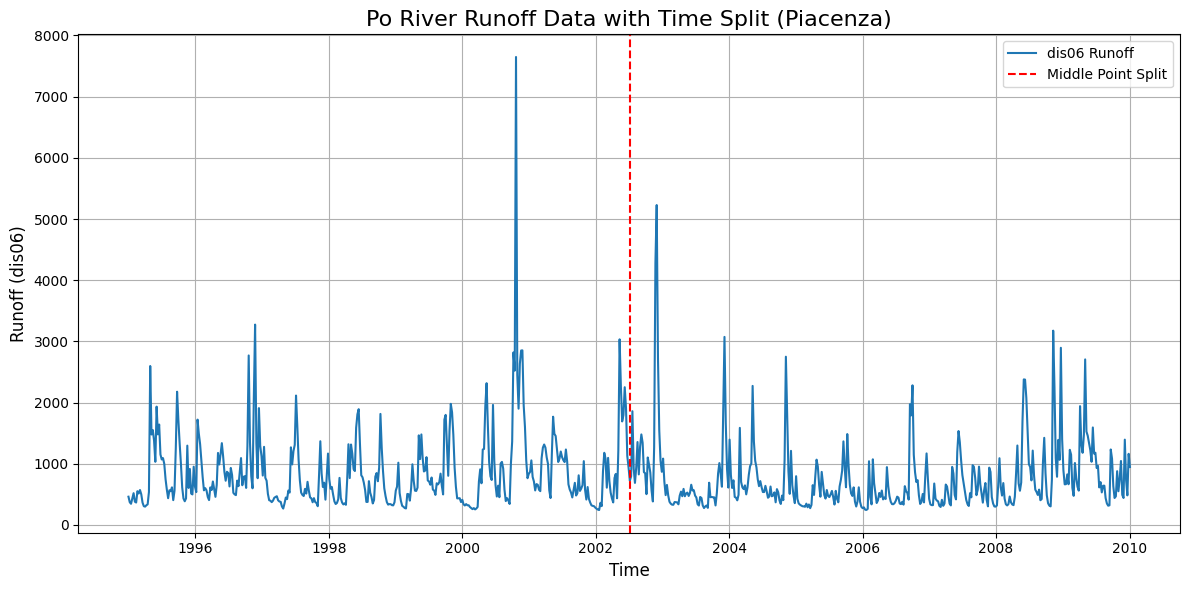

In [ ]:
import matplotlib.pyplot as plt

# Extract the dis06 values and their corresponding valid_time
dis06_values = po_runoff_data['dis06'].values
valid_time = po_runoff_data['valid_time'].values

# Create a line plot
plt.figure(figsize=(12, 6))
plt.plot(valid_time, dis06_values, label='dis06 Runoff')

# Calculate the index of the middle point of the valid_time array
middle_index = len(valid_time) // 2

# Get the valid_time value at this middle index
middle_time = valid_time[middle_index]

# Add a vertical line to the plot at this calculated middle valid_time
plt.axvline(x=middle_time, color='red', linestyle='--', label='Middle Point Split')

# Add title and labels
plt.title('Po River Runoff Data with Time Split (Piacenza)', fontsize=16)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Runoff (dis06)', fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Final Task

### Subtask:
Present the generated plot of the Po river runoff data with the vertical split line.


## Summary:

### Data Analysis Key Findings
*   The longitude and latitude for the 'Po' river's 'Second location' (Piacenza) were identified as 45.059116 latitude and 9.707053 longitude.
*   The nearest grid point in the dataset for these coordinates was found to be at latitude 45.06 and longitude 9.71.
*   Runoff data (dis06) for the 'Po' river at its 'Second location' was successfully extracted and resampled on a weekly basis for the specified period.
*   A time series plot of the extracted Po river runoff data was generated, clearly displaying the runoff values over time.
*   A vertical dashed red line was added to the plot at the temporal midpoint of the time series, effectively splitting the dataset visually.

### Insights or Next Steps
*   The visually split time series provides a clear demarcation for potential comparative analysis of runoff patterns in the first and second halves of the observed period.
*   Further analysis could involve calculating statistical properties (e.g., mean, standard deviation, trends) for the data on either side of the split line to identify significant changes or anomalies over time.


# Task
Calculate and collect the Poisson p-value, Monte Carlo p-value, drought count, flood count, and drought-to-flood count for each river location across the first period (defined by `first_begin` and `first_end` indexes in the `data` xarray Dataset), then display the results in a pandas DataFrame.

## Calculate and Collect Results for First Period

### Subtask:
Iterate through each river and its locations. For each location, find the nearest grid point, call the `drought_flood_p_value_trigger_ECA` function for the first period, and collect the Poisson p-value, Monte Carlo p-value, drought count, flood count, and drought-to-flood count into a list of dictionaries.


**Reasoning**:
The subtask requires iterating through river locations, finding nearest grid points, calling a specific function, and collecting the results into a list of dictionaries. I will create a code block to implement this logic, including error handling and using a safe formatting function for printing results.



In [ ]:
def safe_format(value):
    """Safely format a value as a float with 3 decimals, or return as string if not possible."""
    try:
        return f"{float(value):.3f}"
    except (ValueError, TypeError):
        return str(value)

results_first_period = []

for river in rivers:
    for loc in river['locations']:
        lon = loc['longitude']
        lat = loc['latitude']
        village = loc['village']
        location = loc['river_location']
        river_name = river['river']

        # Find nearest grid point
        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        try:
            (
                p_value_monte_carlo_trigger,
                drought_count,
                flood_count,
                match_counts_array, # Renamed to avoid conflict with the single observed_matches variable
                observed_matches,
                p_value_trigger_poisson,
                p_value_precursor_poisson,
                match_count_trigger,
                match_count_precursor
            ) = drought_flood_p_value_trigger_ECA(
                data, nearest_lon, nearest_lat, first_begin, first_end,
                time_scale, threshold=1, period_after_event=4
            )
        except Exception as e:
            print(f"Error processing {river_name} at {location} ({village}): {e}")
            continue

        results_first_period.append({
            'River': river_name,
            'Village': village,
            'Location': location,
            'Nearest Latitude': nearest_lat,
            'Nearest Longitude': nearest_lon,
            'P-Value Trigger Poisson': p_value_trigger_poisson,
            'P-Value Precursor Poisson': p_value_precursor_poisson,
            'P-Value Monte Carlo Trigger': p_value_monte_carlo_trigger,
            'Drought Count': drought_count,
            'Flood Count': flood_count,
            'Drought-to-Flood Count': observed_matches
        })

        print(
            f"{river_name} ({location}, {village}) - Droughts: {drought_count}, Floods: {flood_count}, "
            f"P_Trigger_Poisson: {safe_format(p_value_trigger_poisson)}, "
            f"P_MC_Trigger: {safe_format(p_value_monte_carlo_trigger)}, "
            f"Matches: {observed_matches}"
        )

Error processing Danube at First location (Aschach an der Donau): not enough values to unpack (expected 9, got 2)
Error processing Danube at Second location (Visegrád): not enough values to unpack (expected 9, got 2)
Error processing Danube at Third location (Donji Milanovac): not enough values to unpack (expected 9, got 2)
Error processing Dnieper at First location (Krementsjoek): not enough values to unpack (expected 9, got 2)
Error processing Dnieper at Second location (Dnipro): not enough values to unpack (expected 9, got 2)
Error processing Dnieper at Third location (Cherson): not enough values to unpack (expected 9, got 2)
Error processing Rhine at First location (Straatsburg): not enough values to unpack (expected 9, got 2)
Error processing Rhine at Second location (Mainz): not enough values to unpack (expected 9, got 2)
Error processing Rhine at Third location (Nijmegen): not enough values to unpack (expected 9, got 2)
Error processing Don at First location (Nikolaevskaya): not